# 01. Data Loading & Understanding

In this section, we load the historical monthly price dataset and perform an
initial inspection to understand its structure, columns, data types, and time range.

The objective is to prepare the dataset for further validation, exploratory data analysis, and forecasting.

In [1]:
# Import required libraries

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

# Visualization style
sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")

Libraries imported successfully!


### 1.1 Load Historical Price Dataset

Load the CSV file containing historical monthly average prices into a Pandas DataFrame

In [2]:
# Load the dataset
df = pd.read_csv(
    "price_data.csv"
)
# Display the first five records
df.head()

,date,avg_monthly_price
0,2005-01-01,5500
1,2005-02-01,5476
2,2005-03-01,5466
3,2005-04-01,5487
4,2005-05-01,5876


### 1.2 Initial Dataset Inspection

Inspect the dataset dimensions, column names, data types, and basic information to understand the available historical data.

In [3]:
# Get describe metrics and separate styling logic safely
summary_df = df.describe(include='all')

print("=== ENHANCED STATISTICAL SUMMARY ===")
# Apply the background gradient only to the numeric column ('avg_monthly_price') and format NaN gracefully via Styler
styled_summary = (summary_df.style
                  .background_gradient(cmap='Blues', subset=['avg_monthly_price'])
                  .format(precision=2, na_rep='-'))
display(styled_summary)

# 2. Key Metrics formatted clearly
print("\n=== KEY DATASET METRICS ===")
metrics_df = pd.DataFrame({
    "Metric": ["Total Records", "Date Range", "Missing Values", "Average Price", "Minimum Price", "Maximum Price"],
    "Value": [
        f"{df.shape[0]} months",
        f"{df['date'].min()} to {df['date'].max()}",
        f"{df.isnull().sum().sum()}",
        f"{df['avg_monthly_price'].mean():,.2f}",
        f"{df['avg_monthly_price'].min():,}",
        f"{df['avg_monthly_price'].max():,}"
    ]
})
display(metrics_df)

=== ENHANCED STATISTICAL SUMMARY ===


,date,avg_monthly_price
count,249,249.00
unique,249,-
top,2005-01-01,-
freq,1,-
mean,-,7918.89
std,-,2804.99
min,-,3500.00
25%,-,6123.00
50%,-,7250.00
75%,-,9783.00



=== KEY DATASET METRICS ===


,Metric,Value
0,Total Records,249 months
1,Date Range,2005-01-01 to 2025-09-01
2,Missing Values,0
3,Average Price,"7,918.89"
4,Minimum Price,"3,500"
5,Maximum Price,"16,163"


### 1.3 Date Conversion and Time-Series Preparation

Convert the date column into Pandas datetime format, sort observations chronologically, and set the date as the DataFrame index.

This allows Pandas to recognize and work with the dataset as a time series.

In [4]:
# Convert date column to datetime
df["date"] = pd.to_datetime(df["date"])
# Sort data chronologically
df = df.sort_values("date")
# Set date as index
df = df.set_index("date")
# Declare the monthly (month-start) frequency explicitly
df = df.asfreq("MS")
# Display the prepared dataset
display(df.head())
print("\nIndex Type:", type(df.index))
print("Date Range:", df.index.min(), "to", df.index.max())

,avg_monthly_price
date,
2005-01-01,5500
2005-02-01,5476
2005-03-01,5466
2005-04-01,5487
2005-05-01,5876



Index Type: <class 'pandas.DatetimeIndex'>
Date Range: 2005-01-01 00:00:00 to 2025-09-01 00:00:00


### 2.1 Missing Value Analysis

Check whether any columns contain missing values. Missing observations can affect statistical analysis and forecasting model performance.

In [5]:
# Check missing values in each column

missing_values = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing_values,
    "Missing Percentage": (
        missing_values / len(df) * 100
    ).round(2)
})

display(missing_summary)

,Missing Values,Missing Percentage
avg_monthly_price,0,0.0


### 2.2 Duplicate Date Validation

Check whether multiple records exist for the same date. Duplicate timestamps can create inconsistencies in monthly time-series analysis.

In [6]:
# Count duplicate dates

duplicate_dates = df.index[df.index.duplicated()]

print("Total Duplicate Dates:", len(duplicate_dates))

if len(duplicate_dates) > 0:
    print("\nDuplicate Dates:")
    display(duplicate_dates.to_frame(index=False))
else:
    print("No duplicate dates found.")

Total Duplicate Dates: 0
No duplicate dates found.


### 2.3 Monthly Frequency Validation

Verify whether the dataset contains a continuous monthly sequence without missing months.

Pandas `asfreq('MS')` creates the expected month-start date index between the first and last observations. Missing months appear as NaN.

In [7]:
# Generate expected monthly frequency

expected_index = pd.date_range(
    start=df.index.min(),
    end=df.index.max(),
    freq="MS"
)

# Reindex using expected monthly dates
monthly_check = df.asfreq("MS")
print("Monthly Frequency:", df.index.freq)

# Identify missing months
missing_months = monthly_check[
    monthly_check["avg_monthly_price"].isna()
]

print("Expected Monthly Observations:", len(expected_index))
print("Actual CSV Rows:", len(df))
print("Missing Months:", len(missing_months))

if len(missing_months) > 0:
    print("\nMissing Month Dates:")
    display(missing_months)
else:
    print("\nNo missing months found.")

Monthly Frequency: <MonthBegin>
Expected Monthly Observations: 249
Actual CSV Rows: 249
Missing Months: 0

No missing months found.


### 2.4 Data Validation Summary

Summarize the validation results to confirm whether the dataset is structurally ready for exploratory analysis.

In [8]:
# Final data validation summary

validation_summary = pd.DataFrame({
    "Metric": [
        "Expected Monthly Observations",
        "Actual CSV Rows",
        "Missing Values",
        "Missing Months",
        "Duplicate Dates"
    ],
    "Result": [
        len(expected_index),
        len(df),
        int(df.isnull().sum().sum()),
        len(missing_months),
        len(duplicate_dates)
    ]
})

display(validation_summary)

,Metric,Result
0,Expected Monthly Observations,249
1,Actual CSV Rows,249
2,Missing Values,0
3,Missing Months,0
4,Duplicate Dates,0


### 3.1 Historical Price Trend – Original Dataset

Visualize the original monthly average prices over time to understand the overall historical movement, long-term direction, and major fluctuations.

This visualization provides an initial understanding of the price behaviour before performing any data cleaning.

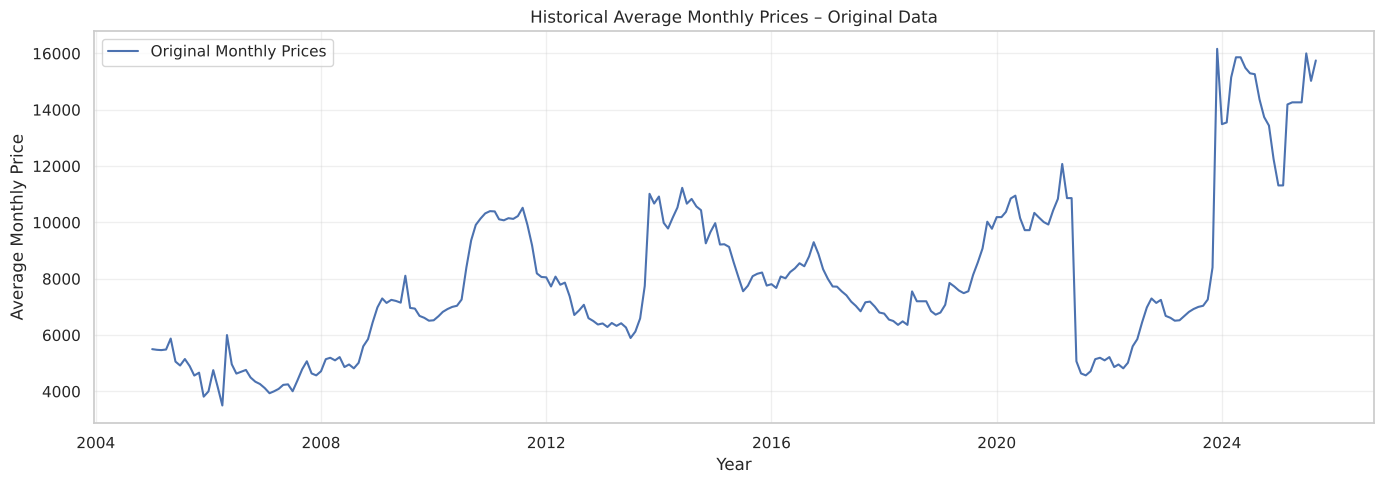

In [9]:
plt.figure(figsize=(14, 5))

plt.plot(
    df.index,
    df["avg_monthly_price"],
    label="Original Monthly Prices",
    linewidth=1.5
)

plt.title("Historical Average Monthly Prices – Original Data")
plt.xlabel("Year")
plt.ylabel("Average Monthly Price")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3.2 Rolling Average Analysis

Calculate rolling averages over 3, 6, and 12 months to understand price movements at different time scales.

Shorter windows capture relatively quick changes, while longer windows smooth short-term fluctuations and reveal broader trends.

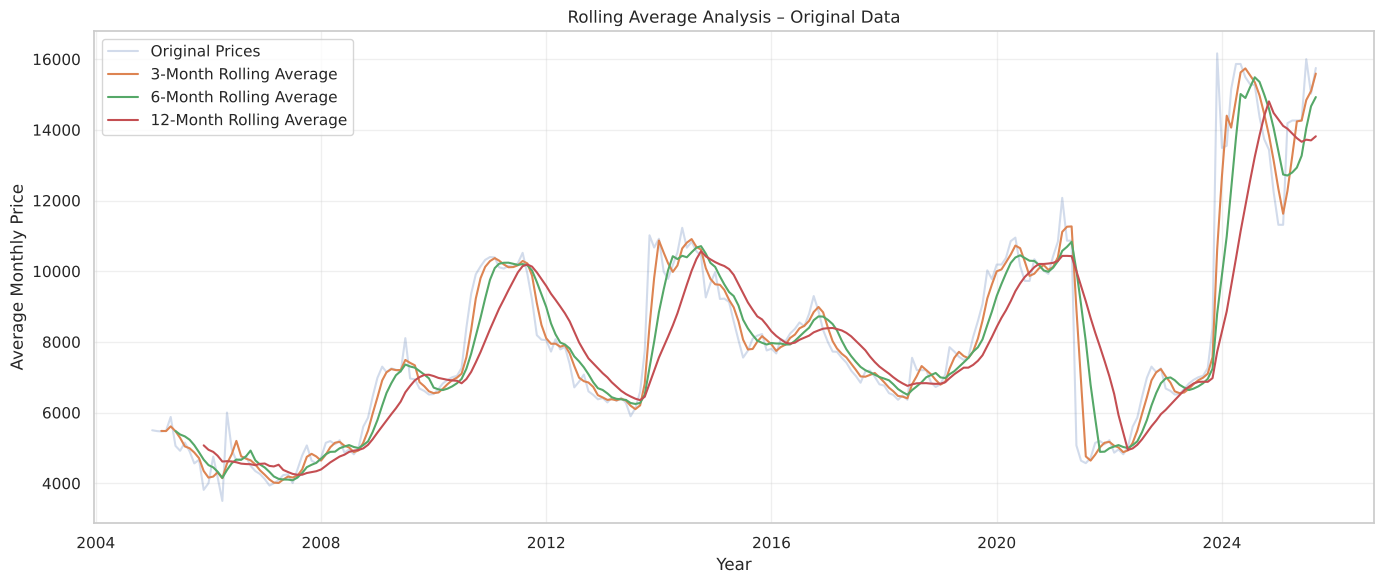

In [10]:
# Calculate rolling averages
rolling_3 = df["avg_monthly_price"].rolling(window=3).mean()
rolling_6 = df["avg_monthly_price"].rolling(window=6).mean()
rolling_12 = df["avg_monthly_price"].rolling(window=12).mean()

# Plot rolling averages
plt.figure(figsize=(14, 6))

plt.plot(df.index, df["avg_monthly_price"], alpha=0.25, label="Original Prices")
plt.plot(df.index, rolling_3, label="3-Month Rolling Average")
plt.plot(df.index, rolling_6, label="6-Month Rolling Average")
plt.plot(df.index, rolling_12, label="12-Month Rolling Average")

plt.title("Rolling Average Analysis – Original Data")
plt.xlabel("Year")
plt.ylabel("Average Monthly Price")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3.3 Monthly Price Distribution

Analyze the distribution of prices across the 12 calendar months using a box plot.

This helps investigate whether certain months tend to have consistently higher or lower prices and whether recurring monthly patterns may exist.

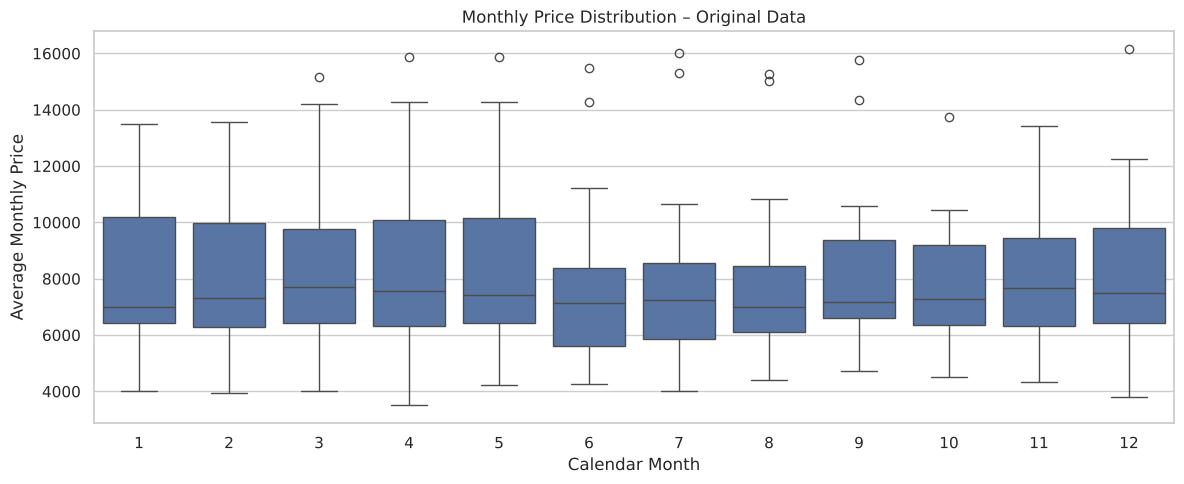

In [11]:
# Create a temporary DataFrame for monthly analysis
monthly_eda = df.copy()
# Extract calendar month
monthly_eda["month"] = monthly_eda.index.month
# Plot monthly price distribution
plt.figure(figsize=(12, 5))
sns.boxplot(
    data=monthly_eda,
    x="month",
    y="avg_monthly_price"
)
plt.title("Monthly Price Distribution – Original Data")
plt.xlabel("Calendar Month")
plt.ylabel("Average Monthly Price")

plt.tight_layout()
plt.show()

### 3.4 Month-over-Month Price Changes

Calculate the percentage change between consecutive monthly observations.

This helps identify sudden price increases and decreases and understand short-term price volatility.

Month-over-Month Percentage Change


,MoM Change (%)
count,248.000000
mean,0.903788
std,10.470026
min,-53.327810
25%,-2.544049
50%,0.000000
75%,3.217234
max,92.416667


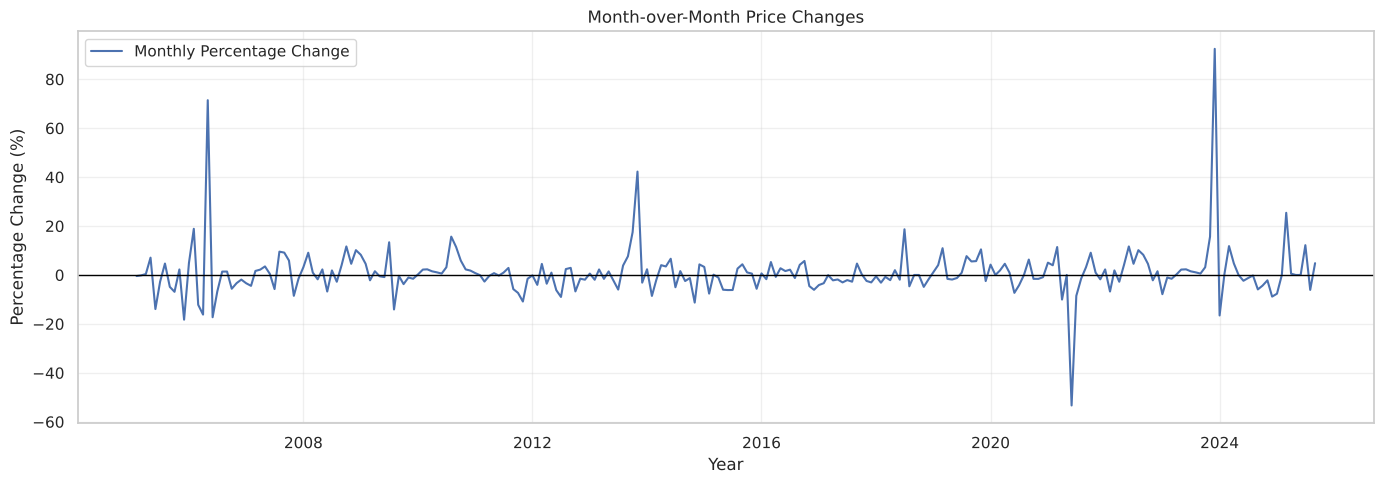

In [12]:
# Calculate month-over-month percentage change
mom_change = df.pct_change() * 100

# Display summary statistics
print("Month-over-Month Percentage Change")
# Select the column series first to apply .to_frame() and rename it
display(mom_change["avg_monthly_price"].describe().to_frame(name="MoM Change (%)"))

# Plot percentage changes
plt.figure(figsize=(14, 5))

plt.plot(mom_change.index, mom_change["avg_monthly_price"], label="Monthly Percentage Change")

plt.axhline(0, color='black', linewidth=1)
plt.title("Month-over-Month Price Changes")
plt.xlabel("Year")
plt.ylabel("Percentage Change (%)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 3.5 Year-over-Year Price Changes

Calculate the percentage change compared with the same month in the previous year.

This helps identify annual price movements and provides another perspective on long-term growth and fluctuations.

Year-over-Year Percentage Change


,YoY Change (%)
count,237.000000
mean,11.100523
std,37.665574
min,-58.956522
25%,-14.983051
50%,2.326266
75%,32.981057
max,143.111111


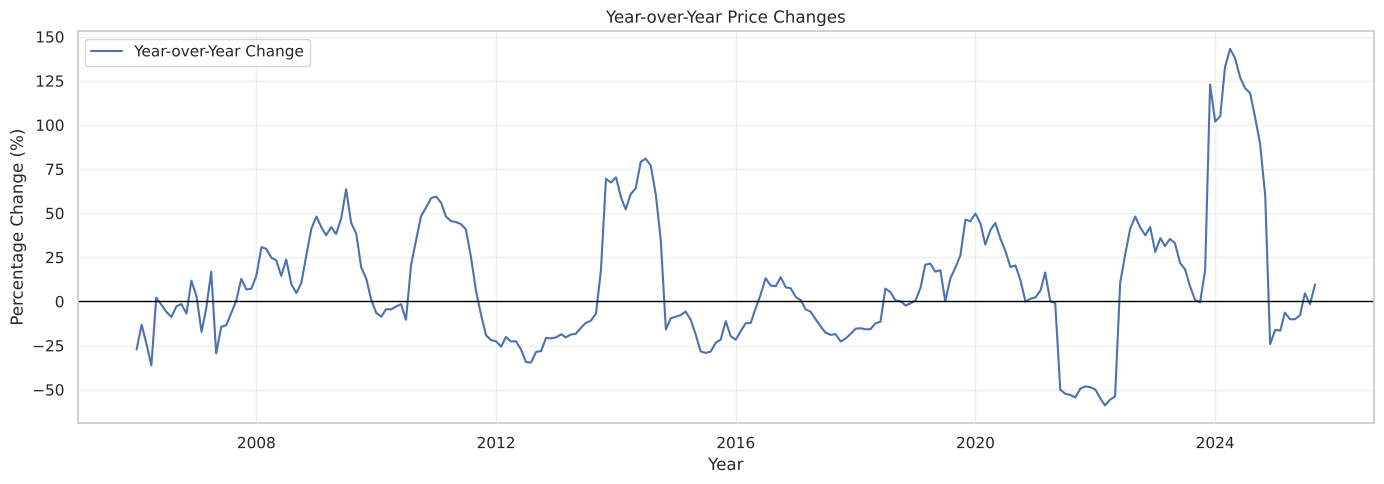

In [13]:
# Calculate year-over-year percentage change
yoy_change = df["avg_monthly_price"].pct_change(periods=12) * 100

# Display summary
print("Year-over-Year Percentage Change")
display(yoy_change.describe().to_frame(name="YoY Change (%)"))

# Plot YoY changes
plt.figure(figsize=(14, 5))

plt.plot(yoy_change.index, yoy_change, label="Year-over-Year Change")

plt.axhline(0, color='black', linewidth=1)
plt.title("Year-over-Year Price Changes")
plt.xlabel("Year")
plt.ylabel("Percentage Change (%)")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.1 Sudden Price Movement Detection

Calculate month-over-month percentage changes to identify unusually large increases and decreases in historical prices.

Observations exceeding a 20% absolute monthly change are flagged for further investigation. These observations are treated as potential anomalies, not automatically classified as incorrect data.

In [14]:
# Calculate month-over-month percentage changes
mom_change = df["avg_monthly_price"].pct_change() * 100

# Define threshold for investigation
change_threshold = 20

# Identify unusually large monthly movements
sudden_movements = mom_change[
    mom_change.abs() > change_threshold
]

# Create evidence table
movement_report = pd.DataFrame({
    "Previous Price": df["avg_monthly_price"].shift(1),
    "Current Price": df["avg_monthly_price"],
    "Percentage Change (%)": mom_change
}).loc[sudden_movements.index]

# Sort by magnitude of percentage change
movement_report = movement_report.reindex(
    movement_report["Percentage Change (%)"]
    .abs()
    .sort_values(ascending=False)
    .index
)

print("Total suspicious monthly movements:", len(movement_report))

display(movement_report.round(2))

Total suspicious monthly movements: 5


,Previous Price,Current Price,Percentage Change (%)
date,,,
2023-12-01,8400.0,16163,92.42
2006-05-01,3500.0,6000,71.43
2021-06-01,10863.0,5070,-53.33
2013-11-01,7744.0,11016,42.25
2025-03-01,11313.0,14188,25.41


### 4.2 Consecutive Repeated Price Detection

Identify consecutive months with exactly identical average prices.

Repeated values may indicate unchanged market prices or values carried forward during data reporting. These observations are flagged for investigation rather than automatically removed.

In [15]:
# Select the average monthly price series
price_series = df["avg_monthly_price"]

# Create a detailed comparison table
repeated_report = pd.DataFrame({
    "Previous Month": price_series.index.to_series().shift(1),
    "Previous Price": price_series.shift(1),
    "Current Month": price_series.index,
    "Current Price": price_series,
    "Percentage Change (%)": price_series.pct_change() * 100
}, index=price_series.index)

# Keep only consecutive identical prices
repeated_report = repeated_report[
    price_series.eq(price_series.shift(1))
]

# Format month columns
repeated_report["Previous Month"] = (
    repeated_report["Previous Month"].dt.strftime("%b %Y")
)

repeated_report["Current Month"] = (
    repeated_report["Current Month"].dt.strftime("%b %Y")
)

print("Total Consecutive Repeated Price Observations:",
      len(repeated_report))

display(repeated_report.round(2).reset_index(drop=True))

Total Consecutive Repeated Price Observations: 9


,Previous Month,Previous Price,Current Month,Current Price,Percentage Change (%)
0,Aug 2018,7200.0,Sep 2018,7200,0.0
1,Sep 2018,7200.0,Oct 2018,7200,0.0
2,Jan 2020,10188.0,Feb 2020,10188,0.0
3,Jul 2020,9725.0,Aug 2020,9725,0.0
4,Apr 2021,10863.0,May 2021,10863,0.0
5,Apr 2024,15863.0,May 2024,15863,0.0
6,Jan 2025,11313.0,Feb 2025,11313,0.0
7,Apr 2025,14263.0,May 2025,14263,0.0
8,May 2025,14263.0,Jun 2025,14263,0.0


### 4.3 Exact Copied-Block Detection

Investigate whether consecutive sequences of monthly average prices are repeated elsewhere in the historical dataset.

A sliding window of six months is used to compare consecutive price sequences. Exact matches are identified and grouped into longer repeated blocks.

This helps detect potential copied historical data that may distort forecasting model training.

In [16]:
# Select historical price values and dates
prices = df["avg_monthly_price"].to_numpy()
dates = df.index

# Define sliding window size
window_size = 6

# Store previously observed sequences
sequence_map = {}

# Store matching source and repeated positions
matching_pairs = []

# Slide through the historical prices
for i in range(len(prices) - window_size + 1):

    # Extract six consecutive prices
    sequence = tuple(prices[i:i + window_size])

    # Check whether this sequence appeared earlier
    previous_positions = sequence_map.get(sequence, [])

    for previous_i in previous_positions:

        # Avoid overlapping windows
        if i - previous_i >= window_size:

            matching_pairs.append((previous_i, i))

    # Store current sequence position
    sequence_map.setdefault(sequence, []).append(i)


# Group overlapping matches into longer repeated blocks
matching_set = set(matching_pairs)
copied_blocks = []

for source_i, repeated_i in sorted(matching_set):

    # Start a new block if the preceding pair does not exist
    if (source_i - 1, repeated_i - 1) not in matching_set:

        length = window_size

        # Extend while both sequences continue matching
        while (
            (source_i + length - window_size + 1,
             repeated_i + length - window_size + 1)
            in matching_set
        ):
            length += 1

        copied_blocks.append({
            "Original Start": dates[source_i],
            "Original End": dates[source_i + length - 1],
            "Repeated Start": dates[repeated_i],
            "Repeated End": dates[repeated_i + length - 1],
            "Matching Months": length
        })


# Display evidence
copied_blocks_df = pd.DataFrame(copied_blocks)

print("Total matching six-month windows:", len(matching_pairs))
print("Total repeated blocks identified:", len(copied_blocks_df))

display(copied_blocks_df)

Total matching six-month windows: 20
Total repeated blocks identified: 2


,Original Start,Original End,Repeated Start,Repeated End,Matching Months
0,2007-10-01,2009-04-01,2021-06-01,2022-12-01,19
1,2009-10-01,2010-08-01,2023-01-01,2023-11-01,11


### 4.4 Copied-Block Verification and Continuity Check

Verify that the detected original and repeated sequences contain continuous monthly observations and that every corresponding price matches exactly.

Additionally, identify any gaps between separate detected blocks to ensure that the evidence table accurately represents the copied periods.

In [17]:
# Verify every detected copied block

verification_results = []

for _, block in copied_blocks_df.iterrows():

    original = df.loc[
        block["Original Start"]:block["Original End"],
        "avg_monthly_price"
    ]

    repeated = df.loc[
        block["Repeated Start"]:block["Repeated End"],
        "avg_monthly_price"
    ]

    # Check expected monthly dates
    original_expected = pd.date_range(
        block["Original Start"],
        block["Original End"],
        freq="MS"
    )

    repeated_expected = pd.date_range(
        block["Repeated Start"],
        block["Repeated End"],
        freq="MS"
    )

    original_continuous = original.index.equals(original_expected)
    repeated_continuous = repeated.index.equals(repeated_expected)

    # Check exact price equality
    exact_match = (
        len(original) == len(repeated)
        and np.array_equal(
            original.to_numpy(),
            repeated.to_numpy()
        )
    )

    verification_results.append({
        "Original Period": (
            f"{block['Original Start']:%b %Y} – "
            f"{block['Original End']:%b %Y}"
        ),
        "Repeated Period": (
            f"{block['Repeated Start']:%b %Y} – "
            f"{block['Repeated End']:%b %Y}"
        ),
        "Original Months": len(original),
        "Repeated Months": len(repeated),
        "Original Continuous": original_continuous,
        "Repeated Continuous": repeated_continuous,
        "Exact Price Match": exact_match
    })

verification_df = pd.DataFrame(verification_results)

display(verification_df)

,Original Period,Repeated Period,Original Months,Repeated Months,Original Continuous,Repeated Continuous,Exact Price Match
0,Oct 2007 – Apr 2009,Jun 2021 – Dec 2022,19,19,True,True,True
1,Oct 2009 – Aug 2010,Jan 2023 – Nov 2023,11,11,True,True,True


### 4.5 Data Cleaning and Preprocessing

Based on the anomaly investigation, two historical sequences containing 30 observations were identified as exact matches of earlier price sequences.

In this section, I create a separate working copy of the original dataset and mark the verified repeated periods for further treatment.

The original dataset remains unchanged to maintain data integrity and ensure reproducibility.

In [18]:
# Create a separate working copy
clean_df = df.copy()

# Initialize a mask for suspected copied observations
copied_mask = pd.Series(
    False,
    index=clean_df.index
)

# Identify repeated periods from the verification table
for _, block in copied_blocks_df.iterrows():

    repeated_start = block["Repeated Start"]
    repeated_end = block["Repeated End"]

    # Mark only the later repeated observations
    copied_mask.loc[repeated_start:repeated_end] = True


# Create a cleaning audit table
cleaning_audit = pd.DataFrame({
    "Original Price": clean_df["avg_monthly_price"],
    "Suspected Copied Block": copied_mask
})

# Count flagged observations
print("Total suspected copied observations:",
      int(copied_mask.sum()))

print("Original dataset rows:", len(df))
print("Working dataset rows:", len(clean_df))

# Display flagged observations
display(
    cleaning_audit[cleaning_audit["Suspected Copied Block"]]
)

Total suspected copied observations: 30
Original dataset rows: 249
Working dataset rows: 249


,Original Price,Suspected Copied Block
date,,
2021-06-01,5070,True
2021-07-01,4638,True
2021-08-01,4569,True
2021-09-01,4715,True
2021-10-01,5144,True
2021-11-01,5194,True
2021-12-01,5102,True
2022-01-01,5218,True
2022-02-01,4865,True


### 4.5.2 Handling Copied Observations Using Logarithmic Interpolation

The 30 observations identified as suspected copied historical data are treated as missing values.

To preserve the continuous monthly timeline, these observations are estimated using time-based interpolation on the logarithmic price scale.

This approach estimates prices using proportional changes between surrounding valid observations while retaining all original monthly timestamps.

The interpolated values are estimates and should not be interpreted as actual historical prices.

In [19]:
# Preserve the original price values for auditing
clean_df["original_price"] = df["avg_monthly_price"]

# Replace suspected copied observations with NaN
clean_df.loc[
    copied_mask,
    "avg_monthly_price"
] = np.nan

# Count missing observations before interpolation
missing_before = clean_df["avg_monthly_price"].isna().sum()

# Perform logarithmic interpolation
log_prices = np.log(clean_df["avg_monthly_price"])

interpolated_log_prices = log_prices.interpolate(
    method="time",
    limit_area="inside"
)

# Convert estimated values back to original price scale
clean_df["avg_monthly_price"] = np.exp(
    interpolated_log_prices
)

# Count missing observations after interpolation
missing_after = clean_df["avg_monthly_price"].isna().sum()

# Create interpolation audit
interpolation_report = pd.DataFrame({
    "Original Price": clean_df["original_price"],
    "Cleaned Price": clean_df["avg_monthly_price"],
    "Was Interpolated": copied_mask
})

print("Missing observations before interpolation:", missing_before)
print("Missing observations after interpolation:", missing_after)

print("Interpolated observations:",
      int(interpolation_report["Was Interpolated"].sum()))

# Display all 30 interpolated observations
display(
    interpolation_report[
        interpolation_report["Was Interpolated"]
    ].round(2)
)

Missing observations before interpolation: 30
Missing observations after interpolation: 0
Interpolated observations: 30


,Original Price,Cleaned Price,Was Interpolated
date,,,
2021-06-01,5070,11005.68,True
2021-07-01,4638,11145.54,True
2021-08-01,4569,11291.93,True
2021-09-01,4715,11440.25,True
2021-10-01,5144,11585.63,True
2021-11-01,5194,11737.80,True
2021-12-01,5102,11886.97,True
2022-01-01,5218,12043.10,True
2022-02-01,4865,12201.27,True


### 4.5.3 Original vs Cleaned Price Comparison

Visualize the original and cleaned monthly price series to evaluate the impact of replacing the suspected copied observations.

The affected period is highlighted to distinguish original copied values from logarithmically interpolated estimates.

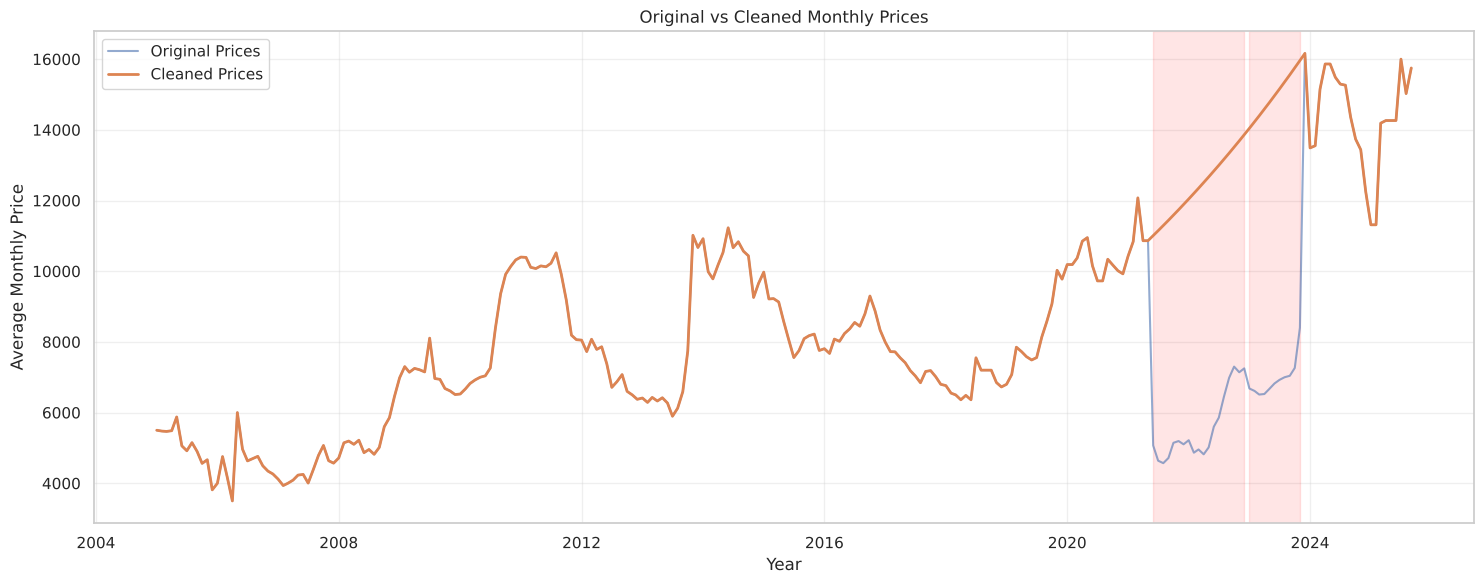

In [20]:
# Compare original and cleaned prices

plt.figure(figsize=(15, 6))

plt.plot(
    df.index,
    df["avg_monthly_price"],
    label="Original Prices",
    alpha=0.6
)

plt.plot(
    clean_df.index,
    clean_df["avg_monthly_price"],
    label="Cleaned Prices",
    linewidth=2
)

# Highlight copied-data periods
for _, block in copied_blocks_df.iterrows():
    plt.axvspan(
        block["Repeated Start"],
        block["Repeated End"],
        color="red",
        alpha=0.10
    )

plt.title("Original vs Cleaned Monthly Prices")
plt.xlabel("Year")
plt.ylabel("Average Monthly Price")

plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.5.4 Comparison of Linear and Logarithmic Interpolation

Evaluate two interpolation techniques for estimating the 30 suspected copied observations.

Linear interpolation estimates missing prices using constant absolute changes, whereas logarithmic interpolation estimates them using constant proportional changes.

Both methods are applied to the same missing observations. Their estimated values and differences are compared to understand the impact of the interpolation strategy.

This comparison evaluates the assumptions and behaviour of each method; it does not establish which estimates are historically accurate.

In [21]:
# Start with the original price series
original_prices = df["avg_monthly_price"].astype(float)

# Mark suspected copied observations as missing
prices_with_gaps = original_prices.mask(copied_mask)

# 1. Linear interpolation
linear_interpolated = prices_with_gaps.interpolate(
    method="time",
    limit_area="inside"
)

# 2. Logarithmic interpolation
log_interpolated = np.exp(
    np.log(prices_with_gaps).interpolate(
        method="time",
        limit_area="inside"
    )
)

# Create comparison table for the 30 affected observations
interpolation_comparison = pd.DataFrame({
    "Original Copied Price": original_prices[copied_mask],
    "Linear Estimate": linear_interpolated[copied_mask],
    "Log Estimate": log_interpolated[copied_mask]
})

# Calculate difference between methods
interpolation_comparison["Absolute Difference"] = (
    interpolation_comparison["Linear Estimate"]
    - interpolation_comparison["Log Estimate"]
).abs()

interpolation_comparison["Percentage Difference (%)"] = (
    interpolation_comparison["Absolute Difference"]
    / interpolation_comparison["Log Estimate"]
) * 100

# Display all 30 observations
display(interpolation_comparison.round(2))

,Original Copied Price,Linear Estimate,Log Estimate,Absolute Difference,Percentage Difference (%)
date,,,,,
2021-06-01,5070.0,11037.05,11005.68,31.37,0.29
2021-07-01,4638.0,11205.48,11145.54,59.94,0.54
2021-08-01,4569.0,11379.53,11291.93,87.59,0.78
2021-09-01,4715.0,11553.57,11440.25,113.33,0.99
2021-10-01,5144.0,11722.00,11585.63,136.37,1.18
2021-11-01,5194.0,11896.05,11737.80,158.25,1.35
2021-12-01,5102.0,12064.48,11886.97,177.52,1.49
2022-01-01,5218.0,12238.53,12043.10,195.43,1.62
2022-02-01,4865.0,12412.58,12201.27,211.30,1.73


In [22]:
# Compare the two interpolation methods

comparison_metrics = pd.DataFrame({
    "Metric": [
        "Total Estimated Observations",
        "Mean Linear Estimate",
        "Mean Logarithmic Estimate",
        "Mean Absolute Difference",
        "Maximum Absolute Difference",
        "Mean Percentage Difference"
    ],

    "Result": [
        int(copied_mask.sum()),
        linear_interpolated[copied_mask].mean(),
        log_interpolated[copied_mask].mean(),
        interpolation_comparison["Absolute Difference"].mean(),
        interpolation_comparison["Absolute Difference"].max(),
        interpolation_comparison["Percentage Difference (%)"].mean()
    ]
})

display(comparison_metrics.round(2))

,Metric,Result
0,Total Estimated Observations,30.00
1,Mean Linear Estimate,13514.87
2,Mean Logarithmic Estimate,13333.99
3,Mean Absolute Difference,180.88
4,Maximum Absolute Difference,262.68
5,Mean Percentage Difference,1.37


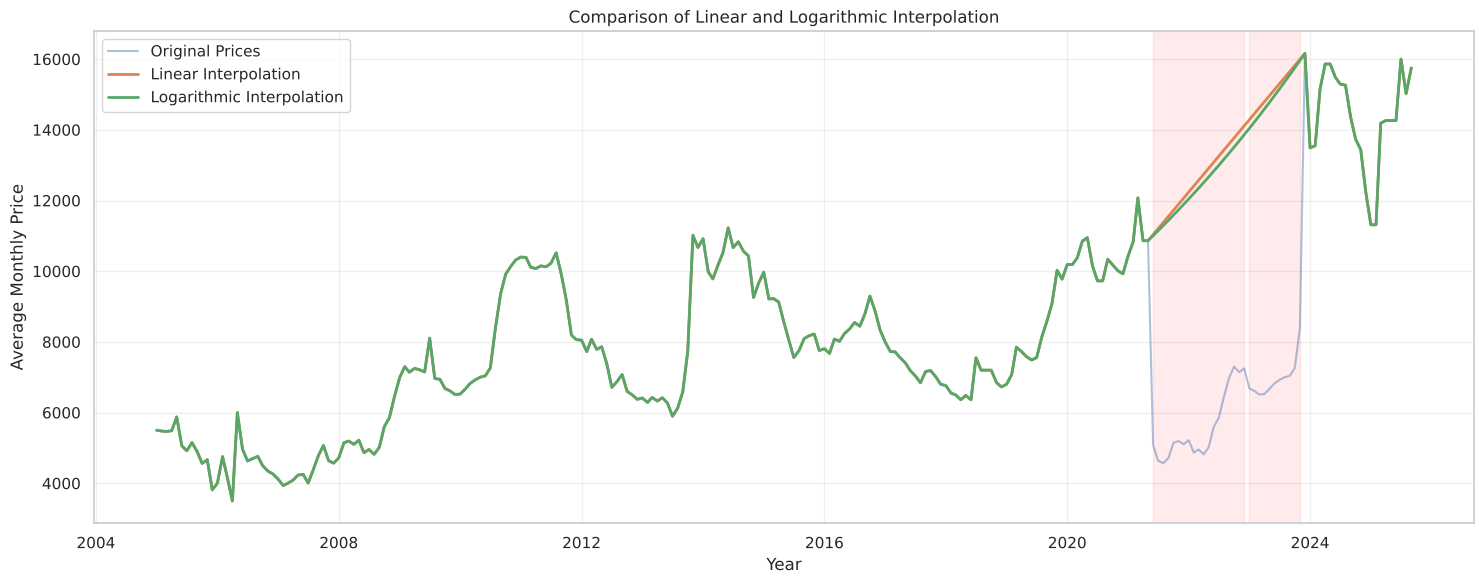

In [23]:
plt.figure(figsize=(15, 6))

# Original data
plt.plot(
    original_prices.index,
    original_prices,
    label="Original Prices",
    alpha=0.45
)

# Linear interpolation
plt.plot(
    linear_interpolated.index,
    linear_interpolated,
    label="Linear Interpolation",
    linewidth=2
)

# Logarithmic interpolation
plt.plot(
    log_interpolated.index,
    log_interpolated,
    label="Logarithmic Interpolation",
    linewidth=2
)

# Highlight copied periods
for _, block in copied_blocks_df.iterrows():
    plt.axvspan(
        block["Repeated Start"],
        block["Repeated End"],
        color="red",
        alpha=0.08
    )

plt.title("Comparison of Linear and Logarithmic Interpolation")
plt.xlabel("Year")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 4.5.5 Finalize the Cleaned Dataset

Based on the comparison of linear and logarithmic interpolation, logarithmic interpolation is selected as the primary preprocessing approach.

The method estimates the 30 suspected copied observations using proportional changes while preserving the original monthly timeline.

The finalized candidate dataset is retained separately from the original data to ensure reproducibility and enable further validation.

In [24]:
# Create a fresh working copy
clean_df = df.copy()

# Convert price column to float for interpolated values
clean_df["avg_monthly_price"] = (
    clean_df["avg_monthly_price"].astype(float)
)

# Preserve original prices
clean_df["original_price"] = df["avg_monthly_price"].copy()

# Replace only the 30 suspected copied observations
clean_df.loc[
    copied_mask,
    "avg_monthly_price"
] = log_interpolated.loc[copied_mask]


# Final validation
unchanged_mask = ~copied_mask

print("FINAL CLEANING SUMMARY")
print("-" * 35)

print("Original observations:", len(df))
print("Cleaned observations:", len(clean_df))
print("Interpolated observations:", int(copied_mask.sum()))

print(
    "Remaining missing values:",
    clean_df["avg_monthly_price"].isna().sum()
)

print(
    "Unaffected original values preserved:",
    np.array_equal(
        df.loc[unchanged_mask, "avg_monthly_price"].to_numpy(),
        clean_df.loc[unchanged_mask, "avg_monthly_price"].to_numpy()
    )
)

print(
    "Original dataset unchanged:",
    df["avg_monthly_price"].equals(
        clean_df["original_price"]
    )
)

print("Cleaned column dtype:", clean_df["avg_monthly_price"].dtype)

display(clean_df["avg_monthly_price"].describe().round(2))

FINAL CLEANING SUMMARY
-----------------------------------
Original observations: 249
Cleaned observations: 249
Interpolated observations: 30
Remaining missing values: 0
Unaffected original values preserved: True
Original dataset unchanged: True
Cleaned column dtype: float64


count      249.00
mean      8793.14
std       3220.28
min       3500.00
25%       6510.00
50%       8050.00
75%      10670.00
max      16163.00
Name: avg_monthly_price, dtype: float64

#### 4.6.1 Calculate Rolling Median

The rolling median captures the local price trend over a moving window.
We use a 12-month window to compare each observation with its recent
historical behaviour.

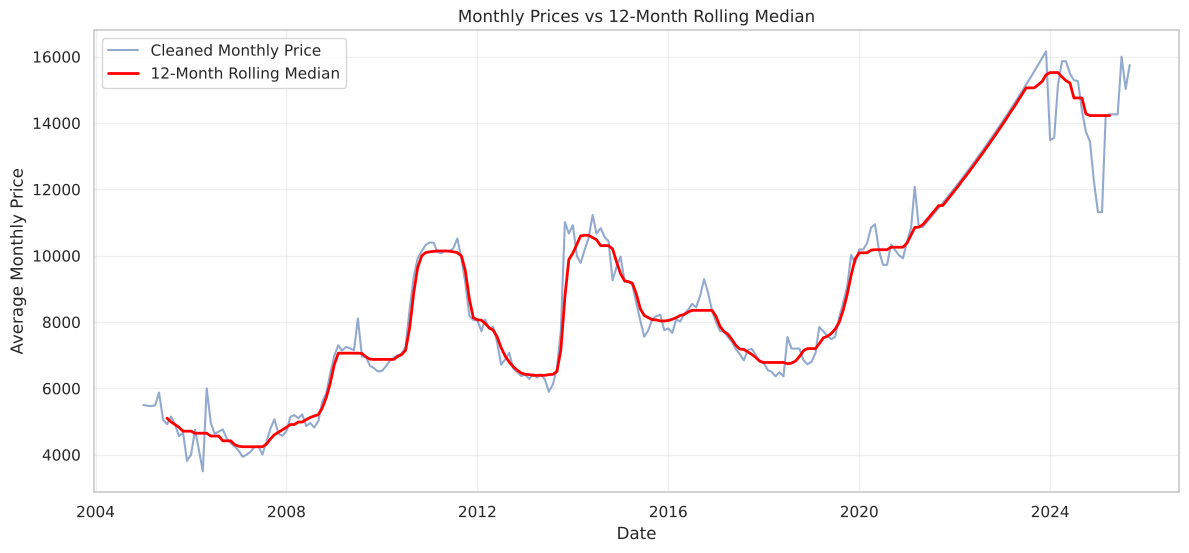

In [25]:
# Extract the cleaned price series
price_series = clean_df["avg_monthly_price"]

# Calculate the rolling median using a 12-month window
rolling_median = price_series.rolling(
    window=12,
    min_periods=12,
    center=True
).median()

# Visualize the price series and rolling median
plt.figure(figsize=(14, 6))

plt.plot(
    price_series.index,
    price_series,
    label="Cleaned Monthly Price",
    alpha=0.6
)

plt.plot(
    rolling_median.index,
    rolling_median,
    color="red",
    linewidth=2,
    label="12-Month Rolling Median"
)

plt.title("Monthly Prices vs 12-Month Rolling Median")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### 4.6.2 Calculate Rolling Median Absolute Deviation (MAD)

Median Absolute Deviation measures how far observations typically
deviate from their local median.

The MAD is computed **inside each 12-month window** (median of the
absolute deviations from that window's own median), which is the exact
definition. Undefined scores (MAD = 0) are set to NaN rather than being
treated as outliers.


In [26]:
# Exact rolling MAD: computed within each 12-month window
def calculate_mad(values):
    window_median = np.median(values)
    return np.median(np.abs(values - window_median))

rolling_mad = price_series.rolling(
    window=12,
    min_periods=12,
    center=True
).apply(calculate_mad, raw=True)

# Robust Z-score (0.6745 scales MAD to the standard deviation of a normal distribution)
robust_z_score = (
    0.6745 * (price_series - rolling_median) / rolling_mad
)

# Avoid treating undefined scores as outliers
robust_z_score = robust_z_score.replace([np.inf, -np.inf], np.nan)

# Display the results
mad_results = pd.DataFrame({
    "Actual Price": price_series,
    "Rolling Median": rolling_median,
    "Rolling MAD": rolling_mad,
    "Robust Z-Score": robust_z_score
})

display(mad_results.dropna().head(10).round(2))


,Actual Price,Rolling Median,Rolling MAD,Robust Z-Score
date,,,,
2005-07-01,4919.0,5103.5,378.0,-0.33
2005-08-01,5149.0,4988.5,452.0,0.24
2005-09-01,4899.0,4909.0,295.5,-0.02
2005-10-01,4562.0,4827.0,293.5,-0.61
2005-11-01,4665.0,4710.0,393.5,-0.08
2005-12-01,3813.0,4710.0,393.5,-1.54
2006-01-01,4000.0,4710.0,346.5,-1.38
2006-02-01,4755.0,4648.5,394.0,0.18
2006-03-01,4176.0,4648.5,283.0,-1.13


#### 4.6.3 Identify Potential Outliers

We flag observations whose absolute robust Z-score exceeds 3.5.

This is a screening threshold, not proof that an observation is incorrect.

In [27]:
# Define the anomaly threshold
mad_threshold = 3.5

# Identify potential outliers
outlier_mask = robust_z_score.abs() > mad_threshold

# Create an outlier report
outlier_report = mad_results.loc[outlier_mask].copy()

# Display the results
print("Potential outliers detected:", len(outlier_report))

display(outlier_report.round(2))

Potential outliers detected: 5


,Actual Price,Rolling Median,Rolling MAD,Robust Z-Score
date,,,,
2006-04-01,3500.0,4648.50,214.50,-3.61
2006-05-01,6000.0,4648.50,235.00,3.88
2009-07-01,8106.0,7061.50,169.50,4.16
2024-01-01,13488.0,15521.79,354.07,-3.87
2024-02-01,13550.0,15521.79,341.21,-3.90


#### 4.6.4 Visualize Potential Outliers

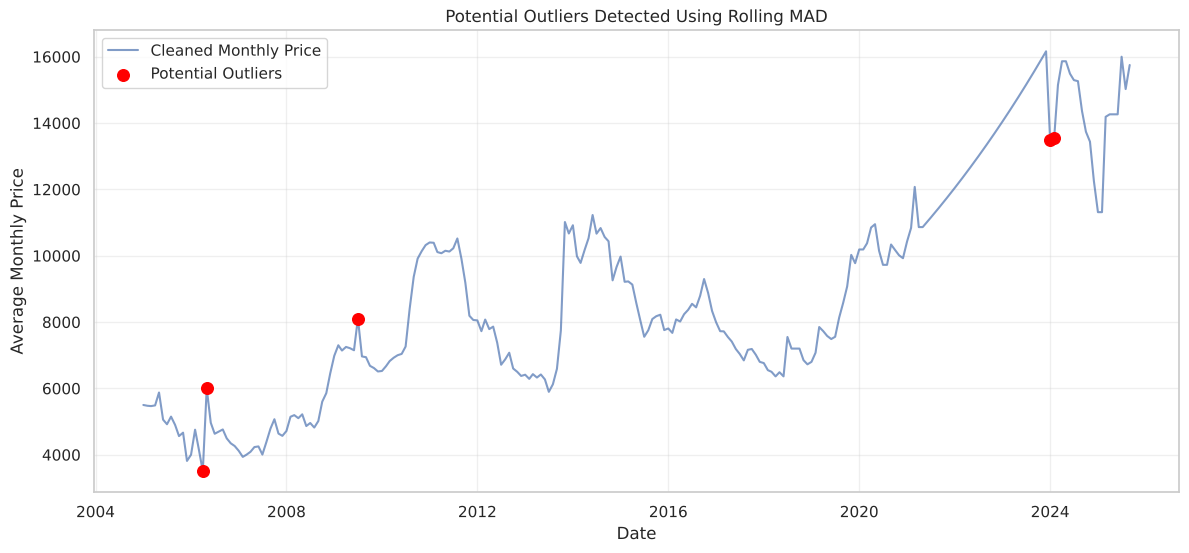

In [28]:
plt.figure(figsize=(14, 6))

plt.plot(
    price_series.index,
    price_series,
    label="Cleaned Monthly Price",
    alpha=0.7
)

plt.scatter(
    outlier_report.index,
    outlier_report["Actual Price"],
    color="red",
    s=70,
    label="Potential Outliers",
    zorder=3
)

plt.title("Potential Outliers Detected Using Rolling MAD")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### 4.6.5 Investigate Potential Outliers

We compare each flagged observation with its neighbouring months
and check whether it was interpolated during data cleaning.

This helps distinguish genuine price movements from possible
data-quality issues.

In [29]:
# Build an investigation report for flagged observations
monthly_change = clean_df["avg_monthly_price"].pct_change() * 100

outlier_investigation = pd.DataFrame({
    "Original Price": df["avg_monthly_price"],
    "Cleaned Price": clean_df["avg_monthly_price"],
    "Previous Month Price": clean_df["avg_monthly_price"].shift(1),
    "Next Month Price": clean_df["avg_monthly_price"].shift(-1),
    "Monthly Change (%)": monthly_change,
    "Robust Z-Score": robust_z_score,
    "Was Interpolated": copied_mask
})

# Keep only potential outliers (same mask as section 4.6.3)
outlier_investigation = outlier_investigation.loc[outlier_mask]

display(outlier_investigation.round(2))


,Original Price,Cleaned Price,Previous Month Price,Next Month Price,Monthly Change (%),Robust Z-Score,Was Interpolated
date,,,,,,,
2006-04-01,3500,3500.0,4176.0,6000.0,-16.19,-3.61,False
2006-05-01,6000,6000.0,3500.0,4964.0,71.43,3.88,False
2009-07-01,8106,8106.0,7150.0,6964.0,13.37,4.16,False
2024-01-01,13488,13488.0,16163.0,13550.0,-16.55,-3.87,False
2024-02-01,13550,13550.0,13488.0,15150.0,0.46,-3.90,False


#### 4.6.6 Outlier Detection Conclusion

Rolling Median and Median Absolute Deviation (MAD) were used to
identify unusual observations relative to local price behaviour.

Using a 12-month rolling window and a robust Z-score threshold
of 3.5, the observations listed above were flagged. None of them
falls inside the interpolated period.

These observations were investigated and retained because no
evidence was available to establish that they were incorrect.

Outlier detection was therefore used as a diagnostic step rather
than an automatic data-removal process.


## 5. Exploratory Data Analysis – Cleaned Dataset

This section explores the cleaned dataset to understand its historical
price trend, the impact of data cleaning, potential seasonality,
and statistical characteristics.

### 5.1 Cleaned Monthly Price Trend

Visualize the cleaned monthly prices to understand the long-term
historical trend and price fluctuations after preprocessing.

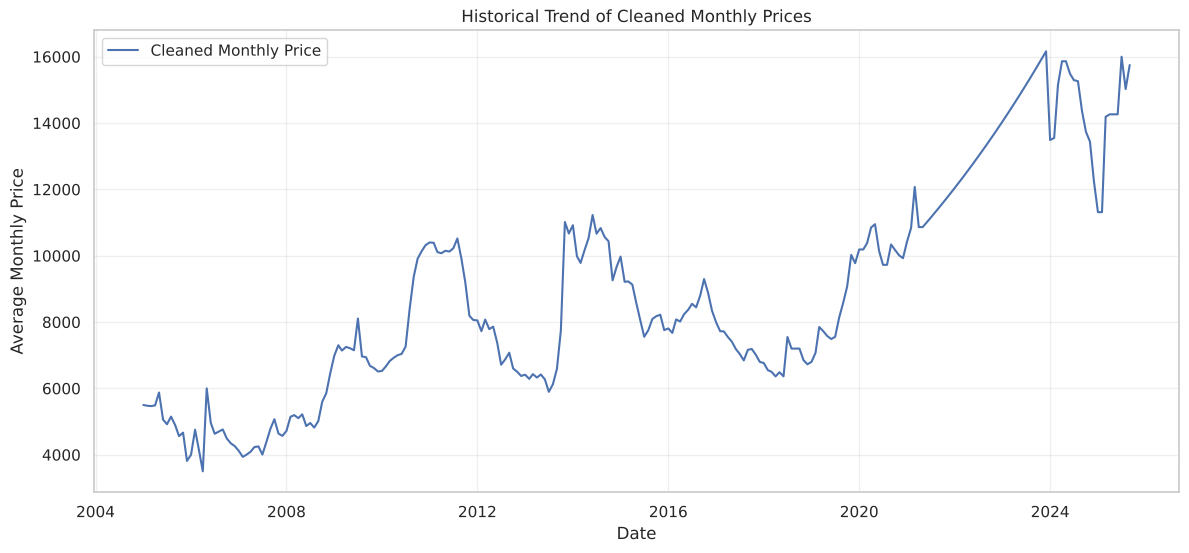

In [30]:
plt.figure(figsize=(14, 6))

plt.plot(
    clean_df.index,
    clean_df["avg_monthly_price"],
    label="Cleaned Monthly Price",
    linewidth=1.5
)

plt.title("Historical Trend of Cleaned Monthly Prices")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 5.2 Original vs Cleaned Price Comparison

Compare the original dataset with the cleaned dataset to visualize
the impact of logarithmic interpolation on the suspected duplicated
periods.

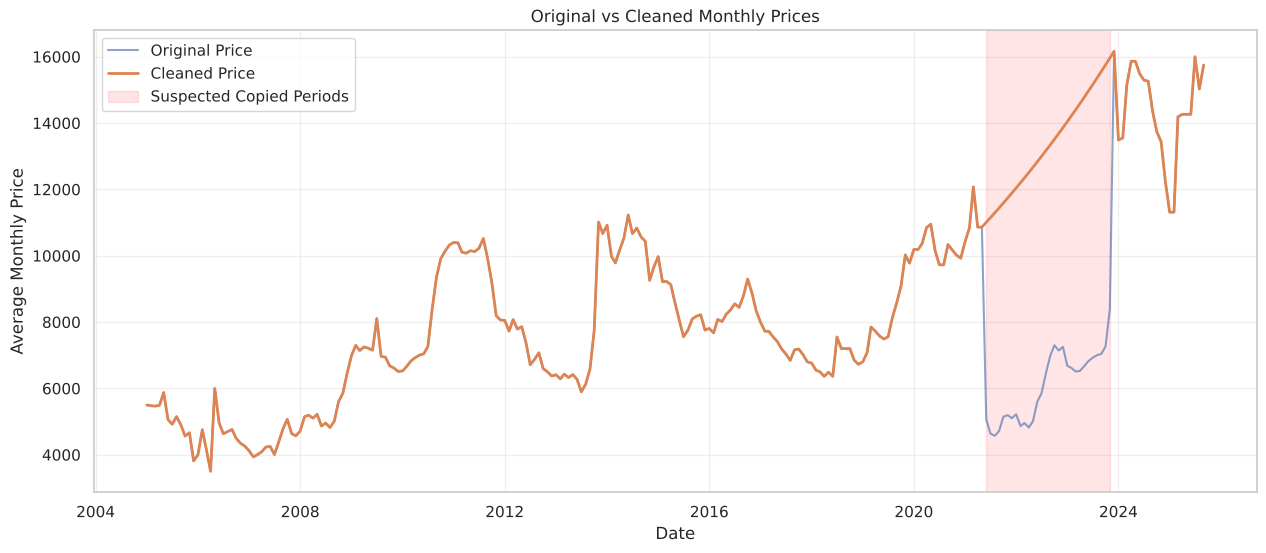

In [31]:
plt.figure(figsize=(15, 6))

plt.plot(
    df.index,
    df["avg_monthly_price"],
    label="Original Price",
    alpha=0.65
)

plt.plot(
    clean_df.index,
    clean_df["avg_monthly_price"],
    label="Cleaned Price",
    linewidth=2
)

plt.axvspan(
    copied_mask.index[copied_mask][0],
    copied_mask.index[copied_mask][-1],
    color="red",
    alpha=0.10,
    label="Suspected Copied Periods"
)

plt.title("Original vs Cleaned Monthly Prices")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 5.3 Seasonality Analysis

Investigate whether monthly price changes exhibit recurring
calendar-month patterns.

Monthly percentage changes are used instead of raw prices to
reduce the influence of the long-term price trend.

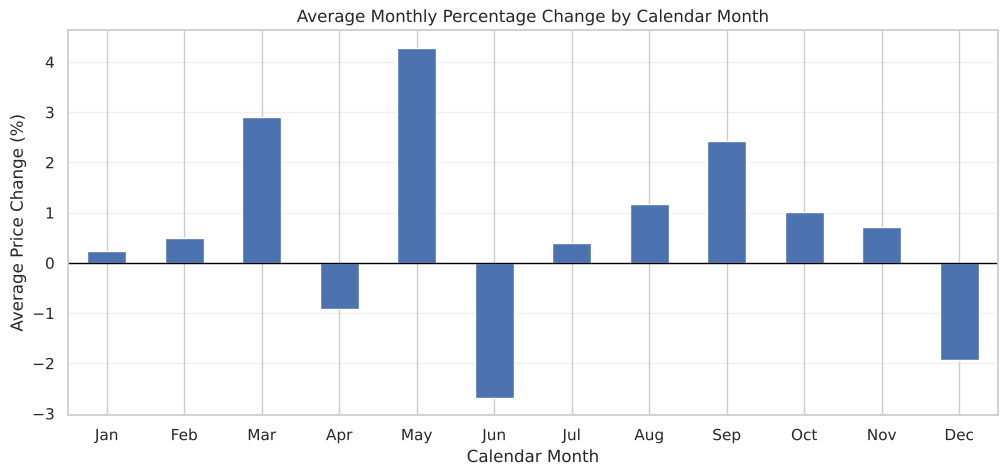

Jan    0.24
Feb    0.50
Mar    2.90
Apr   -0.91
May    4.28
Jun   -2.69
Jul    0.40
Aug    1.16
Sep    2.43
Oct    1.01
Nov    0.71
Dec   -1.93
Name: avg_monthly_price, dtype: float64

In [32]:
# Calculate monthly percentage changes
monthly_returns = clean_df["avg_monthly_price"].pct_change() * 100

# Group percentage changes by calendar month
seasonal_changes = monthly_returns.groupby(
    monthly_returns.index.month
).mean()

# Use calendar month names
month_names = [
    "Jan", "Feb", "Mar", "Apr", "May", "Jun",
    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"
]

seasonal_changes.index = month_names

# Plot average monthly percentage changes
plt.figure(figsize=(12, 5))

seasonal_changes.plot(kind="bar")

plt.axhline(0, color="black", linewidth=1)
plt.title("Average Monthly Percentage Change by Calendar Month")
plt.xlabel("Calendar Month")
plt.ylabel("Average Price Change (%)")
plt.xticks(rotation=0)
plt.grid(axis="y", alpha=0.3)
plt.show()

display(seasonal_changes.round(2))

### 5.4 Statistical Summary of the Cleaned Dataset

Summarize the statistical characteristics of the cleaned price series,
including its mean, median, standard deviation, minimum, and maximum.

In [33]:
# Generate descriptive statistics
cleaned_summary = clean_df["avg_monthly_price"].describe()

# Additional statistical measures
additional_stats = pd.Series({
    "Median": clean_df["avg_monthly_price"].median(),
    "Variance": clean_df["avg_monthly_price"].var(),
    "Skewness": clean_df["avg_monthly_price"].skew(),
    "Kurtosis": clean_df["avg_monthly_price"].kurt()
})

print("CLEANED DATASET STATISTICS")
display(cleaned_summary.round(2).to_frame())

print("ADDITIONAL STATISTICAL MEASURES")
display(additional_stats.round(2).to_frame())

CLEANED DATASET STATISTICS


,avg_monthly_price
count,249.00
mean,8793.14
std,3220.28
min,3500.00
25%,6510.00
50%,8050.00
75%,10670.00
max,16163.00


ADDITIONAL STATISTICAL MEASURES


,0
Median,8050.00
Variance,10370229.97
Skewness,0.57
Kurtosis,-0.53


### 5.5 EDA Conclusion

The cleaned dataset contains 249 monthly observations with no missing
values.

The exploratory analysis confirms that:

1. The historical price series exhibits long-term movements and
   short-term fluctuations.
2. The original and cleaned datasets differ only in the 30 observations
   replaced through logarithmic interpolation.
3. Calendar-month percentage changes provide an initial indication
   of potential seasonal behaviour.
4. Descriptive statistics summarize the distribution and variability
   of the cleaned price series.

The cleaned dataset is now ready for time-series analysis,
stationarity testing, and forecasting model development.

Potential outliers were retained because statistical detection alone
does not establish that an observation is erroneous.

### 6.1 Time-Series Decomposition

Time-series decomposition separates the historical price series into
trend, seasonal, and residual components.

Since the dataset contains monthly observations, we use a seasonal
period of 12 to investigate possible annual patterns.

An additive decomposition is initially used for exploratory analysis.

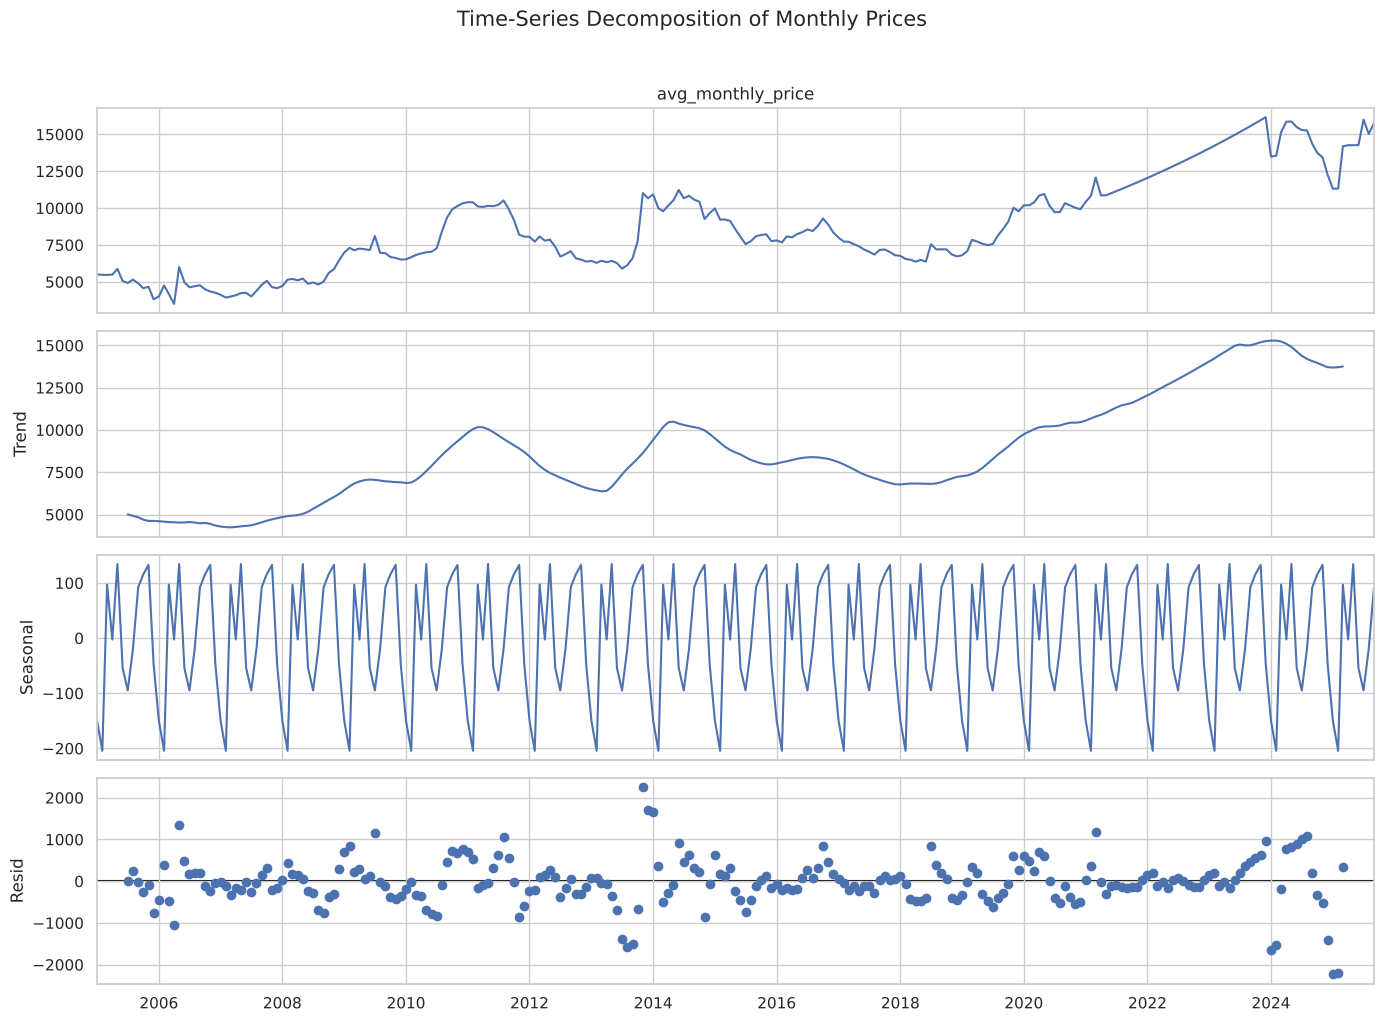

In [34]:
from statsmodels.tsa.seasonal import seasonal_decompose

# Perform additive time-series decomposition
decomposition = seasonal_decompose(
    clean_df["avg_monthly_price"],
    model="additive",
    period=12
)

# Plot decomposition components
fig = decomposition.plot()
fig.set_size_inches(14, 10)

plt.suptitle(
    "Time-Series Decomposition of Monthly Prices",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()

### 6.2 Rolling Mean and Rolling Standard Deviation

Rolling statistics help examine whether the mean and variability
of the price series remain stable over time.

We use a 12-month moving window to calculate the rolling mean
and rolling standard deviation.

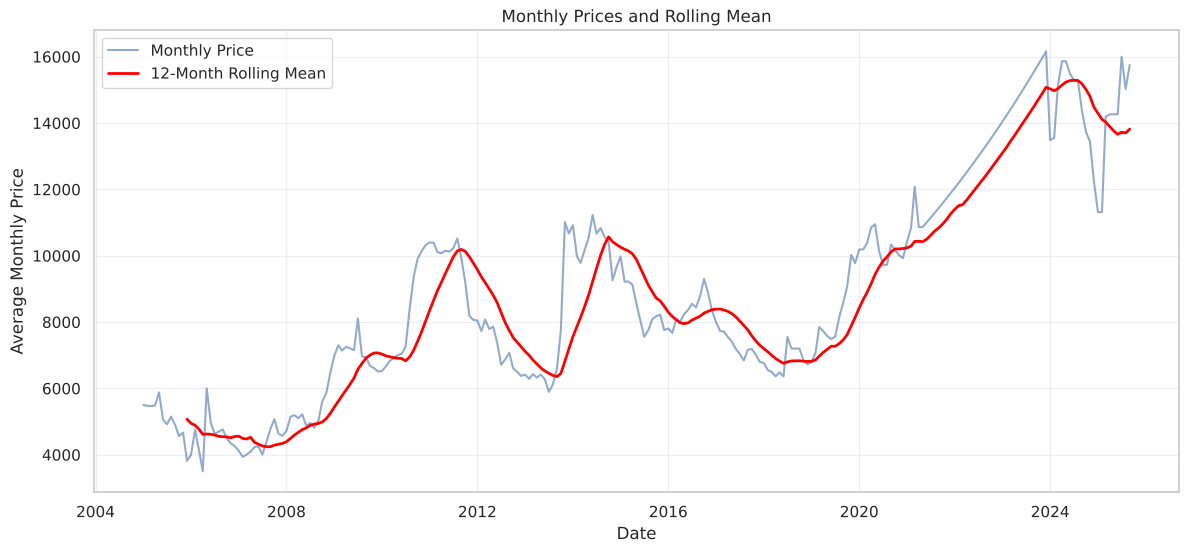

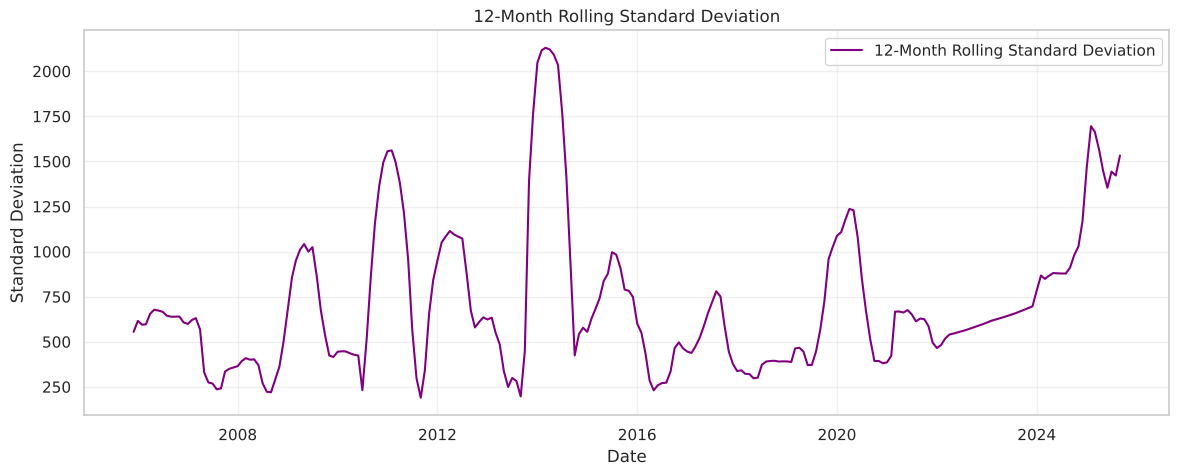

In [35]:
# Extract the cleaned price series
price_series = clean_df["avg_monthly_price"]

# Calculate 12-month rolling statistics
rolling_mean = price_series.rolling(
    window=12
).mean()

rolling_std = price_series.rolling(
    window=12
).std()

# Plot the original series and rolling mean
plt.figure(figsize=(14, 6))

plt.plot(
    price_series,
    label="Monthly Price",
    alpha=0.6
)

plt.plot(
    rolling_mean,
    label="12-Month Rolling Mean",
    color="red",
    linewidth=2
)

plt.title("Monthly Prices and Rolling Mean")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# Plot rolling standard deviation
plt.figure(figsize=(14, 5))

plt.plot(
    rolling_std,
    color="purple",
    label="12-Month Rolling Standard Deviation"
)

plt.title("12-Month Rolling Standard Deviation")
plt.xlabel("Date")
plt.ylabel("Standard Deviation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 6.3 Stationarity Testing Using Augmented Dickey-Fuller (ADF)

The Augmented Dickey-Fuller test is used to investigate whether
the time series contains a unit root.

The null hypothesis states that the series is non-stationary,
while the alternative hypothesis indicates stationarity under
the selected test specification.

A significance level of 5% is used for interpretation.

> Note: this test is run on the full cleaned series purely as an
> exploratory diagnostic. The differencing order used for model
> development is re-determined on the **training data only** in
> Section 7.3 so that no test-period information influences modelling.

In [36]:
from statsmodels.tsa.stattools import adfuller

# Extract cleaned monthly price series
price_series = clean_df["avg_monthly_price"].dropna()

# Perform the ADF test
adf_result = adfuller(
    price_series,
    regression="c",
    autolag="AIC",
    result_object=True
)

print("AUGMENTED DICKEY-FULLER TEST")
print("-" * 45)
print(f"ADF Statistic: {adf_result.statistic:.4f}")
print(f"P-value: {adf_result.pvalue:.6f}")
print(f"Number of Lags: {adf_result.lags}")
print(f"Observations Used: {adf_result.nobs}")

print("\nCritical Values:")
for key, value in adf_result.critical_values.items():
    print(f"{key}: {value:.4f}")

print("\nConclusion:")
if adf_result.pvalue < 0.05:
    print("Reject the null hypothesis.")
    print("Evidence suggests the series is stationary.")
else:
    print("Fail to reject the null hypothesis.")
    print("The series may be non-stationary.")


AUGMENTED DICKEY-FULLER TEST
---------------------------------------------
ADF Statistic: -0.7136
P-value: 0.843187
Number of Lags: 0
Observations Used: 248

Critical Values:
1%: -3.4570
5%: -2.8733
10%: -2.5730

Conclusion:
Fail to reject the null hypothesis.
The series may be non-stationary.


### ADF Test Conclusion

The Augmented Dickey-Fuller test was performed on the cleaned
monthly price series. The p-value (printed above) is well above
0.05, so we fail to reject the null hypothesis of a unit root.

The result indicates insufficient evidence of stationarity.
Therefore, differencing and other suitable transformations
will be investigated before forecasting model development.


### 6.4 First-Order Differencing

The original price series was found to be non-stationary using
the Augmented Dickey-Fuller test.

First-order differencing is applied to calculate the change
between consecutive monthly observations.

This transformation helps remove changing price levels and
may improve stationarity.

In [37]:
# Calculate first-order differencing
first_difference = clean_df["avg_monthly_price"].diff()

# Remove the first missing observation
first_difference = first_difference.dropna()

# Display the first few observations
print("FIRST-ORDER DIFFERENCED SERIES")
display(first_difference.head(10).to_frame())

print("\nNumber of observations:", len(first_difference))

FIRST-ORDER DIFFERENCED SERIES


,avg_monthly_price
date,
2005-02-01,-24.0
2005-03-01,-10.0
2005-04-01,21.0
2005-05-01,389.0
2005-06-01,-818.0
2005-07-01,-139.0
2005-08-01,230.0
2005-09-01,-250.0
2005-10-01,-337.0



Number of observations: 248


### 6.4.2 Visualize First-Order Differencing

Visualize the differenced series to examine whether the
long-term trend has been reduced and whether the series
fluctuates around a relatively stable level.

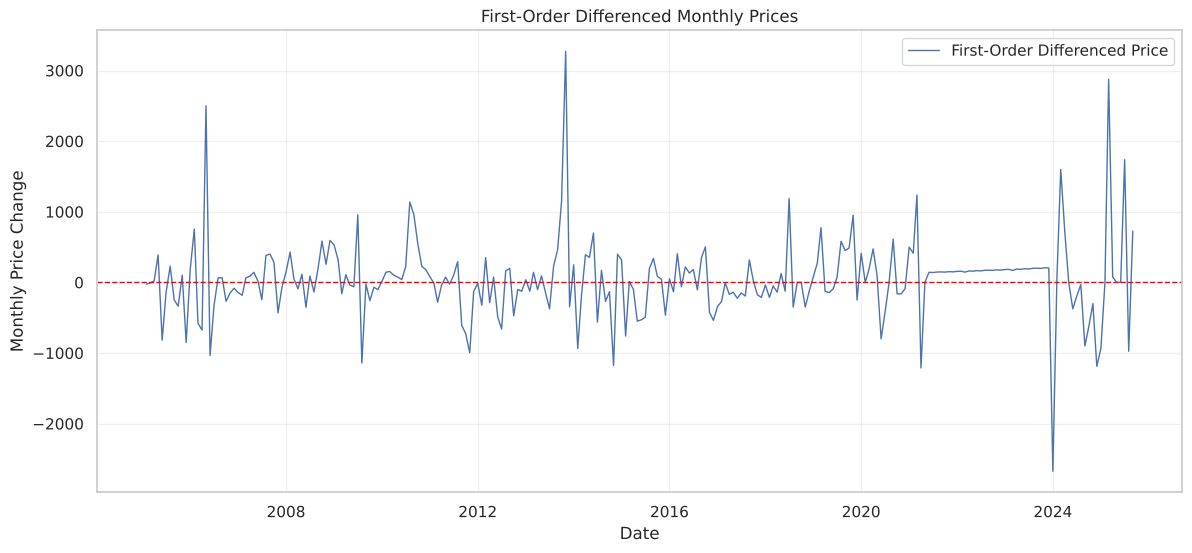

In [38]:
plt.figure(figsize=(14, 6))

plt.plot(
    first_difference.index,
    first_difference,
    label="First-Order Differenced Price",
    linewidth=1
)

plt.axhline(
    y=0,
    color="red",
    linestyle="--",
    linewidth=1
)

plt.title("First-Order Differenced Monthly Prices")
plt.xlabel("Date")
plt.ylabel("Monthly Price Change")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### 6.4.3 ADF Test After First-Order Differencing

Apply the Augmented Dickey-Fuller test to the differenced series
to determine whether first-order differencing has improved
stationarity.

The significance level remains 5%.

In [39]:
# Run the ADF test on the first-order differenced series
adf_diff_result = adfuller(
    first_difference,
    regression="c",
    autolag="AIC",
    result_object=True
)

print("ADF TEST - FIRST-ORDER DIFFERENCED SERIES")
print("-" * 50)

print(f"ADF Statistic: {adf_diff_result.statistic:.4f}")
print(f"P-value: {adf_diff_result.pvalue:.6f}")
print(f"Number of Lags: {adf_diff_result.lags}")
print(f"Observations Used: {adf_diff_result.nobs}")

print("\nCritical Values:")

for key, value in adf_diff_result.critical_values.items():
    print(f"{key}: {value:.4f}")

print("\nConclusion:")

if adf_diff_result.pvalue < 0.05:
    print("Reject the null hypothesis.")
    print("The differenced series is stationary according to the ADF test.")
else:
    print("Fail to reject the null hypothesis.")
    print("The differenced series may still be non-stationary.")

ADF TEST - FIRST-ORDER DIFFERENCED SERIES
--------------------------------------------------
ADF Statistic: -14.9907
P-value: 0.000000
Number of Lags: 0
Observations Used: 247

Critical Values:
1%: -3.4571
5%: -2.8733
10%: -2.5730

Conclusion:
Reject the null hypothesis.
The differenced series is stationary according to the ADF test.


### 6.5 Final Time-Series Preparation

In this phase, we validate the cleaned monthly time series and
prepare the required data structures for forecasting.

The original price series is preserved for models that can handle
non-stationary data, while the first-order differenced series is
retained for models that require stationary input.

In [40]:
# Create the final monthly price series
final_series = clean_df["avg_monthly_price"].copy()

# Validate the time index
expected_index = pd.date_range(
    start=final_series.index.min(),
    end=final_series.index.max(),
    freq="MS"
)

print("FINAL TIME SERIES VALIDATION")
print("-" * 45)

print("Total observations:", len(final_series))
print("Start date:", final_series.index.min())
print("End date:", final_series.index.max())
print("Missing values:", final_series.isna().sum())
print("Duplicate dates:", final_series.index.duplicated().sum())
print("Continuous monthly index:", final_series.index.equals(expected_index))
print("Frequency:", pd.infer_freq(final_series.index))

FINAL TIME SERIES VALIDATION
---------------------------------------------
Total observations: 249
Start date: 2005-01-01 00:00:00
End date: 2025-09-01 00:00:00
Missing values: 0
Duplicate dates: 0
Continuous monthly index: True
Frequency: MS


### 6.5.2 Prepare Forecasting Series

Maintain two versions of the price series:

1. Original cleaned series: Preserves actual price levels and
   interpolated estimates.
2. First-order differenced series: Represents monthly price
   changes and provides a stationary input candidate.

The appropriate series will be selected based on the forecasting
algorithm.

In [41]:
# Original cleaned price series
forecasting_series = final_series.copy()

# First-order differenced series
stationary_series = forecasting_series.diff().dropna()

print("FORECASTING SERIES SUMMARY")
print("-" * 45)

print("Original series observations:", len(forecasting_series))
print("Differenced series observations:", len(stationary_series))

print("\nOriginal series:")
display(forecasting_series.head())

print("\nDifferenced series:")
display(stationary_series.head())

FORECASTING SERIES SUMMARY
---------------------------------------------
Original series observations: 249
Differenced series observations: 248

Original series:


date
2005-01-01    5500.0
2005-02-01    5476.0
2005-03-01    5466.0
2005-04-01    5487.0
2005-05-01    5876.0
Freq: MS, Name: avg_monthly_price, dtype: float64


Differenced series:


date
2005-02-01    -24.0
2005-03-01    -10.0
2005-04-01     21.0
2005-05-01    389.0
2005-06-01   -818.0
Freq: MS, Name: avg_monthly_price, dtype: float64

#### 6.5.3 Verify stationarity of the prepared series
Let's run one final ADF check on the prepared differenced series.

In [42]:
# Perform final ADF validation
final_adf = adfuller(
    stationary_series,
    regression="c",
    autolag="AIC",
    result_object=True
)

print("FINAL STATIONARITY VALIDATION")
print("-" * 45)

print(f"ADF Statistic: {final_adf.statistic:.4f}")
print(f"P-value: {final_adf.pvalue:.6f}")
print(f"5% Critical Value: {final_adf.critical_values['5%']:.4f}")

if final_adf.pvalue < 0.05:
    print("\nStationarity check passed.")
else:
    print("\nStationarity check not passed.")

FINAL STATIONARITY VALIDATION
---------------------------------------------
ADF Statistic: -14.9907
P-value: 0.000000
5% Critical Value: -2.8733

Stationarity check passed.


#### 6.5.4 Final preparation visualization

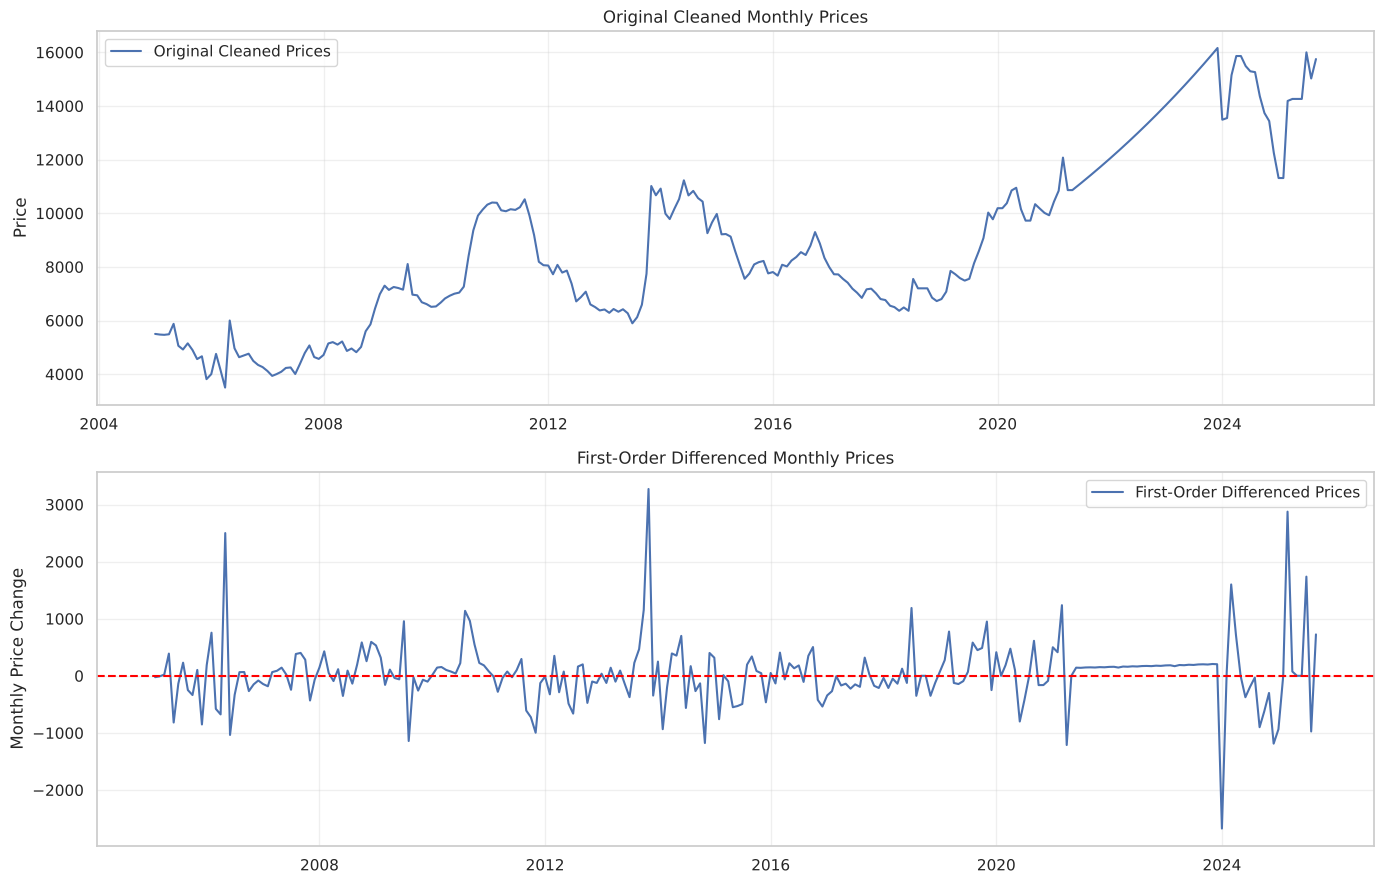

In [43]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))

# Original cleaned series
axes[0].plot(
    forecasting_series,
    label="Original Cleaned Prices"
)
axes[0].set_title("Original Cleaned Monthly Prices")
axes[0].set_ylabel("Price")
axes[0].legend()
axes[0].grid(alpha=0.3)

# First-order differenced series
axes[1].plot(
    stationary_series,
    label="First-Order Differenced Prices"
)
axes[1].axhline(0, color="red", linestyle="--")
axes[1].set_title("First-Order Differenced Monthly Prices")
axes[1].set_ylabel("Monthly Price Change")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

#### 6.5.5 Final preparation summary

In [44]:
preparation_summary = pd.DataFrame({
    "Series": [
        "Original Cleaned Series",
        "First-Order Differenced Series"
    ],
    "Observations": [
        len(forecasting_series),
        len(stationary_series)
    ],
    "Start Date": [
        forecasting_series.index.min(),
        stationary_series.index.min()
    ],
    "End Date": [
        forecasting_series.index.max(),
        stationary_series.index.max()
    ],
    "Missing Values": [
        forecasting_series.isna().sum(),
        stationary_series.isna().sum()
    ]
})

display(preparation_summary)

,Series,Observations,Start Date,End Date,Missing Values
0,Original Cleaned Series,249,2005-01-01,2025-09-01,0
1,First-Order Differenced Series,248,2005-02-01,2025-09-01,0


### 6.6 Stationarity and Time-Series Preparation Conclusion

The original cleaned monthly price series was evaluated using
rolling statistics and the Augmented Dickey-Fuller test and was
found to be non-stationary (p-value > 0.05).

First-order differencing was subsequently applied. The resulting
series produced a p-value far below 0.05, providing strong
evidence of stationarity.

The following series have been prepared:

1. Original cleaned price series: 249 observations.
2. First-order differenced series: 248 observations.

All transformations will be performed within the appropriate
training and validation workflow to prevent future-data leakage.


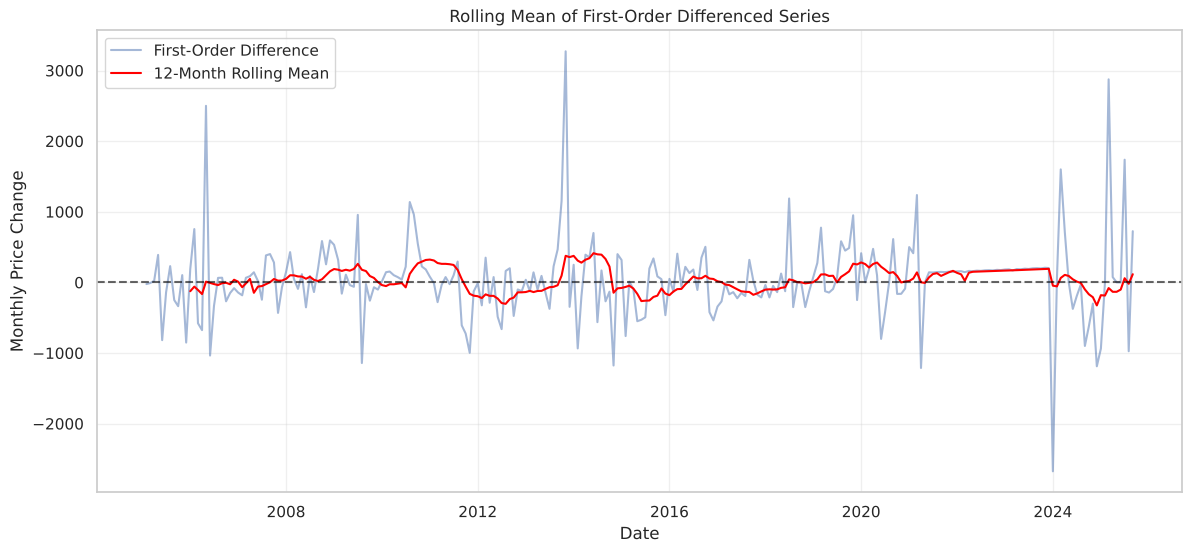

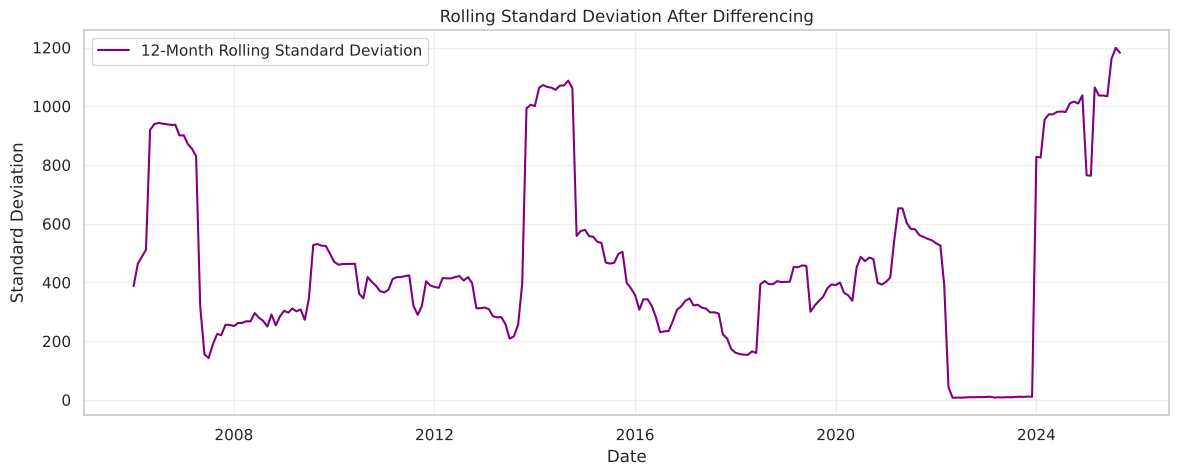

In [45]:
# Calculate rolling statistics on the differenced series
diff_rolling_mean = stationary_series.rolling(window=12).mean()
diff_rolling_std = stationary_series.rolling(window=12).std()

plt.figure(figsize=(14, 6))

plt.plot(
    stationary_series,
    label="First-Order Difference",
    alpha=0.5
)

plt.plot(
    diff_rolling_mean,
    label="12-Month Rolling Mean",
    color="red"
)

plt.axhline(0, color="black", linestyle="--", alpha=0.6)

plt.title("Rolling Mean of First-Order Differenced Series")
plt.xlabel("Date")
plt.ylabel("Monthly Price Change")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

plt.figure(figsize=(14, 5))

plt.plot(
    diff_rolling_std,
    label="12-Month Rolling Standard Deviation",
    color="purple"
)

plt.title("Rolling Standard Deviation After Differencing")
plt.xlabel("Date")
plt.ylabel("Standard Deviation")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

### Section 6 Conclusion – Stationarity and Time-Series Preparation

The original monthly price series was found to be non-stationary
based on the Augmented Dickey-Fuller test. First-order differencing
produced strong evidence against the unit-root null hypothesis.

The 30 interpolated observations introduce uncertainty and
must be considered during model validation and interpretation
(see the sensitivity analysis in Section 7.9).


#### Rolling Standard Deviation Interpretation

The 12-month rolling standard deviation of the first-order
differenced series shows considerable variation over time.

A particularly low volatility period appears between 2021
and 2023. This is primarily influenced by the logarithmic
interpolation of 30 suspected duplicated observations.

Volatility increases again during 2024 and 2025.

These findings indicate that first-order differencing provides
evidence of stationarity according to the ADF test, but
time-varying volatility remains present.

This limitation will be considered during forecasting model
development and evaluation.

### 7.1 Chronological Train-Test Split

The cleaned monthly price series is divided into training and
testing datasets using a chronological split.

The final 12 observations are reserved for testing, matching
the intended 12-month forecasting horizon.

The training dataset contains historical observations used
for model development, while the testing dataset is used
to evaluate forecasting performance.

Random shuffling is avoided to preserve the temporal order
of the observations.

In [46]:
# Use the original cleaned price levels
forecasting_series = clean_df["avg_monthly_price"].copy()

# Define the forecasting horizon
forecast_horizon = 12

# Chronological train-test split
train = forecasting_series.iloc[:-forecast_horizon].copy()
test = forecasting_series.iloc[-forecast_horizon:].copy()

# Display dataset information
print("CHRONOLOGICAL TRAIN-TEST SPLIT")
print("-" * 50)

print("\nTraining Dataset")
print("Observations:", len(train))
print("Start Date:", train.index.min())
print("End Date:", train.index.max())

print("\nTesting Dataset")
print("Observations:", len(test))
print("Start Date:", test.index.min())
print("End Date:", test.index.max())

CHRONOLOGICAL TRAIN-TEST SPLIT
--------------------------------------------------

Training Dataset
Observations: 237
Start Date: 2005-01-01 00:00:00
End Date: 2024-09-01 00:00:00

Testing Dataset
Observations: 12
Start Date: 2024-10-01 00:00:00
End Date: 2025-09-01 00:00:00


#### 7.1.2 Visualize the train-test split

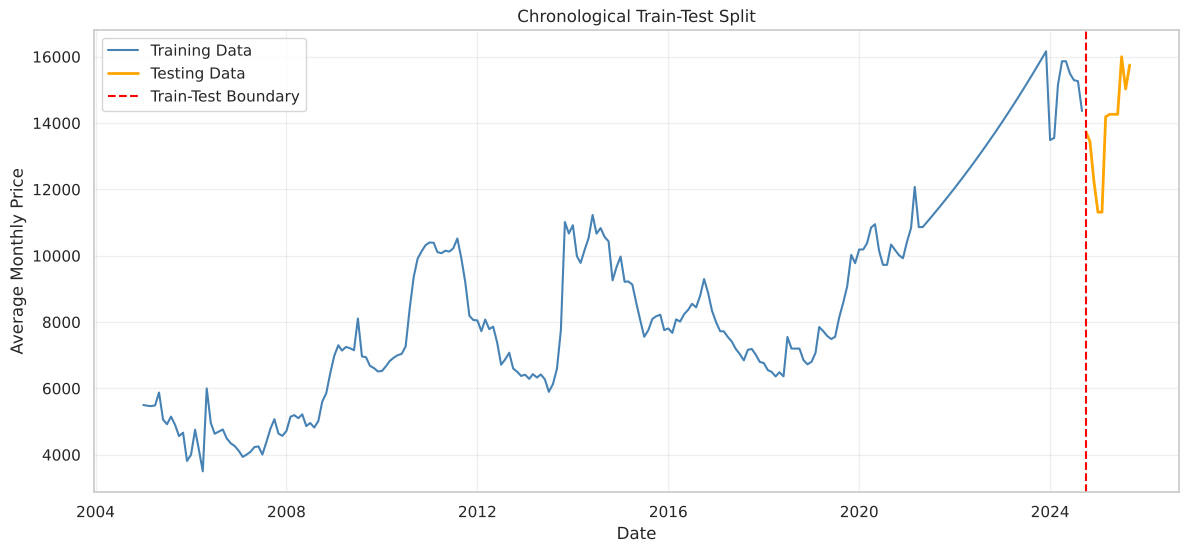

In [47]:
plt.figure(figsize=(14, 6))

plt.plot(
    train.index,
    train,
    label="Training Data",
    color="steelblue"
)

plt.plot(
    test.index,
    test,
    label="Testing Data",
    color="orange",
    linewidth=2
)

plt.axvline(
    test.index[0],
    color="red",
    linestyle="--",
    label="Train-Test Boundary"
)

plt.title("Chronological Train-Test Split")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

#### 7.1.3 Validate the split

In [48]:
# Verify chronological separation
print("TRAIN-TEST VALIDATION")
print("-" * 40)

print("Training missing values:", train.isna().sum())
print("Testing missing values:", test.isna().sum())

print("Training ends before testing starts:",
      train.index.max() < test.index.min())

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("Total observations preserved:",
      len(train) + len(test) == len(forecasting_series))

TRAIN-TEST VALIDATION
----------------------------------------
Training missing values: 0
Testing missing values: 0
Training ends before testing starts: True
Training observations: 237
Testing observations: 12
Total observations preserved: True


### 7.1.4 Train-Test Split Conclusion

The cleaned monthly price series was divided chronologically
into training and testing datasets.

- Training: 237 observations (January 2005 – September 2024)
- Testing: 12 observations (October 2024 – September 2025)

The split preserves temporal order, contains no missing values,
and retains all 249 observations.

The testing dataset is reserved for evaluating forecasting
performance over a 12-month horizon.

### 7.2 Baseline Forecasting Models

Baseline forecasting models are developed to establish
a performance benchmark before implementing advanced
time-series forecasting algorithms.

The following models are evaluated:

1. Naive Forecasting
2. Seasonal Naive Forecasting
3. Historical Mean Forecasting

All forecasts are generated using only the training dataset
and evaluated against the same 12-month testing dataset.

This ensures a fair chronological comparison without
using future observations during model development.

In [49]:
# Define forecasting horizon
forecast_horizon = len(test)

# 1. Naive Forecast
naive_forecast = pd.Series(
    train.iloc[-1],
    index=test.index,
    name="Naive Forecast"
)

# 2. Seasonal Naive Forecast
seasonal_naive_forecast = pd.Series(
    train.iloc[-12:].to_numpy(),
    index=test.index,
    name="Seasonal Naive Forecast"
)

# 3. Historical Mean Forecast
historical_mean_forecast = pd.Series(
    train.mean(),
    index=test.index,
    name="Historical Mean Forecast"
)

# Combine forecasts with actual test prices
baseline_forecasts = pd.DataFrame({
    "Actual": test,
    "Naive": naive_forecast,
    "Seasonal Naive": seasonal_naive_forecast,
    "Historical Mean": historical_mean_forecast
})

print("BASELINE FORECASTS")
print("-" * 50)

display(baseline_forecasts.round(2))

BASELINE FORECASTS
--------------------------------------------------


,Actual,Naive,Seasonal Naive,Historical Mean
date,,,,
2024-10-01,13738.0,14363.0,15753.27,8538.77
2024-11-01,13438.0,14363.0,15960.18,8538.77
2024-12-01,12250.0,14363.0,16163.00,8538.77
2025-01-01,11313.0,14363.0,13488.00,8538.77
2025-02-01,11313.0,14363.0,13550.00,8538.77
2025-03-01,14188.0,14363.0,15150.00,8538.77
2025-04-01,14263.0,14363.0,15863.00,8538.77
2025-05-01,14263.0,14363.0,15863.00,8538.77
2025-06-01,14263.0,14363.0,15488.00,8538.77


### 7.2.2 Baseline Model Evaluation

Evaluate baseline forecasting performance using:

- Mean Absolute Error (MAE)
- Root Mean Squared Error (RMSE)
- Mean Absolute Percentage Error (MAPE)

Lower values indicate better forecasting performance.

In [50]:
# Define evaluation function
def evaluate_forecast(actual, predicted):

    actual = np.asarray(actual, dtype=float)
    predicted = np.asarray(predicted, dtype=float)

    mae = np.mean(np.abs(actual - predicted))

    rmse = np.sqrt(np.mean((actual - predicted) ** 2))

    # Guard: MAPE is undefined where the actual value is zero
    nonzero = actual != 0
    if not nonzero.any():
        raise ValueError("MAPE is undefined: all actual values are zero.")
    mape = np.mean(
        np.abs((actual[nonzero] - predicted[nonzero]) / actual[nonzero])
    ) * 100

    return {
        "MAE": mae,
        "RMSE": rmse,
        "MAPE (%)": mape
    }


# Evaluate all baseline models
baseline_metrics = pd.DataFrame({
    "Naive": evaluate_forecast(
        test, naive_forecast
    ),
    "Seasonal Naive": evaluate_forecast(
        test, seasonal_naive_forecast
    ),
    "Historical Mean": evaluate_forecast(
        test, historical_mean_forecast
    )
}).T

# Sort models by RMSE
baseline_metrics = baseline_metrics.sort_values("RMSE")

print("BASELINE MODEL PERFORMANCE")
print("-" * 50)

display(baseline_metrics.round(2))

BASELINE MODEL PERFORMANCE
--------------------------------------------------


,MAE,RMSE,MAPE (%)
Naive,1160.33,1565.74,9.12
Seasonal Naive,1715.04,1947.09,13.08
Historical Mean,5278.23,5478.42,37.45


#### 7.2.3 Visualize baseline forecasts

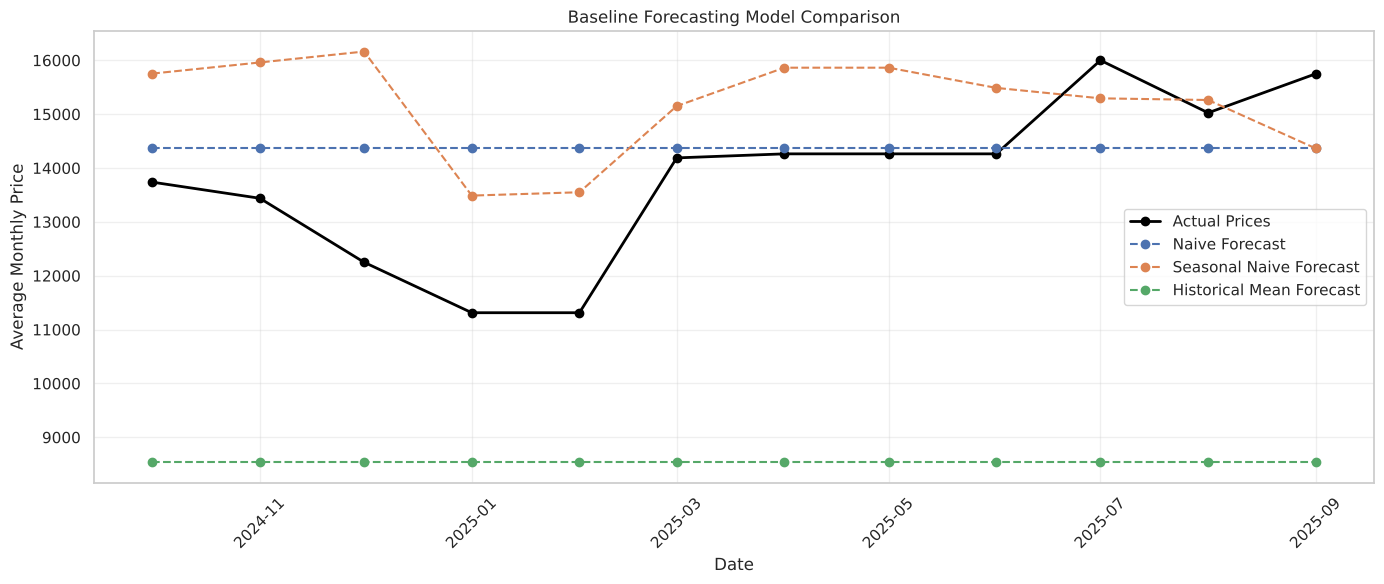

In [51]:
plt.figure(figsize=(14, 6))

plt.plot(
    test.index,
    test,
    label="Actual Prices",
    color="black",
    linewidth=2,
    marker="o"
)

plt.plot(
    naive_forecast.index,
    naive_forecast,
    label="Naive Forecast",
    linestyle="--",
    marker="o"
)

plt.plot(
    seasonal_naive_forecast.index,
    seasonal_naive_forecast,
    label="Seasonal Naive Forecast",
    linestyle="--",
    marker="o"
)

plt.plot(
    historical_mean_forecast.index,
    historical_mean_forecast,
    label="Historical Mean Forecast",
    linestyle="--",
    marker="o"
)

plt.title("Baseline Forecasting Model Comparison")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 7.2.4 Baseline Forecasting Conclusion

Three baseline forecasting approaches were implemented and evaluated
over the same 12-month testing period using MAE, RMSE, and MAPE.

The Naive model achieved the best performance of the three (see table
above) and is used as the benchmark that advanced models must beat.

Note that the Seasonal Naive forecast for Oct–Nov 2024 is based on the
**interpolated** values for Oct–Nov 2023, which must be kept in mind
when interpreting its score.


### 7.3 ARIMA Model Development

ARIMA is a statistical forecasting model that combines
autoregression, differencing, and moving averages.

Before fitting the model, stationarity is evaluated using
the training dataset only.

This prevents information from the testing period from
influencing model development.

In [52]:
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller

# Prepare training data
train_series = train.copy()

# Test stationarity of training series
train_adf = adfuller(
    train_series,
    regression="c",
    autolag="AIC",
    result_object=True
)

# First-order difference of training data
train_difference = train_series.diff().dropna()

# Test stationarity after differencing
train_diff_adf = adfuller(
    train_difference,
    regression="c",
    autolag="AIC",
    result_object=True
)

# Display results
stationarity_results = pd.DataFrame({
    "ADF Statistic": [
        train_adf.statistic,
        train_diff_adf.statistic
    ],
    "P-value": [
        train_adf.pvalue,
        train_diff_adf.pvalue
    ],
    "5% Critical Value": [
        train_adf.critical_values["5%"],
        train_diff_adf.critical_values["5%"]
    ]
}, index=["Training Series", "First Difference"])

display(stationarity_results.round(6))
# Determine differencing order from training data
if train_adf.pvalue < 0.05:
    d_order = 0
elif train_diff_adf.pvalue < 0.05:
    d_order = 1
else:
    d_order = None

if d_order is None:
    raise ValueError(
        "First-order differencing did not establish stationarity. "
        "Inspect the training series before selecting ARIMA order."
    )

print("Selected differencing order (d):", d_order)

,ADF Statistic,P-value,5% Critical Value
Training Series,-0.781370,0.824533,-2.873866
First Difference,-14.411147,0.000000,-2.873919


Selected differencing order (d): 1


### 7.3.2 Autocorrelation and Partial Autocorrelation

ACF and PACF plots are used to investigate relationships
between current and previous observations.

The plots provide initial guidance when selecting
autoregressive (p) and moving-average (q) parameters.

They are treated as diagnostic tools rather than
the only method of parameter selection.

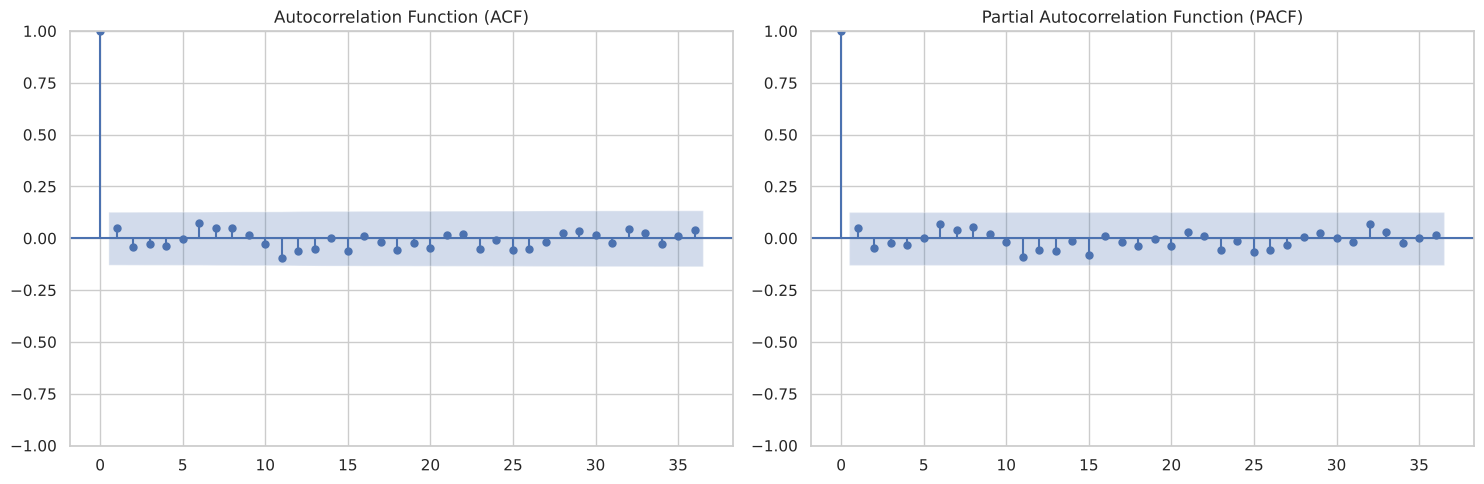

In [53]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

# Use stationary training data for ACF and PACF analysis
acf_pacf_series = train_difference if d_order == 1 else train_series

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

plot_acf(
    acf_pacf_series,
    lags=36,
    ax=axes[0]
)

axes[0].set_title("Autocorrelation Function (ACF)")

plot_pacf(
    acf_pacf_series,
    lags=36,
    method="ywm",
    ax=axes[1]
)

axes[1].set_title("Partial Autocorrelation Function (PACF)")

plt.tight_layout()
plt.show()

#### 7.3.3 ARIMA parameter selection using AIC and BIC
We will test combinations of:
- p: 0 to 3
- q: 0 to 3
- d: selected from the training-only stationarity tests.
We will also compare models with and without a drift term.

Why? A drift term allows an integrated model to represent a non-zero average change over time. This can be important when prices have a long-term upward tendency

In [54]:
import warnings

# Store candidate model results
arima_candidates = []

# Define possible p and q values
p_values = range(4)
q_values = range(4)

# Compare models with and without drift
trend_options = ["n", "t"] if d_order == 1 else ["n", "c"]

for p in p_values:
    for q in q_values:
        for trend_option in trend_options:

            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")

                    candidate_model = ARIMA(
                        train_series,
                        order=(p, d_order, q),
                        trend=trend_option
                    ).fit()

                # Ignore models that did not converge
                convergence_info = getattr(
                    candidate_model,
                    "mle_retvals",
                    {}
                )

                if not convergence_info.get("converged", True):
                    continue

                arima_candidates.append({
                    "p": p,
                    "d": d_order,
                    "q": q,
                    "Trend": trend_option,
                    "AIC": candidate_model.aic,
                    "BIC": candidate_model.bic
                })

            except Exception as error:
                print(
                    f"Skipped ARIMA({p},{d_order},{q}), "
                    f"trend={trend_option}: {error}"
                )

# Create candidate comparison table
arima_order_results = pd.DataFrame(arima_candidates)

if arima_order_results.empty:
    raise ValueError("No ARIMA candidates converged successfully.")

# Sort by AIC
arima_order_results = arima_order_results.sort_values(
    "AIC"
).reset_index(drop=True)

print("TOP ARIMA CANDIDATES")
display(arima_order_results.head(10).round(2))

TOP ARIMA CANDIDATES


,p,d,q,Trend,AIC,BIC
0,0,1,0,n,3620.27,3623.73
1,0,1,0,t,3621.01,3627.94
2,0,1,1,n,3621.53,3628.46
3,1,1,0,n,3621.57,3628.49
4,0,1,1,t,3622.44,3632.83
5,1,1,0,t,3622.47,3632.86
6,2,1,0,n,3623.19,3633.58
7,0,1,2,n,3623.25,3633.64
8,1,1,1,n,3623.35,3633.75
9,2,1,0,t,3623.96,3637.82


#### 7.3.4 Fit the selected ARIMA model

In [55]:
# Select the best ARIMA candidate based on training AIC
best_candidate = arima_order_results.iloc[0]

best_order = (
    int(best_candidate["p"]),
    int(best_candidate["d"]),
    int(best_candidate["q"])
)

best_trend = best_candidate["Trend"]

print("SELECTED ARIMA MODEL")
print("-" * 40)
print("ARIMA Order:", best_order)
print("Trend:", best_trend)
print("AIC:", round(best_candidate["AIC"], 2))
print("BIC:", round(best_candidate["BIC"], 2))

# Fit the selected model using training data only
arima_model = ARIMA(
    train_series,
    order=best_order,
    trend=best_trend
).fit()

# Display model summary
print(arima_model.summary())

SELECTED ARIMA MODEL
----------------------------------------
ARIMA Order: (0, 1, 0)
Trend: n
AIC: 3620.27
BIC: 3623.73
                               SARIMAX Results                                
Dep. Variable:      avg_monthly_price   No. Observations:                  237
Model:                 ARIMA(0, 1, 0)   Log Likelihood               -1809.134
Date:                Tue, 03 Nov 2026   AIC                           3620.269
Time:                        02:29:30   BIC                           3623.732
Sample:                    01-01-2005   HQIC                          3621.665
                         - 09-01-2024                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
sigma2      2.655e+05   9499.408     27.954      0.000    2.47e+05    2.84e+05
Ljung-Box (

#### 7.3.5 Generate the 12-month ARIMA forecast

In [56]:
# Generate 12-month forecast
arima_forecast_result = arima_model.get_forecast(
    steps=len(test)
)

# Extract forecast values
arima_forecast = pd.Series(
    arima_forecast_result.predicted_mean.to_numpy(),
    index=test.index,
    name="ARIMA Forecast"
)

# Extract 95% confidence intervals
arima_confidence = arima_forecast_result.conf_int()

# Align confidence interval dates with the testing period
arima_confidence.index = test.index

# Display forecast
arima_forecast_table = pd.DataFrame({
    "Actual Price": test,
    "ARIMA Forecast": arima_forecast,
    "Lower Confidence Limit": arima_confidence.iloc[:, 0],
    "Upper Confidence Limit": arima_confidence.iloc[:, 1]
})

display(arima_forecast_table.round(2))

,Actual Price,ARIMA Forecast,Lower Confidence Limit,Upper Confidence Limit
date,,,,
2024-10-01,13738.0,14363.0,13353.01,15372.99
2024-11-01,13438.0,14363.0,12934.66,15791.34
2024-12-01,12250.0,14363.0,12613.65,16112.35
2025-01-01,11313.0,14363.0,12343.03,16382.97
2025-02-01,11313.0,14363.0,12104.60,16621.40
2025-03-01,14188.0,14363.0,11889.05,16836.95
2025-04-01,14263.0,14363.0,11690.83,17035.17
2025-05-01,14263.0,14363.0,11506.33,17219.67
2025-06-01,14263.0,14363.0,11333.04,17392.96


#### 7.3.6 Evaluate ARIMA performance

In [57]:
# Evaluate ARIMA forecast
arima_metrics = pd.DataFrame({
    "ARIMA": evaluate_forecast(
        test,
        arima_forecast
    )
}).T

# Compare with baseline models
arima_comparison = pd.concat([
    baseline_metrics,
    arima_metrics
])

arima_comparison = arima_comparison.sort_values("RMSE")

print("BASELINE VS ARIMA PERFORMANCE")
display(arima_comparison.round(2))

BASELINE VS ARIMA PERFORMANCE


,MAE,RMSE,MAPE (%)
Naive,1160.33,1565.74,9.12
ARIMA,1160.33,1565.74,9.12
Seasonal Naive,1715.04,1947.09,13.08
Historical Mean,5278.23,5478.42,37.45


#### 7.3.7 Visualize ARIMA predictions

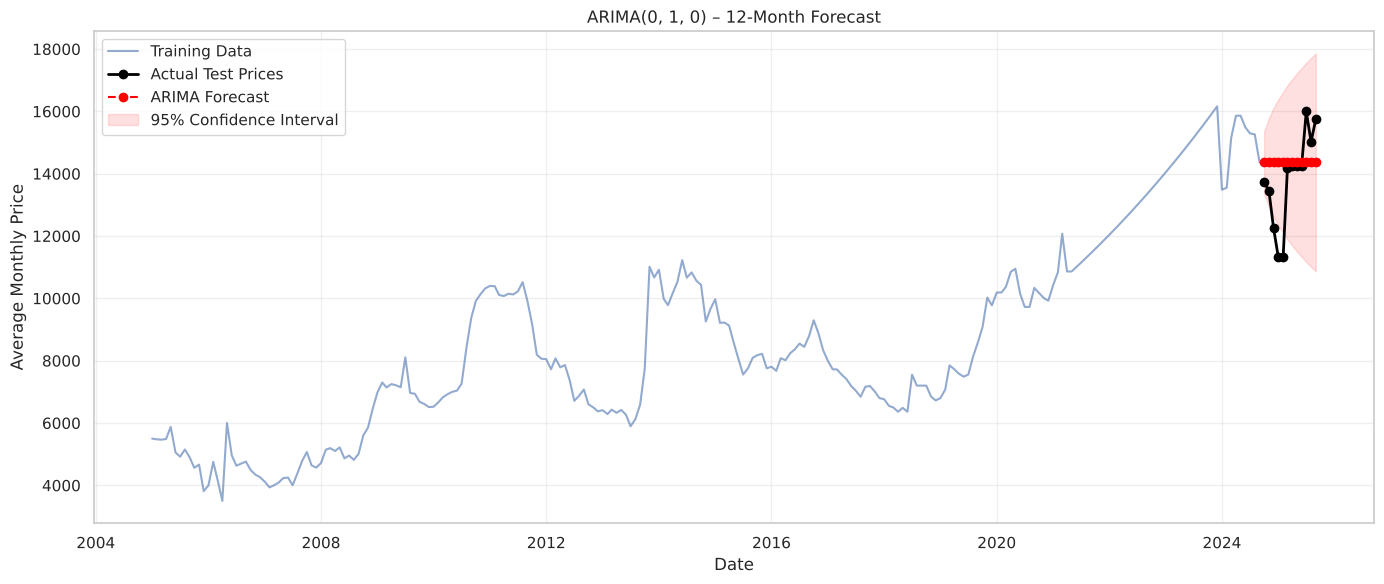

In [58]:
plt.figure(figsize=(14, 6))

# Plot training history
plt.plot(
    train.index,
    train,
    label="Training Data",
    alpha=0.6
)

# Plot actual testing prices
plt.plot(
    test.index,
    test,
    label="Actual Test Prices",
    color="black",
    linewidth=2,
    marker="o"
)

# Plot ARIMA forecast
plt.plot(
    arima_forecast.index,
    arima_forecast,
    label="ARIMA Forecast",
    color="red",
    linestyle="--",
    marker="o"
)

# Plot confidence interval
plt.fill_between(
    test.index,
    arima_confidence.iloc[:, 0].to_numpy(),
    arima_confidence.iloc[:, 1].to_numpy(),
    color="red",
    alpha=0.12,
    label="95% Confidence Interval"
)

plt.title(f"ARIMA{best_order} – 12-Month Forecast")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.3.8 ARIMA Model Development Conclusion

ARIMA candidates were evaluated on the training data using AIC and BIC.
The selected configuration (printed above) is a random-walk model
without drift, ARIMA(0,1,0).

Such a model produces a constant forecast equal to the last observed
training value, so its point forecasts and evaluation metrics are
identical to the Naive baseline. ARIMA therefore did not improve on the
Naive benchmark on the holdout; it is retained for comparison.


### 7.4 SARIMA Model Development

SARIMA extends ARIMA by incorporating seasonal
autoregressive, differencing, and moving-average components.

Since the dataset contains monthly observations,
a seasonal period of 12 is considered.

The model is trained exclusively on the training dataset.
The testing dataset remains untouched until final evaluation.

First-order non-seasonal differencing is initially retained
based on the training-only ADF analysis.

In [59]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings

# Prepare monthly training series
train_series = train.astype(float).asfreq("MS")

# Define SARIMA parameters
d_order = 1
seasonal_period = 12

print("SARIMA TRAINING DATA")
print("-" * 45)

print("Observations:", len(train_series))
print("Start Date:", train_series.index.min())
print("End Date:", train_series.index.max())
print("Non-seasonal differencing (d):", d_order)
print("Seasonal period (m):", seasonal_period)

SARIMA TRAINING DATA
---------------------------------------------
Observations: 237
Start Date: 2005-01-01 00:00:00
End Date: 2024-09-01 00:00:00
Non-seasonal differencing (d): 1
Seasonal period (m): 12


#### 7.4.2 SARIMA parameter selection

In [60]:
# Store SARIMA candidate results
sarima_candidates = []
sarima_failures = []

# Define parameter ranges
p_values = range(2)
q_values = range(2)
P_values = range(2)
Q_values = range(2)
D_values = range(2)

# Search across candidate combinations
for p in p_values:
    for q in q_values:
        for P in P_values:
            for Q in Q_values:
                for D in D_values:

                    order = (p, d_order, q)
                    seasonal_order = (
                        P, D, Q, seasonal_period
                    )

                    try:
                        with warnings.catch_warnings(record=True):
                            warnings.simplefilter("always")

                            candidate_model = SARIMAX(
                                train_series,
                                order=order,
                                seasonal_order=seasonal_order,
                                enforce_stationarity=True,
                                enforce_invertibility=True
                            )

                            candidate_fit = candidate_model.fit(
                                disp=False,
                                maxiter=200
                            )

                        converged = candidate_fit.mle_retvals.get(
                            "converged", True
                        )

                        sarima_candidates.append({
                            "p": p,
                            "d": d_order,
                            "q": q,
                            "P": P,
                            "D": D,
                            "Q": Q,
                            "Seasonal Period": seasonal_period,
                            "AIC": candidate_fit.aic,
                            "BIC": candidate_fit.bic,
                            "Converged": converged
                        })

                    except Exception as error:
                        sarima_failures.append({
                            "Order": order,
                            "Seasonal Order": seasonal_order,
                            "Error": str(error)
                        })

# Create candidate comparison table
sarima_results = pd.DataFrame(sarima_candidates)

if sarima_results.empty:
    raise ValueError("No SARIMA candidates were fitted successfully.")

# Retain converged candidates for selection
converged_sarima = sarima_results[
    sarima_results["Converged"] == True
].copy()

if converged_sarima.empty:
    raise ValueError(
        "No SARIMA candidate converged. "
        "Inspect the fitting results before proceeding."
    )

# Sort by AIC
converged_sarima = converged_sarima.sort_values(
    "AIC"
).reset_index(drop=True)

print("SARIMA SEARCH SUMMARY")
print("-" * 45)

print("Candidates fitted:", len(sarima_results))
print("Converged candidates:", len(converged_sarima))
print("Failed candidates:", len(sarima_failures))

print("\nTOP 10 SARIMA CANDIDATES")

display(
    converged_sarima.head(10).round(2)
)

SARIMA SEARCH SUMMARY
---------------------------------------------
Candidates fitted: 32
Converged candidates: 32
Failed candidates: 0

TOP 10 SARIMA CANDIDATES


,p,d,q,P,D,Q,Seasonal Period,AIC,BIC,Converged
0,0,1,0,0,1,1,12,3474.45,3481.28,True
1,0,1,0,1,1,1,12,3475.04,3485.28,True
2,1,1,0,0,1,1,12,3475.54,3485.78,True
3,0,1,1,0,1,1,12,3476.10,3486.34,True
4,0,1,1,1,1,1,12,3476.23,3489.88,True
5,1,1,0,1,1,1,12,3477.73,3491.37,True
6,1,1,1,0,1,1,12,3478.45,3492.10,True
7,1,1,1,1,1,1,12,3479.04,3496.10,True
8,1,1,0,1,1,0,12,3526.42,3536.65,True
9,0,1,1,1,1,0,12,3526.43,3536.66,True


#### 7.4.3 Fit the selected SARIMA model

In [61]:
# Select the candidate with the lowest AIC
best_sarima_candidate = converged_sarima.iloc[0]

best_sarima_order = (
    int(best_sarima_candidate["p"]),
    int(best_sarima_candidate["d"]),
    int(best_sarima_candidate["q"])
)

best_sarima_seasonal_order = (
    int(best_sarima_candidate["P"]),
    int(best_sarima_candidate["D"]),
    int(best_sarima_candidate["Q"]),
    seasonal_period
)

print("SELECTED SARIMA MODEL")
print("-" * 45)

print("Order:", best_sarima_order)
print("Seasonal Order:", best_sarima_seasonal_order)
print("AIC:", round(best_sarima_candidate["AIC"], 2))
print("BIC:", round(best_sarima_candidate["BIC"], 2))

# Fit the selected model using training data only
sarima_model = SARIMAX(
    train_series,
    order=best_sarima_order,
    seasonal_order=best_sarima_seasonal_order,
    enforce_stationarity=True,
    enforce_invertibility=True
).fit(disp=False, maxiter=200)

# Display model summary
print("\nSARIMA MODEL SUMMARY")

print(sarima_model.summary())

SELECTED SARIMA MODEL
---------------------------------------------
Order: (0, 1, 0)
Seasonal Order: (0, 1, 1, 12)
AIC: 3474.45
BIC: 3481.28

SARIMA MODEL SUMMARY
                                      SARIMAX Results                                       
Dep. Variable:                    avg_monthly_price   No. Observations:                  237
Model:             SARIMAX(0, 1, 0)x(0, 1, [1], 12)   Log Likelihood               -1735.226
Date:                              Tue, 03 Nov 2026   AIC                           3474.453
Time:                                      02:29:34   BIC                           3481.276
Sample:                                  01-01-2005   HQIC                          3477.207
                                       - 09-01-2024                                         
Covariance Type:                                opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
--------------

### 7.4.4 SARIMA Residual Diagnostics

Residual diagnostics are performed to assess whether the
selected SARIMA model has captured the underlying patterns
in the training data.

We examine residual distribution, autocorrelation,
and the Ljung-Box test.

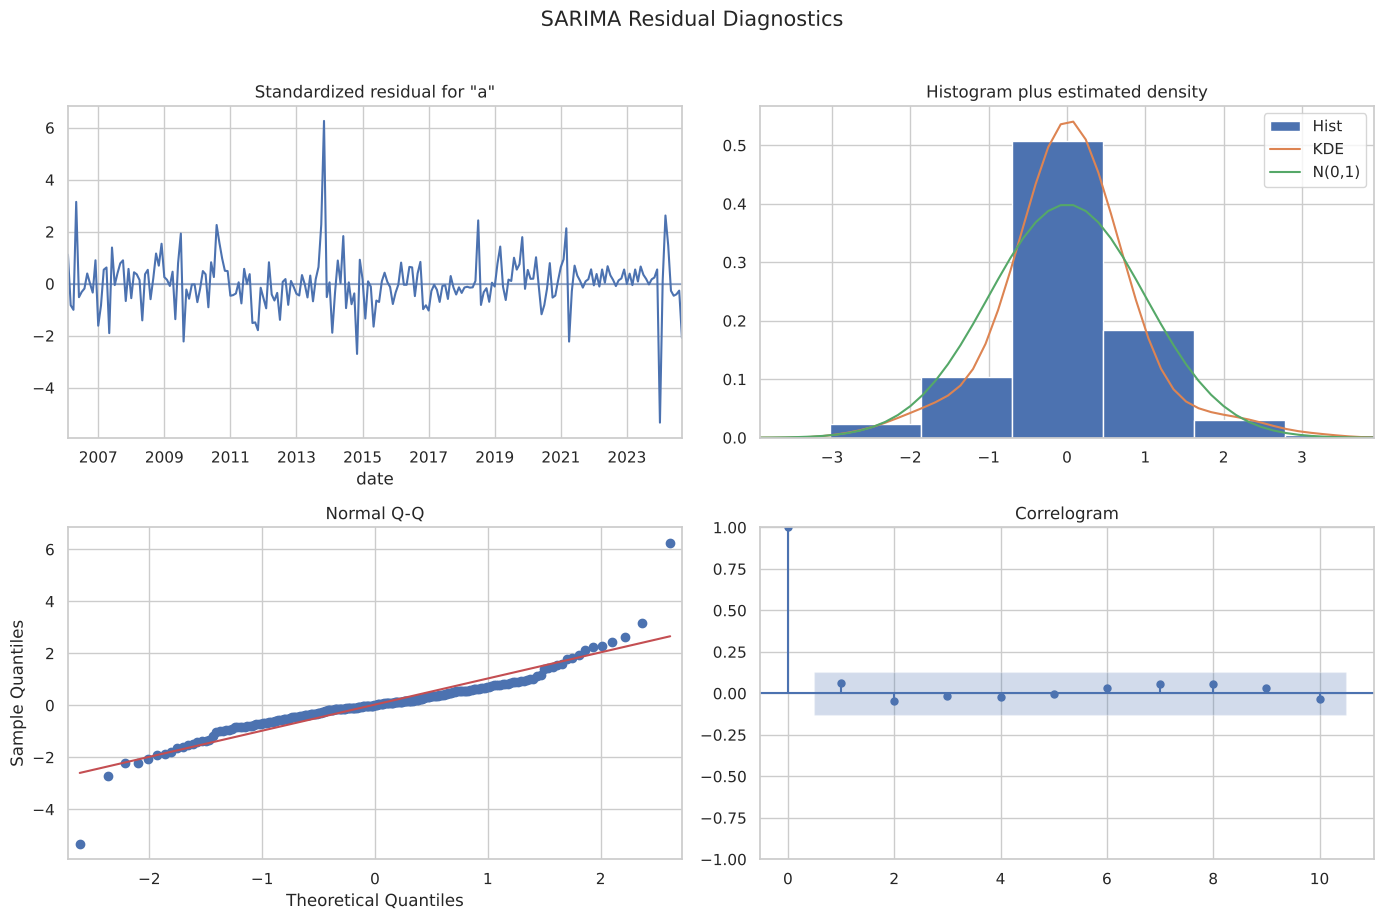

LJUNG-BOX TEST RESULTS


,lb_stat,lb_pvalue
12,14.0452,0.2978
24,26.6214,0.3224


In [62]:
from statsmodels.stats.diagnostic import acorr_ljungbox

# Plot residual diagnostics
sarima_model.plot_diagnostics(figsize=(14, 9))

plt.suptitle(
    "SARIMA Residual Diagnostics",
    fontsize=15,
    y=1.02
)

plt.tight_layout()
plt.show()

# Ljung-Box test
sarima_residuals = pd.Series(
    sarima_model.resid
).dropna()

ljung_box_results = acorr_ljungbox(
    sarima_residuals,
    lags=[12, 24],
    return_df=True
)

print("LJUNG-BOX TEST RESULTS")

display(ljung_box_results.round(4))

#### 7.4.5 Generate the 12-month SARIMA forecast

In [63]:
# Generate 12-month forecast
sarima_forecast_result = sarima_model.get_forecast(
    steps=len(test)
)

# Extract forecast predictions
sarima_forecast = pd.Series(
    sarima_forecast_result.predicted_mean.to_numpy(),
    index=test.index,
    name="SARIMA Forecast"
)

# Extract confidence intervals
sarima_confidence = sarima_forecast_result.conf_int()

# Align confidence interval dates
sarima_confidence.index = test.index

# Create forecast comparison table
sarima_forecast_table = pd.DataFrame({
    "Actual Price": test,
    "SARIMA Forecast": sarima_forecast,
    "Lower Confidence Limit": sarima_confidence.iloc[:, 0],
    "Upper Confidence Limit": sarima_confidence.iloc[:, 1]
})

print("SARIMA 12-MONTH FORECAST")

display(sarima_forecast_table.round(2))

SARIMA 12-MONTH FORECAST


,Actual Price,SARIMA Forecast,Lower Confidence Limit,Upper Confidence Limit
date,,,,
2024-10-01,13738.0,14477.82,13428.63,15527.00
2024-11-01,13438.0,14567.66,13083.89,16051.43
2024-12-01,12250.0,14503.00,12685.75,16320.24
2025-01-01,11313.0,14422.36,12324.04,16520.68
2025-02-01,11313.0,14423.88,12078.08,16769.69
2025-03-01,14188.0,14748.04,12178.48,17317.60
2025-04-01,14263.0,14743.41,11968.08,17518.74
2025-05-01,14263.0,14874.26,11907.39,17841.12
2025-06-01,14263.0,14723.24,11576.48,17870.01


#### 7.4.6 Evaluate SARIMA performance

In [64]:
# Calculate SARIMA metrics
sarima_metrics = pd.DataFrame({
    "SARIMA": evaluate_forecast(
        test,
        sarima_forecast
    )
}).T

# Compare all previously evaluated models
model_comparison = pd.concat([
    baseline_metrics,
    arima_metrics,
    sarima_metrics
])

# Sort models by RMSE
model_comparison = model_comparison.sort_values(
    "RMSE"
)

print("BASELINE, ARIMA AND SARIMA COMPARISON")

display(model_comparison.round(2))

BASELINE, ARIMA AND SARIMA COMPARISON


,MAE,RMSE,MAPE (%)
Naive,1160.33,1565.74,9.12
ARIMA,1160.33,1565.74,9.12
SARIMA,1228.86,1573.32,9.71
Seasonal Naive,1715.04,1947.09,13.08
Historical Mean,5278.23,5478.42,37.45


#### 7.4.7 Visualize SARIMA forecasts

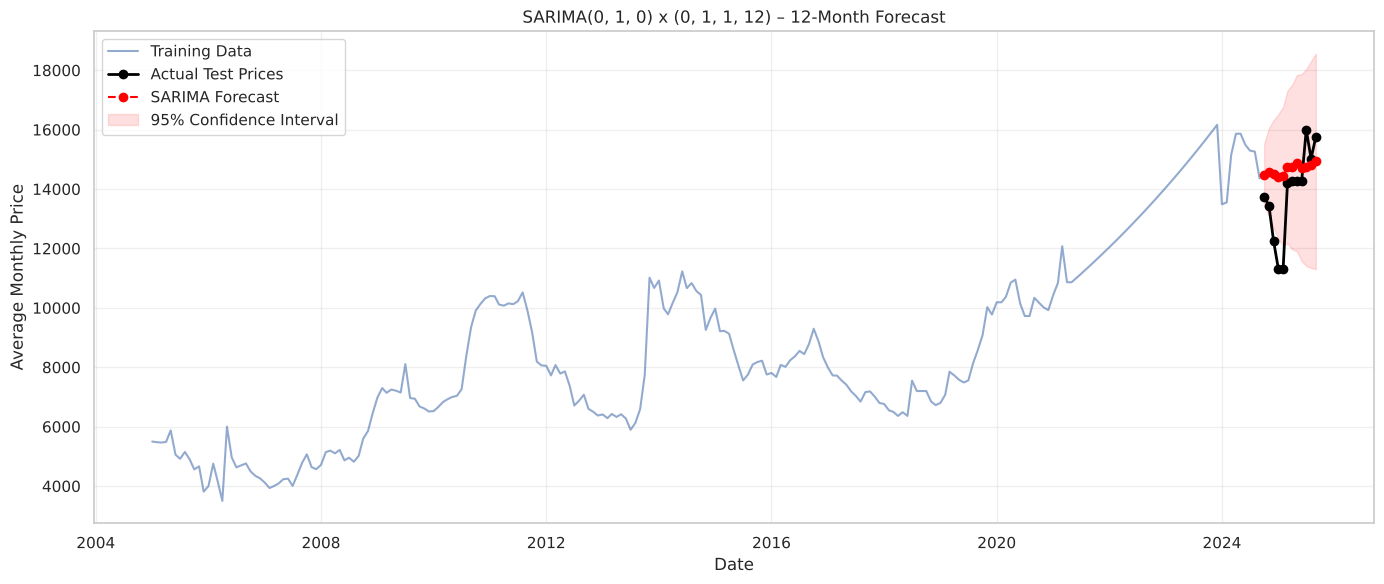

In [65]:
plt.figure(figsize=(14, 6))

# Training data
plt.plot(
    train_series.index,
    train_series,
    label="Training Data",
    alpha=0.6
)

# Actual test prices
plt.plot(
    test.index,
    test,
    label="Actual Test Prices",
    color="black",
    linewidth=2,
    marker="o"
)

# SARIMA predictions
plt.plot(
    sarima_forecast.index,
    sarima_forecast,
    label="SARIMA Forecast",
    color="red",
    linestyle="--",
    marker="o"
)

# Confidence interval
plt.fill_between(
    test.index,
    sarima_confidence.iloc[:, 0].to_numpy(),
    sarima_confidence.iloc[:, 1].to_numpy(),
    color="red",
    alpha=0.12,
    label="95% Confidence Interval"
)

plt.title(
    f"SARIMA{best_sarima_order}"
    f" x {best_sarima_seasonal_order} – 12-Month Forecast"
)

plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [66]:
# Adjust Ljung-Box degrees of freedom for the
# estimated seasonal MA parameter

ljung_box_adjusted = acorr_ljungbox(
    sarima_residuals,
    lags=[12, 24],
    model_df=1,
    return_df=True
)

print("ADJUSTED LJUNG-BOX TEST")

display(ljung_box_adjusted.round(4))

ADJUSTED LJUNG-BOX TEST


,lb_stat,lb_pvalue
12,14.0452,0.2305
24,26.6214,0.2724


### 7.4.8 SARIMA Model Conclusion

A grid search of 32 SARIMA configurations was performed using the
training dataset only, and the lowest-AIC converged configuration
was selected (printed above).

Residual diagnostics (Ljung-Box, adjusted for the number of estimated
parameters) show no significant remaining autocorrelation at lags 12
and 24, although the residual distribution has heavy tails.

Evaluated on the 12-month holdout, SARIMA did **not** outperform the
Naive baseline (see the comparison table above). It is retained as a
comparison model.


### 7.5 Additional Forecasting Models – Exponential Smoothing

Exponential Smoothing models are introduced to investigate
alternative forecasting approaches beyond ARIMA and SARIMA.

Holt's Linear Trend and Holt's Damped Trend methods are
implemented using the training dataset.

Both models estimate the underlying level and trend
of the historical price series.

The testing dataset remains reserved for evaluating
forecasting performance.

In [67]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

# Prepare monthly training data
train_series = train.astype(float).asfreq("MS")

print("EXPONENTIAL SMOOTHING TRAINING DATA")
print("-" * 45)

print("Observations:", len(train_series))
print("Start Date:", train_series.index.min())
print("End Date:", train_series.index.max())

EXPONENTIAL SMOOTHING TRAINING DATA
---------------------------------------------
Observations: 237
Start Date: 2005-01-01 00:00:00
End Date: 2024-09-01 00:00:00


In [68]:
# Fit Holt's Linear Trend model
holt_linear_model = ExponentialSmoothing(
    train_series,
    trend="add",
    damped_trend=False,
    seasonal=None,
    initialization_method="estimated"
).fit(optimized=True)

# Fit Holt's Damped Trend model
holt_damped_model = ExponentialSmoothing(
    train_series,
    trend="add",
    damped_trend=True,
    seasonal=None,
    initialization_method="estimated"
).fit(optimized=True)

# Display training fit statistics
holt_model_summary = pd.DataFrame({
    "Model": [
        "Holt Linear Trend",
        "Holt Damped Trend"
    ],
    "SSE": [
        holt_linear_model.sse,
        holt_damped_model.sse
    ],
    "AIC": [
        holt_linear_model.aic,
        holt_damped_model.aic
    ],
    "BIC": [
        holt_linear_model.bic,
        holt_damped_model.bic
    ]
}).set_index("Model")

print("EXPONENTIAL SMOOTHING MODEL SUMMARY")

display(holt_model_summary.round(2))

EXPONENTIAL SMOOTHING MODEL SUMMARY


,SSE,AIC,BIC
Model,,,
Holt Linear Trend,62699180.42,2967.13,2981.01
Holt Damped Trend,62830073.87,2969.63,2986.97


#### 7.5.3 Generate 12-month forecasts

In [69]:
# Generate Holt Linear Trend forecast
holt_linear_forecast = pd.Series(
    holt_linear_model.forecast(steps=len(test)).to_numpy(),
    index=test.index,
    name="Holt Linear"
)

# Generate Holt Damped Trend forecast
holt_damped_forecast = pd.Series(
    holt_damped_model.forecast(steps=len(test)).to_numpy(),
    index=test.index,
    name="Holt Damped"
)

# Compare predictions with actual prices
holt_forecast_table = pd.DataFrame({
    "Actual Price": test,
    "Holt Linear Forecast": holt_linear_forecast,
    "Holt Damped Forecast": holt_damped_forecast
})

print("HOLT MODEL 12-MONTH FORECASTS")

display(holt_forecast_table.round(2))

HOLT MODEL 12-MONTH FORECASTS


,Actual Price,Holt Linear Forecast,Holt Damped Forecast
date,,,
2024-10-01,13738.0,14399.38,14376.55
2024-11-01,13438.0,14435.75,14390.02
2024-12-01,12250.0,14472.13,14403.43
2025-01-01,11313.0,14508.51,14416.78
2025-02-01,11313.0,14544.89,14430.06
2025-03-01,14188.0,14581.26,14443.27
2025-04-01,14263.0,14617.64,14456.41
2025-05-01,14263.0,14654.02,14469.49
2025-06-01,14263.0,14690.39,14482.50


#### 7.5.4 Evaluate forecasting performance

In [70]:
# Evaluate both Holt models
holt_metrics = pd.DataFrame({
    "Holt Linear": evaluate_forecast(
        test, holt_linear_forecast
    ),
    "Holt Damped": evaluate_forecast(
        test, holt_damped_forecast
    )
}).T

print("EXPONENTIAL SMOOTHING PERFORMANCE")

display(holt_metrics.round(2))

EXPONENTIAL SMOOTHING PERFORMANCE


,MAE,RMSE,MAPE (%)
Holt Linear,1196.71,1587.35,9.49
Holt Damped,1174.13,1568.83,9.26


#### 7.5.5 Visualize the forecasts

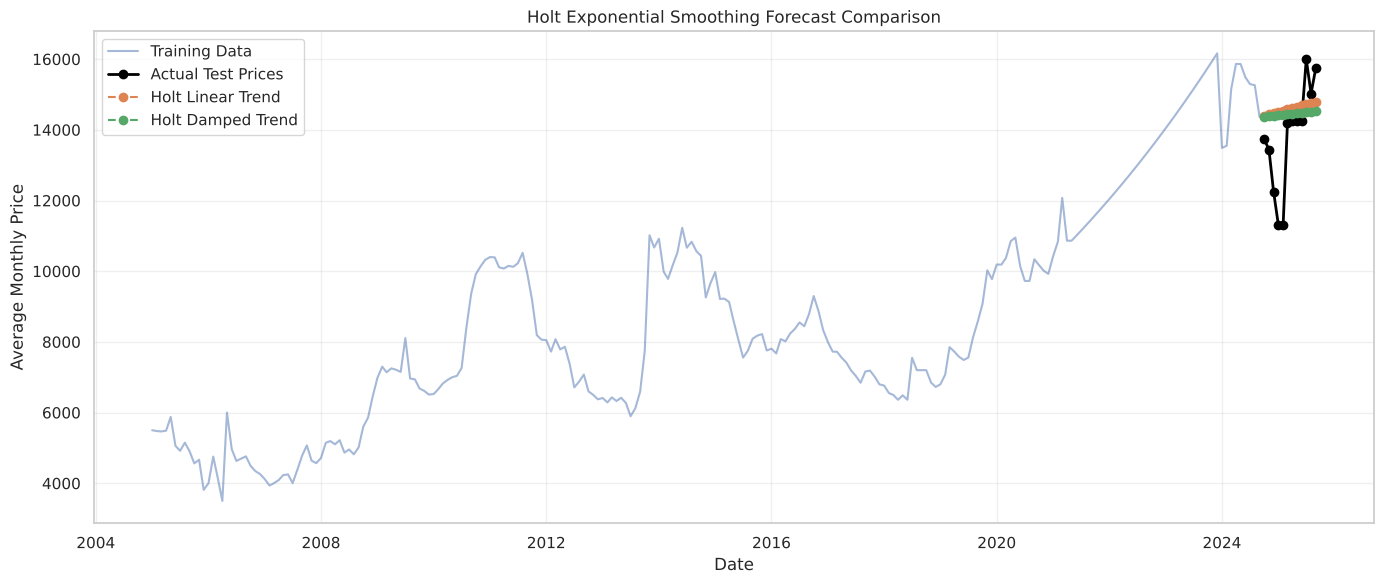

In [71]:
plt.figure(figsize=(14, 6))

plt.plot(
    train.index,
    train,
    label="Training Data",
    alpha=0.5
)

plt.plot(
    test.index,
    test,
    label="Actual Test Prices",
    color="black",
    linewidth=2,
    marker="o"
)

plt.plot(
    holt_linear_forecast.index,
    holt_linear_forecast,
    label="Holt Linear Trend",
    linestyle="--",
    marker="o"
)

plt.plot(
    holt_damped_forecast.index,
    holt_damped_forecast,
    label="Holt Damped Trend",
    linestyle="--",
    marker="o"
)

plt.title("Holt Exponential Smoothing Forecast Comparison")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.5b Additional Candidate Models

To broaden the search beyond non-seasonal level/trend models, three
further candidates are added:

1. **Holt-Winters additive seasonal** (damped trend, period 12)
2. **Holt-Winters multiplicative seasonal** (damped trend, period 12)
3. **Log-ARIMA** – ARIMA fitted on log(price) with the order selected by
   AIC on the training data, forecasts back-transformed with `exp`.
   Modelling in log space is consistent with the log-scale interpolation
   used in cleaning and treats price changes as proportional.

All models are fitted on the training data only.


In [72]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing
from statsmodels.tsa.arima.model import ARIMA
import warnings

train_series = train.astype(float).asfreq("MS")

# 1–2. Holt-Winters seasonal models
with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    hw_add_model = ExponentialSmoothing(
        train_series, trend="add", damped_trend=True,
        seasonal="add", seasonal_periods=12,
        initialization_method="estimated"
    ).fit(optimized=True)

    hw_mul_model = ExponentialSmoothing(
        train_series, trend="add", damped_trend=True,
        seasonal="mul", seasonal_periods=12,
        initialization_method="estimated"
    ).fit(optimized=True)

# 3. Log-ARIMA: select (p,q,trend) by AIC on log(train)
log_train = np.log(train_series)
log_candidates = []
for p in range(3):
    for q in range(3):
        for trend_option in ["n", "t"]:
            try:
                with warnings.catch_warnings():
                    warnings.simplefilter("ignore")
                    fit = ARIMA(log_train, order=(p, 1, q), trend=trend_option).fit()
                if getattr(fit, "mle_retvals", {}).get("converged", True):
                    log_candidates.append({"p": p, "d": 1, "q": q, "Trend": trend_option,
                                           "AIC": fit.aic, "BIC": fit.bic})
            except Exception:
                continue

log_arima_results = pd.DataFrame(log_candidates).sort_values("AIC").reset_index(drop=True)
best_log = log_arima_results.iloc[0]
log_arima_order = (int(best_log["p"]), 1, int(best_log["q"]))
log_arima_trend = best_log["Trend"]

with warnings.catch_warnings():
    warnings.simplefilter("ignore")
    log_arima_model = ARIMA(log_train, order=log_arima_order, trend=log_arima_trend).fit()

print("LOG-ARIMA SELECTION (top 5 by AIC)")
display(log_arima_results.head(5).round(2))
print("Selected Log-ARIMA order:", log_arima_order, "trend:", log_arima_trend)

print("\nHOLT-WINTERS TRAINING FIT")
display(pd.DataFrame({
    "Model": ["Holt-Winters Additive", "Holt-Winters Multiplicative"],
    "SSE": [hw_add_model.sse, hw_mul_model.sse],
    "AIC": [hw_add_model.aic, hw_mul_model.aic],
    "BIC": [hw_add_model.bic, hw_mul_model.bic],
}).set_index("Model").round(2))


LOG-ARIMA SELECTION (top 5 by AIC)


,p,d,q,Trend,AIC,BIC
0,2,1,2,n,-589.42,-572.10
1,0,1,0,n,-588.41,-584.94
2,2,1,2,t,-588.39,-567.60
3,0,1,1,n,-587.52,-580.59
4,1,1,0,n,-587.35,-580.43


Selected Log-ARIMA order: (2, 1, 2) trend: n

HOLT-WINTERS TRAINING FIT


,SSE,AIC,BIC
Model,,,
Holt-Winters Additive,62292267.60,2991.59,3050.55
Holt-Winters Multiplicative,60161572.34,2983.34,3042.30


In [73]:
# 12-month holdout forecasts for the additional models
hw_add_forecast = pd.Series(hw_add_model.forecast(len(test)).to_numpy(),
                            index=test.index, name="Holt-Winters Additive")
hw_mul_forecast = pd.Series(hw_mul_model.forecast(len(test)).to_numpy(),
                            index=test.index, name="Holt-Winters Multiplicative")
log_arima_forecast = pd.Series(np.exp(log_arima_model.forecast(len(test)).to_numpy()),
                               index=test.index, name="Log-ARIMA")

additional_forecast_table = pd.DataFrame({
    "Actual Price": test,
    "Holt-Winters Additive": hw_add_forecast,
    "Holt-Winters Multiplicative": hw_mul_forecast,
    "Log-ARIMA": log_arima_forecast
})
print("ADDITIONAL MODELS – 12-MONTH FORECASTS")
display(additional_forecast_table.round(2))

additional_metrics = pd.DataFrame({
    "Holt-Winters Additive": evaluate_forecast(test, hw_add_forecast),
    "Holt-Winters Multiplicative": evaluate_forecast(test, hw_mul_forecast),
    "Log-ARIMA": evaluate_forecast(test, log_arima_forecast),
}).T
print("ADDITIONAL MODELS – HOLDOUT PERFORMANCE")
display(additional_metrics.round(2))


ADDITIONAL MODELS – 12-MONTH FORECASTS


,Actual Price,Holt-Winters Additive,Holt-Winters Multiplicative,Log-ARIMA
date,,,,
2024-10-01,13738.0,14373.94,14439.46,14366.64
2024-11-01,13438.0,14362.13,14479.97,14339.69
2024-12-01,12250.0,14155.47,14335.21,14357.57
2025-01-01,11313.0,14118.17,14083.44,14367.06
2025-02-01,11313.0,14202.99,13965.98,14344.08
2025-03-01,14188.0,14412.53,14327.94,14353.77
2025-04-01,14263.0,14177.44,14284.50,14366.20
2025-05-01,14263.0,14339.68,14403.97,14348.05
2025-06-01,14263.0,14166.03,14144.96,14351.41


ADDITIONAL MODELS – HOLDOUT PERFORMANCE


,MAE,RMSE,MAPE (%)
Holt-Winters Additive,1167.30,1528.06,9.05
Holt-Winters Multiplicative,1162.18,1509.97,9.00
Log-ARIMA,1156.19,1562.74,9.08


### 7.5c Shared Model Registry

To guarantee that **exactly the same model specification** is used in
the holdout evaluation, the walk-forward validation, the rolling-origin
evaluation, the sensitivity analysis and the final forecast, every
model is wrapped in a single function `fit_forecast(name, history, steps)`.

Model orders selected on the training data in Sections 7.3–7.5b are
reused; only the parameters are re-estimated on each history window.


In [74]:
from statsmodels.tsa.statespace.sarimax import SARIMAX

MODEL_NAMES = [
    "Naive", "Seasonal Naive", "Historical Mean",
    "ARIMA", "SARIMA", "Holt Linear", "Holt Damped",
    "Holt-Winters Additive", "Holt-Winters Multiplicative", "Log-ARIMA"
]

# Minimum history each model needs to be fitted sensibly
MIN_OBS = {
    "Naive": 1, "Seasonal Naive": 12, "Historical Mean": 1,
    "ARIMA": 5, "Log-ARIMA": 5, "SARIMA": 30,
    "Holt Linear": 5, "Holt Damped": 5,
    "Holt-Winters Additive": 30, "Holt-Winters Multiplicative": 30
}


def _fit_model(name, history):
    """Fit one model on `history` and return the fitted results object (or None)."""
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        if name == "ARIMA":
            return ARIMA(history, order=best_order, trend=best_trend).fit()
        if name == "Log-ARIMA":
            return ARIMA(np.log(history), order=log_arima_order, trend=log_arima_trend).fit()
        if name == "SARIMA":
            return SARIMAX(history, order=best_sarima_order,
                           seasonal_order=best_sarima_seasonal_order,
                           enforce_stationarity=True, enforce_invertibility=True
                           ).fit(disp=False, maxiter=200)
        if name == "Holt Linear":
            return ExponentialSmoothing(history, trend="add", damped_trend=False,
                                        seasonal=None, initialization_method="estimated").fit(optimized=True)
        if name == "Holt Damped":
            return ExponentialSmoothing(history, trend="add", damped_trend=True,
                                        seasonal=None, initialization_method="estimated").fit(optimized=True)
        if name == "Holt-Winters Additive":
            return ExponentialSmoothing(history, trend="add", damped_trend=True, seasonal="add",
                                        seasonal_periods=12, initialization_method="estimated").fit(optimized=True)
        if name == "Holt-Winters Multiplicative":
            return ExponentialSmoothing(history, trend="add", damped_trend=True, seasonal="mul",
                                        seasonal_periods=12, initialization_method="estimated").fit(optimized=True)
    return None


def fit_forecast(name, history, steps):
    """Fit `name` on `history` (pd.Series, monthly) and return a numpy array of `steps` point forecasts."""
    history = history.astype(float).asfreq("MS")
    if len(history) < MIN_OBS[name]:
        raise ValueError(f"{name} needs at least {MIN_OBS[name]} observations, got {len(history)}")

    if name == "Naive":
        return np.repeat(history.iloc[-1], steps)
    if name == "Seasonal Naive":
        return np.resize(history.iloc[-12:].to_numpy(), steps)
    if name == "Historical Mean":
        return np.repeat(history.mean(), steps)

    fitted = _fit_model(name, history)
    forecast = fitted.forecast(steps)
    forecast = np.asarray(forecast, dtype=float)
    if name == "Log-ARIMA":
        forecast = np.exp(forecast)
    return forecast


# Consistency check: registry reproduces the holdout forecasts computed above
check = {
    "Naive": naive_forecast, "Seasonal Naive": seasonal_naive_forecast,
    "Historical Mean": historical_mean_forecast, "ARIMA": arima_forecast,
    "SARIMA": sarima_forecast, "Holt Linear": holt_linear_forecast,
    "Holt Damped": holt_damped_forecast, "Holt-Winters Additive": hw_add_forecast,
    "Holt-Winters Multiplicative": hw_mul_forecast, "Log-ARIMA": log_arima_forecast
}
for name, reference in check.items():
    reproduced = fit_forecast(name, train, len(test))
    assert np.allclose(reproduced, reference.to_numpy(), rtol=1e-3, atol=1.0), f"Registry mismatch for {name}"
print("Model registry reproduces all holdout forecasts: OK")


Model registry reproduces all holdout forecasts: OK


In [75]:
all_model_metrics = pd.concat([
    baseline_metrics,
    arima_metrics,
    sarima_metrics,
    holt_metrics
])

all_model_metrics = all_model_metrics.sort_values("RMSE")

print("COMPLETE MODEL PERFORMANCE COMPARISON")

display(all_model_metrics.round(2))

COMPLETE MODEL PERFORMANCE COMPARISON


,MAE,RMSE,MAPE (%)
Naive,1160.33,1565.74,9.12
ARIMA,1160.33,1565.74,9.12
Holt Damped,1174.13,1568.83,9.26
SARIMA,1228.86,1573.32,9.71
Holt Linear,1196.71,1587.35,9.49
Seasonal Naive,1715.04,1947.09,13.08
Historical Mean,5278.23,5478.42,37.45


### 7.5.6 Exponential Smoothing Model Conclusion

Holt's Linear Trend and Holt's Damped Trend were trained on the 237
training observations and evaluated over the same 12-month holdout.

Neither model outperformed the Naive forecasting baseline on the
holdout (see table above). Both are retained for comparison.

The next section adds seasonal exponential smoothing and a
log-scale ARIMA so that the comparison is not limited to
non-seasonal level/trend models.


### 7.6 Comprehensive Forecasting Model Evaluation

In this section, all ten developed forecasting models are
compared using a common set of evaluation metrics.

The models are evaluated using MAE, RMSE, and MAPE
over the same 12-month testing period.

The objective is to identify the most accurate forecasting
approach based on unseen test observations.

In [76]:
# Collect all model forecasts
model_forecasts = {
    "Naive": naive_forecast,
    "Seasonal Naive": seasonal_naive_forecast,
    "Historical Mean": historical_mean_forecast,
    "ARIMA": arima_forecast,
    "SARIMA": sarima_forecast,
    "Holt Linear": holt_linear_forecast,
    "Holt Damped": holt_damped_forecast,
    "Holt-Winters Additive": hw_add_forecast,
    "Holt-Winters Multiplicative": hw_mul_forecast,
    "Log-ARIMA": log_arima_forecast
}

# Verify that all forecasts cover the same testing dates
for model_name, prediction in model_forecasts.items():
    assert prediction.index.equals(test.index), (
        f"Date mismatch in {model_name}"
    )

# Recalculate all metrics consistently
all_model_metrics = pd.DataFrame({
    model_name: evaluate_forecast(test, prediction)
    for model_name, prediction in model_forecasts.items()
}).T

# Sort according to RMSE
all_model_metrics = all_model_metrics.sort_values("RMSE")

print("COMPLETE FORECASTING MODEL COMPARISON")
print("-" * 55)

display(all_model_metrics.round(2))

COMPLETE FORECASTING MODEL COMPARISON
-------------------------------------------------------


,MAE,RMSE,MAPE (%)
Holt-Winters Multiplicative,1162.18,1509.97,9.00
Holt-Winters Additive,1167.30,1528.06,9.05
Log-ARIMA,1156.19,1562.74,9.08
Naive,1160.33,1565.74,9.12
ARIMA,1160.33,1565.74,9.12
Holt Damped,1174.13,1568.83,9.26
SARIMA,1228.86,1573.32,9.71
Holt Linear,1196.71,1587.35,9.49
Seasonal Naive,1715.04,1947.09,13.08
Historical Mean,5278.23,5478.42,37.45


#### 7.6.2 Visualize model performance


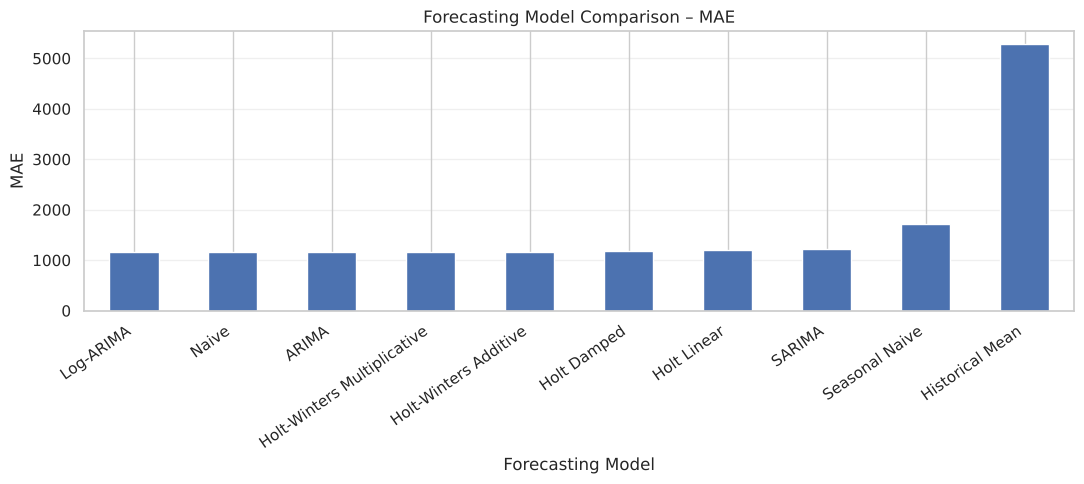

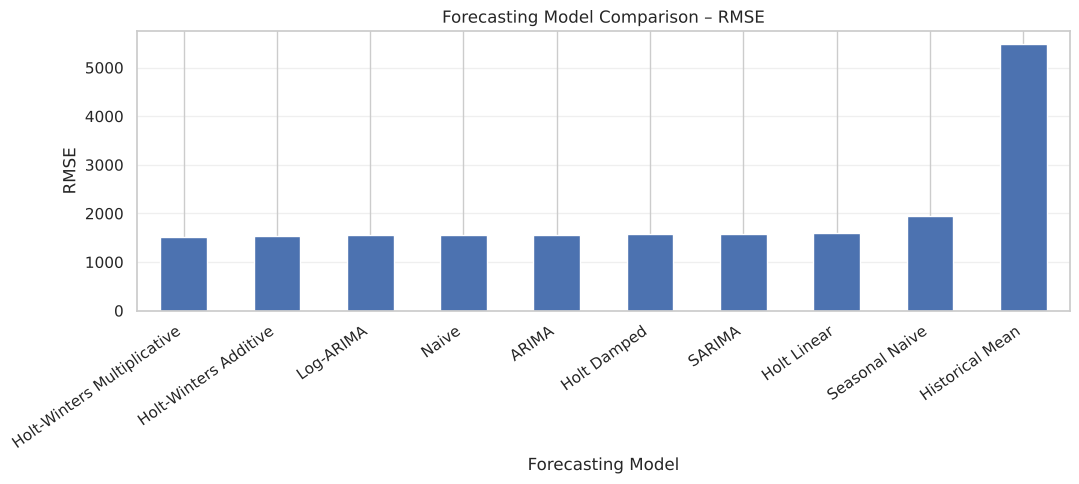

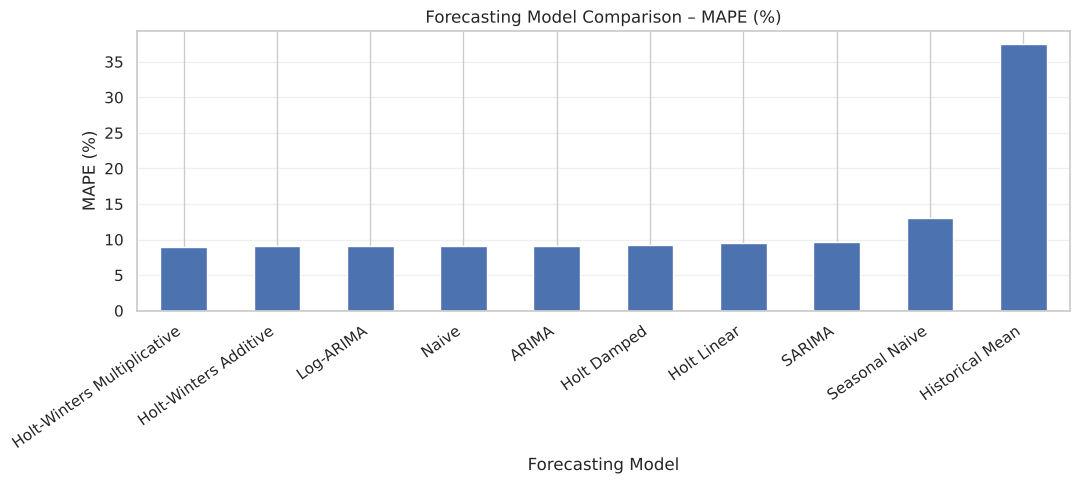

In [77]:
metrics_to_plot = ["MAE", "RMSE", "MAPE (%)"]

for metric in metrics_to_plot:

    sorted_metric = all_model_metrics[metric].sort_values()

    plt.figure(figsize=(11, 5))

    sorted_metric.plot(kind="bar")

    plt.title(f"Forecasting Model Comparison – {metric}")
    plt.xlabel("Forecasting Model")
    plt.ylabel(metric)

    plt.xticks(rotation=35, ha="right")
    plt.grid(axis="y", alpha=0.3)

    plt.tight_layout()
    plt.show()

#### 7.6.3 Actual vs predicted price comparison

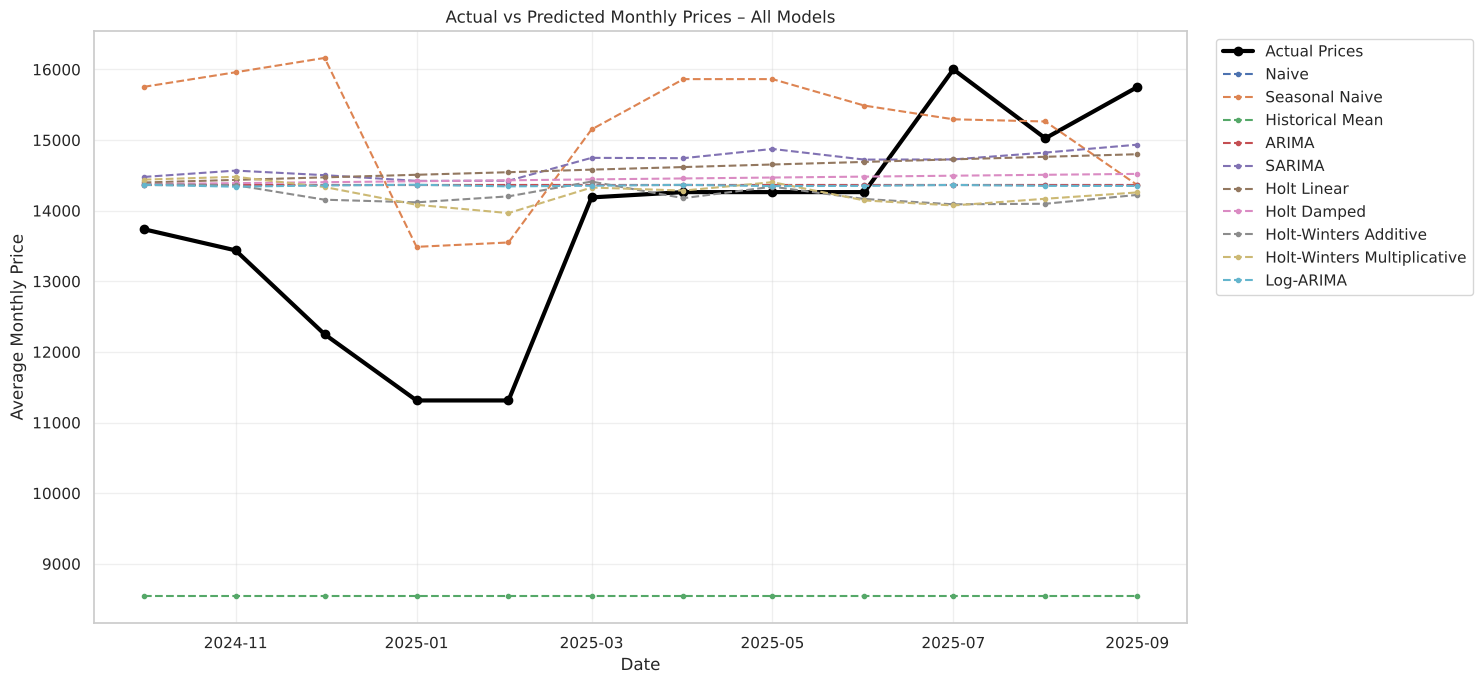

In [78]:
plt.figure(figsize=(15, 7))

# Actual testing prices
plt.plot(
    test.index,
    test,
    label="Actual Prices",
    color="black",
    linewidth=3,
    marker="o"
)

# Predictions from all models
for model_name, prediction in model_forecasts.items():

    plt.plot(
        prediction.index,
        prediction,
        label=model_name,
        linestyle="--",
        marker="."
    )

plt.title("Actual vs Predicted Monthly Prices – All Models")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")

plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.6.4 Forecast Error Analysis

Forecast errors are examined at the monthly level to identify
periods where models produce relatively large prediction errors.

Absolute errors are compared across all forecasting
approaches to understand their strengths and limitations.

In [79]:
# Calculate absolute error for every model and test month
absolute_errors = pd.DataFrame({
    model_name: np.abs(test - prediction)
    for model_name, prediction in model_forecasts.items()
})

absolute_errors.index.name = "Date"

print("MONTHLY ABSOLUTE FORECASTING ERRORS")

display(absolute_errors.round(2))
# Summarize forecasting errors
error_summary = pd.DataFrame({
    "MAE": absolute_errors.mean(),
    "Maximum Absolute Error": absolute_errors.max(),
    "Worst Performing Month": absolute_errors.idxmax().map(lambda x: x.strftime("%b %Y"))
})

error_summary = error_summary.sort_values("MAE")

display(error_summary.round(2))

MONTHLY ABSOLUTE FORECASTING ERRORS


,Naive,Seasonal Naive,Historical Mean,ARIMA,SARIMA,Holt Linear,Holt Damped,Holt-Winters Additive,Holt-Winters Multiplicative,Log-ARIMA
Date,,,,,,,,,,
2024-10-01,625.0,2015.27,5199.23,625.0,739.82,661.38,638.55,635.94,701.46,628.64
2024-11-01,925.0,2522.18,4899.23,925.0,1129.66,997.75,952.02,924.13,1041.97,901.69
2024-12-01,2113.0,3913.00,3711.23,2113.0,2253.00,2222.13,2153.43,1905.47,2085.21,2107.57
2025-01-01,3050.0,2175.00,2774.23,3050.0,3109.36,3195.51,3103.78,2805.17,2770.44,3054.06
2025-02-01,3050.0,2237.00,2774.23,3050.0,3110.88,3231.89,3117.06,2889.99,2652.98,3031.08
2025-03-01,175.0,962.00,5649.23,175.0,560.04,393.26,255.27,224.53,139.94,165.77
2025-04-01,100.0,1600.00,5724.23,100.0,480.41,354.64,193.41,85.56,21.50,103.20
2025-05-01,100.0,1600.00,5724.23,100.0,611.26,391.02,206.49,76.68,140.97,85.05
2025-06-01,100.0,1225.00,5724.23,100.0,460.24,427.39,219.50,96.97,118.04,88.41


,MAE,Maximum Absolute Error,Worst Performing Month
Log-ARIMA,1156.19,3054.06,Jan 2025
Naive,1160.33,3050.00,Jan 2025
ARIMA,1160.33,3050.00,Jan 2025
Holt-Winters Multiplicative,1162.18,2770.44,Jan 2025
Holt-Winters Additive,1167.30,2889.99,Feb 2025
Holt Damped,1174.13,3117.06,Feb 2025
Holt Linear,1196.71,3231.89,Feb 2025
SARIMA,1228.86,3110.88,Feb 2025
Seasonal Naive,1715.04,3913.00,Dec 2024
Historical Mean,5278.23,7461.23,Jul 2025


#### 7.6.5 Identify the best-performing model

In [80]:
print("BEST MODEL BY EVALUATION METRIC")
print("-" * 45)

for metric in ["MAE", "RMSE", "MAPE (%)"]:

    best_model = all_model_metrics[metric].idxmin()
    best_value = all_model_metrics[metric].min()

    print(f"{metric}: {best_model} ({best_value:.2f})")

BEST MODEL BY EVALUATION METRIC
---------------------------------------------
MAE: Log-ARIMA (1156.19)
RMSE: Holt-Winters Multiplicative (1509.97)
MAPE (%): Holt-Winters Multiplicative (9.00)


### 7.6.6 Model Evaluation Limitations

The forecasting models were evaluated using a single
chronological 12-month testing period.

The evaluation provides a consistent comparison across
all models, but performance may vary across different
historical forecasting periods.

The training dataset also contains 30 observations estimated
using logarithmic interpolation.

These estimates may influence model fitting and forecasting
performance.

Additionally, the testing period contains substantial price
fluctuations, which can affect the evaluation metrics.

Further validation using multiple historical forecasting
origins is recommended before making strong conclusions
about general forecasting performance.

### 7.7 Walk-Forward Validation (one-step-ahead)

Walk-forward validation examines forecasting performance across
multiple historical forecast origins with an expanding training window.
At each iteration the model is re-estimated on all observations before
the forecast month and predicts that month.

Validation covers January–September 2024. The final 12-month testing
dataset remains untouched.

Model orders are those selected on the training data in Sections
7.3–7.5b (via the shared registry); parameters are re-estimated at
every step.

> **Caveat.** Every Seasonal Naive prediction in this window is the
> *interpolated* value for the same month of 2023. Its score here
> therefore measures how well the interpolation line happens to track
> 2024, not genuine seasonal skill. This is quantified in Section 7.9.


In [81]:
# Define initial training period
initial_history = train.loc[:"2023-12-01"].copy()

# Define walk-forward validation period
walk_forward_actual = train.loc["2024-01-01":"2024-09-01"].copy()

print("WALK-FORWARD VALIDATION DESIGN")
print("-" * 50)

print("Initial training observations:", len(initial_history))
print("Initial training start:", initial_history.index.min())
print("Initial training end:", initial_history.index.max())

print("\nValidation observations:", len(walk_forward_actual))
print("Validation start:", walk_forward_actual.index.min())
print("Validation end:", walk_forward_actual.index.max())

print("\nFinal test observations preserved:", len(test))

WALK-FORWARD VALIDATION DESIGN
--------------------------------------------------
Initial training observations: 228
Initial training start: 2005-01-01 00:00:00
Initial training end: 2023-12-01 00:00:00

Validation observations: 9
Validation start: 2024-01-01 00:00:00
Validation end: 2024-09-01 00:00:00

Final test observations preserved: 12


#### 7.7.2 Perform expanding-window walk-forward validation

In [82]:
# Store walk-forward predictions
walk_forward_predictions = []

for forecast_date in walk_forward_actual.index:

    # Use observations strictly before the forecast month
    history = train.loc[train.index < forecast_date]
    row = {"Date": forecast_date, "Actual": float(walk_forward_actual.loc[forecast_date])}

    for name in MODEL_NAMES:
        row[name] = float(fit_forecast(name, history, 1)[0])

    walk_forward_predictions.append(row)

walk_forward_results = pd.DataFrame(walk_forward_predictions).set_index("Date")

print("WALK-FORWARD FORECAST RESULTS (one-step-ahead)")
display(walk_forward_results.round(2))


WALK-FORWARD FORECAST RESULTS (one-step-ahead)


,Actual,Naive,Seasonal Naive,Historical Mean,ARIMA,SARIMA,Holt Linear,Holt Damped,Holt-Winters Additive,Holt-Winters Multiplicative,Log-ARIMA
Date,,,,,,,,,,,
2024-01-01,13488.0,16163.0,14043.12,8286.70,16163.0,16348.68,16208.72,16200.68,16318.66,16389.68,16163.70
2024-02-01,13550.0,13488.0,14227.57,8309.41,13488.0,13476.15,13523.03,13426.06,13454.25,13279.37,13635.92
2024-03-01,15150.0,13550.0,14396.25,8332.19,13550.0,13705.88,13583.95,13507.41,13593.62,13692.27,13672.75
2024-04-01,15863.0,15150.0,14585.34,8361.71,15150.0,15072.16,15190.73,15164.88,14881.44,14985.80,14786.35
2024-05-01,15863.0,15863.0,14770.69,8394.04,15863.0,15999.67,15906.63,15878.56,16034.73,16033.65,15751.45
2024-06-01,15488.0,15863.0,14964.69,8426.10,15863.0,15742.74,15906.45,15863.18,15846.15,15595.93,16140.97
2024-07-01,15294.0,15488.0,15154.87,8456.28,15488.0,15514.04,15529.66,15502.97,15443.54,15426.30,15390.36
2024-08-01,15263.0,15294.0,15353.92,8485.37,15294.0,15404.29,15334.65,15308.68,15324.07,15410.77,15209.59
2024-09-01,14363.0,15263.0,15555.58,8514.09,15263.0,15478.89,15303.35,15277.56,15395.44,15508.26,15415.28


#### 7.7.3 Compare walk-forward performance

In [83]:
# Separate actual values
wf_actual = walk_forward_results["Actual"]

# Calculate evaluation metrics for each model
walk_forward_metrics = pd.DataFrame({
    model_name: evaluate_forecast(
        wf_actual,
        walk_forward_results[model_name]
    )
    for model_name in model_forecasts.keys()
}).T

# Sort using RMSE
walk_forward_metrics = walk_forward_metrics.sort_values("RMSE")

print("WALK-FORWARD VALIDATION PERFORMANCE")

display(walk_forward_metrics.round(2))

WALK-FORWARD VALIDATION PERFORMANCE


,MAE,RMSE,MAPE (%)
Seasonal Naive,700.26,808.61,4.69
Naive,727.78,1116.40,5.06
ARIMA,727.78,1116.40,5.06
Holt Linear,743.97,1126.91,5.16
Holt Damped,748.59,1134.44,5.20
Log-ARIMA,809.12,1157.89,5.58
SARIMA,782.01,1168.90,5.43
Holt-Winters Additive,804.14,1185.91,5.57
Holt-Winters Multiplicative,801.24,1191.60,5.58
Historical Mean,6528.46,6581.33,43.56


#### 7.7.4 Visualize walk-forward results

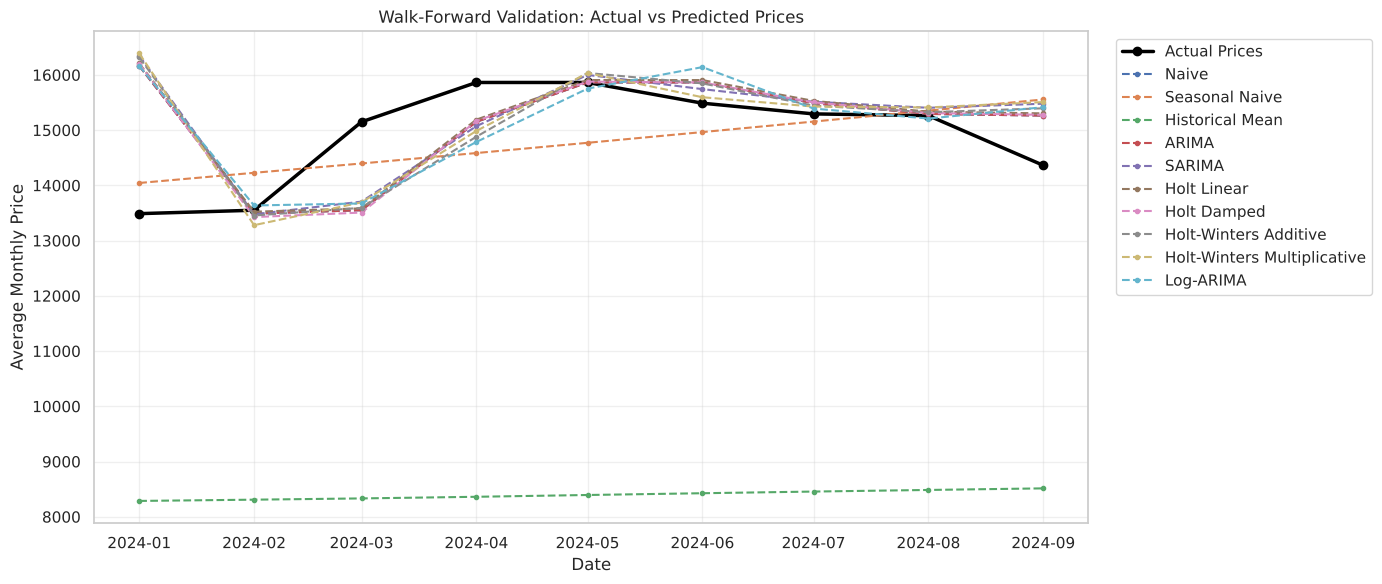

In [84]:
plt.figure(figsize=(14, 6))

plt.plot(
    wf_actual.index,
    wf_actual,
    label="Actual Prices",
    color="black",
    linewidth=2.5,
    marker="o"
)

for model_name in model_forecasts.keys():

    plt.plot(
        walk_forward_results.index,
        walk_forward_results[model_name],
        label=model_name,
        linestyle="--",
        marker="."
    )

plt.title("Walk-Forward Validation: Actual vs Predicted Prices")
plt.xlabel("Date")
plt.ylabel("Average Monthly Price")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 7.8 Horizon-Matched Rolling-Origin Evaluation (12 steps ahead)

The task is a **12-month-ahead** forecast, so one-step-ahead accuracy is
not the right yardstick. Here each model is fitted on all data up to a
forecast origin and asked to forecast the following 12 months. This is
repeated for several origins and the metrics are averaged.

Origins (last training month): **Sep 2022, Mar 2023, Sep 2023, Sep 2024**.
The last origin is the original holdout. The 12 target months are kept
inside the available data; targets that fall inside the interpolated
period (Jun 2021 – Nov 2023) are flagged so that results can be read
with that in mind.

The model with the lowest **mean RMSE across origins** is selected as the
final model.


In [85]:
rolling_origins = pd.to_datetime(["2022-09-01", "2023-03-01", "2023-09-01", "2024-09-01"])
horizon = 12

full_series = clean_df["avg_monthly_price"].astype(float).asfreq("MS")

rolling_rows = []
rolling_forecasts = {}   # (origin, model) -> pd.Series

for origin in rolling_origins:
    history = full_series.loc[:origin]
    target_index = pd.date_range(origin + pd.offsets.MonthBegin(1), periods=horizon, freq="MS")
    actual = full_series.loc[target_index]
    interpolated_targets = int(copied_mask.reindex(target_index).fillna(False).sum())

    for name in MODEL_NAMES:
        try:
            pred = pd.Series(fit_forecast(name, history, horizon), index=target_index)
        except Exception as error:
            print(f"Skipped {name} at origin {origin:%b %Y}: {error}")
            continue
        rolling_forecasts[(origin, name)] = pred
        metrics = evaluate_forecast(actual, pred)
        rolling_rows.append({
            "Origin": origin.strftime("%b %Y"),
            "Model": name,
            "Interpolated Targets": interpolated_targets,
            **metrics
        })

rolling_results = pd.DataFrame(rolling_rows)

print("12-STEP-AHEAD METRICS BY ORIGIN")
display(
    rolling_results.pivot(index="Model", columns="Origin", values="RMSE")
    [[o.strftime("%b %Y") for o in rolling_origins]].round(1)
)

rolling_summary = (
    rolling_results.groupby("Model")[["MAE", "RMSE", "MAPE (%)"]]
    .mean()
    .sort_values("RMSE")
)
rolling_summary["Origins"] = rolling_results.groupby("Model").size()

print("\nMEAN 12-STEP-AHEAD PERFORMANCE ACROSS ORIGINS")
display(rolling_summary.round(2))


12-STEP-AHEAD METRICS BY ORIGIN


Origin,Sep 2022,Mar 2023,Sep 2023,Sep 2024
Model,,,,
ARIMA,1332.6,1035.0,948.8,1565.7
Historical Mean,6711.6,7088.3,7053.0,5478.4
Holt Damped,1229.8,984.4,1009.1,1568.8
Holt Linear,1070.1,923.5,1118.4,1587.4
Holt-Winters Additive,1250.8,1024.9,1005.3,1528.1
Holt-Winters Multiplicative,1358.1,1115.2,984.3,1510.0
Log-ARIMA,1335.8,1034.1,947.7,1562.7
Naive,1332.6,1035.0,948.8,1565.7
SARIMA,1084.7,981.9,1130.3,1573.3



MEAN 12-STEP-AHEAD PERFORMANCE ACROSS ORIGINS


,MAE,RMSE,MAPE (%),Origins
Model,,,,
Holt Linear,940.79,1174.84,6.73,4
SARIMA,966.00,1192.54,6.90,4
Holt Damped,964.91,1198.02,6.85,4
Holt-Winters Additive,969.72,1202.24,6.84,4
Log-ARIMA,984.03,1220.08,6.95,4
Naive,984.86,1220.53,6.96,4
ARIMA,984.86,1220.53,6.96,4
Holt-Winters Multiplicative,1003.13,1241.87,7.05,4
Seasonal Naive,1670.33,1818.84,11.56,4


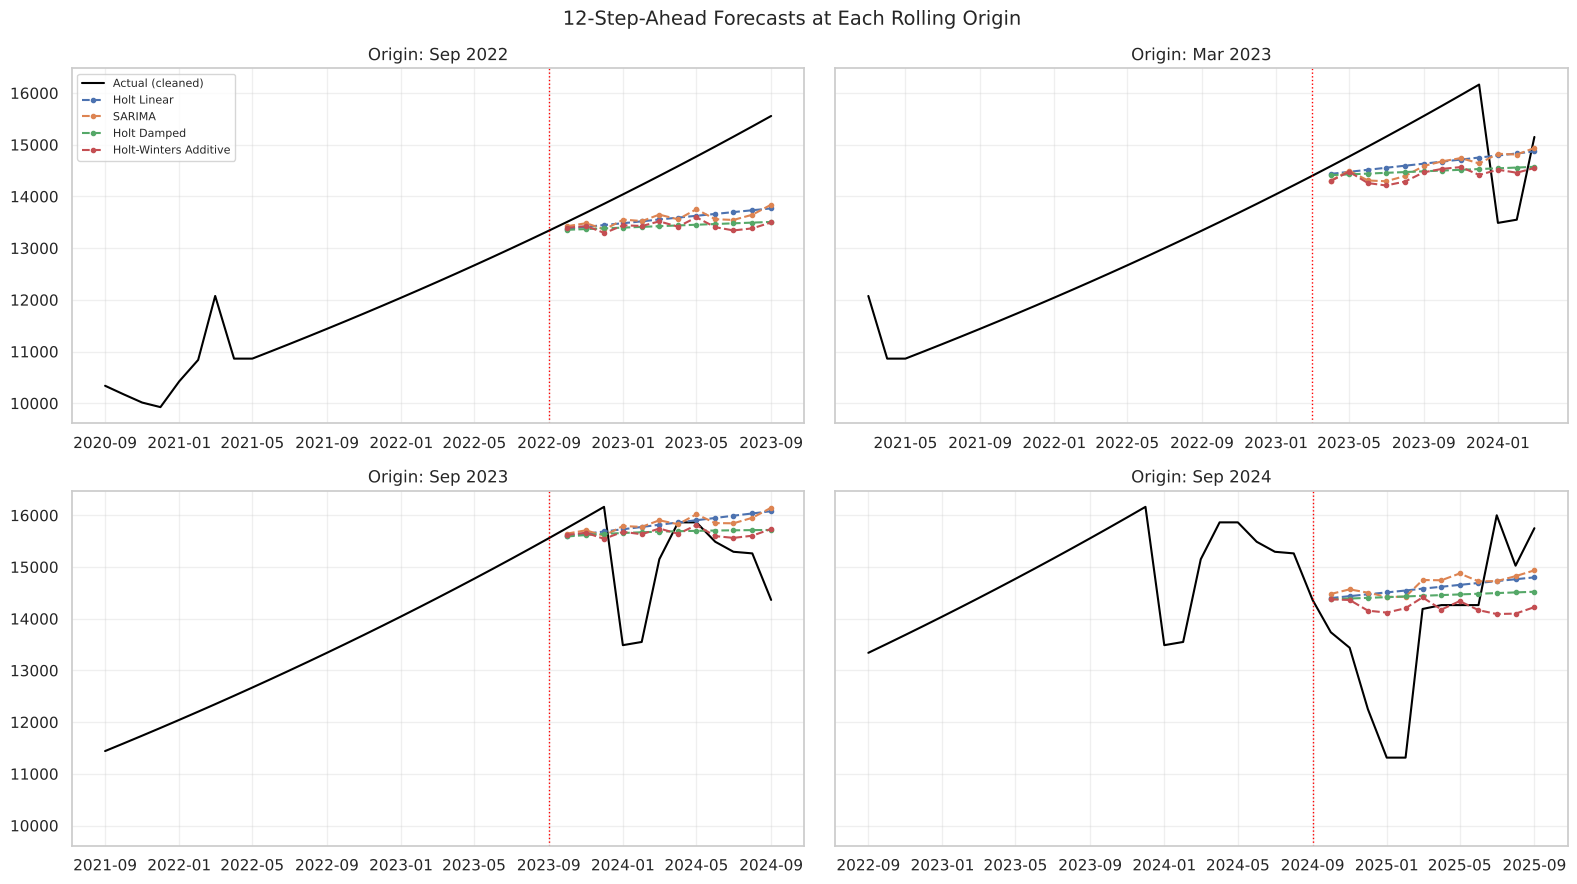

In [86]:
# Visualise the 12-step forecasts for every origin (top 4 models by mean RMSE)
top_models = rolling_summary.index[:4].tolist()

fig, axes = plt.subplots(2, 2, figsize=(16, 9), sharey=True)

for ax, origin in zip(axes.ravel(), rolling_origins):
    target_index = pd.date_range(origin + pd.offsets.MonthBegin(1), periods=horizon, freq="MS")
    context = full_series.loc[origin - pd.offsets.MonthBegin(24): target_index[-1]]
    ax.plot(context.index, context, color="black", linewidth=1.5, label="Actual (cleaned)")
    for name in top_models:
        if (origin, name) in rolling_forecasts:
            ax.plot(target_index, rolling_forecasts[(origin, name)], linestyle="--", marker=".", label=name)
    ax.axvline(origin, color="red", linestyle=":", linewidth=1)
    ax.set_title(f"Origin: {origin:%b %Y}")
    ax.grid(alpha=0.3)

axes[0, 0].legend(fontsize=8)
fig.suptitle("12-Step-Ahead Forecasts at Each Rolling Origin", fontsize=14)
plt.tight_layout()
plt.show()


### 7.9 Sensitivity to the Interpolated Observations

Thirty observations (12% of the data, Jun 2021 – Nov 2023) were replaced
by a smooth log-linear interpolation. Two checks are made to see how
much the model ranking depends on this choice:

**(a) Raw data instead of interpolation.** Models are retrained on the
original series with the copied block left in place, and evaluated on
the same 12-month holdout.

**(b) Post-gap data only.** Level/trend models are trained only on the
genuine observations after the gap (Dec 2023 – Sep 2024, 10 points).
Seasonal models cannot be fitted on so few points and are skipped.

In addition, the Seasonal Naive walk-forward score from Section 7.7 is
decomposed to show that it is entirely driven by interpolated inputs.


In [87]:
# (a) Raw data with the copied block retained
raw_train = df["avg_monthly_price"].astype(float).asfreq("MS").iloc[:-forecast_horizon]

raw_metrics = {}
for name in MODEL_NAMES:
    try:
        pred = pd.Series(fit_forecast(name, raw_train, len(test)), index=test.index)
        raw_metrics[name] = evaluate_forecast(test, pred)
    except Exception as error:
        print(f"Raw data – skipped {name}: {error}")

raw_metrics = pd.DataFrame(raw_metrics).T

# (b) Post-gap data only (genuine observations after the interpolated block)
post_gap_train = train.loc["2023-12-01":]

post_gap_metrics = {}
for name in MODEL_NAMES:
    try:
        pred = pd.Series(fit_forecast(name, post_gap_train, len(test)), index=test.index)
        post_gap_metrics[name] = evaluate_forecast(test, pred)
    except Exception as error:
        print(f"Post-gap – skipped {name}: {error}")

post_gap_metrics = pd.DataFrame(post_gap_metrics).T

sensitivity = pd.DataFrame({
    "RMSE (interpolated train)": all_model_metrics["RMSE"],
    "RMSE (raw train, block kept)": raw_metrics["RMSE"],
    "RMSE (post-gap train only)": post_gap_metrics["RMSE"],
}).sort_values("RMSE (interpolated train)")

print("HOLDOUT RMSE UNDER DIFFERENT TREATMENTS OF THE COPIED BLOCK")
display(sensitivity.round(2))

print("\nRANK OF EACH MODEL UNDER EACH TREATMENT (1 = best)")
display(sensitivity.rank(method="min").astype("Int64"))


Post-gap – skipped Seasonal Naive: Seasonal Naive needs at least 12 observations, got 10
Post-gap – skipped SARIMA: SARIMA needs at least 30 observations, got 10
Post-gap – skipped Holt-Winters Additive: Holt-Winters Additive needs at least 30 observations, got 10
Post-gap – skipped Holt-Winters Multiplicative: Holt-Winters Multiplicative needs at least 30 observations, got 10
HOLDOUT RMSE UNDER DIFFERENT TREATMENTS OF THE COPIED BLOCK


,RMSE (interpolated train),"RMSE (raw train, block kept)",RMSE (post-gap train only)
Holt-Winters Multiplicative,1509.97,1920.64,NaN
Holt-Winters Additive,1528.06,1747.83,NaN
Log-ARIMA,1562.74,1680.42,2452.94
ARIMA,1565.74,1565.74,1565.74
Naive,1565.74,1565.74,1565.74
Holt Damped,1568.83,1580.01,2057.63
SARIMA,1573.32,2205.72,NaN
Holt Linear,1587.35,1603.08,2135.88
Seasonal Naive,1947.09,2921.06,NaN
Historical Mean,5478.42,6368.13,1915.73



RANK OF EACH MODEL UNDER EACH TREATMENT (1 = best)


,RMSE (interpolated train),"RMSE (raw train, block kept)",RMSE (post-gap train only)
Holt-Winters Multiplicative,1,7,<NA>
Holt-Winters Additive,2,6,<NA>
Log-ARIMA,3,5,6
ARIMA,4,1,1
Naive,4,1,1
Holt Damped,6,3,4
SARIMA,7,8,<NA>
Holt Linear,8,4,5
Seasonal Naive,9,9,<NA>
Historical Mean,10,10,3


In [88]:
# Decompose the Seasonal Naive walk-forward result
sn_inputs = pd.DataFrame({
    "Forecast Month": walk_forward_results.index.strftime("%b %Y"),
    "Input Month (t-12)": (walk_forward_results.index - pd.DateOffset(months=12)).strftime("%b %Y"),
    "Input Was Interpolated": copied_mask.reindex(
        walk_forward_results.index - pd.DateOffset(months=12)).to_numpy(),
    "Seasonal Naive Forecast": walk_forward_results["Seasonal Naive"].to_numpy(),
    "Actual": walk_forward_results["Actual"].to_numpy(),
}).set_index("Forecast Month")

print("SEASONAL NAIVE WALK-FORWARD INPUTS")
display(sn_inputs.round(2))

share = sn_inputs["Input Was Interpolated"].mean() * 100
print(f"\nShare of Seasonal Naive walk-forward inputs that were interpolated: {share:.0f}%")
print("=> Its walk-forward MAPE measures how well the interpolation line tracks 2024, "
      "not seasonal skill. It is therefore not used for model selection.")


SEASONAL NAIVE WALK-FORWARD INPUTS


,Input Month (t-12),Input Was Interpolated,Seasonal Naive Forecast,Actual
Forecast Month,,,,
Jan 2024,Jan 2023,True,14043.12,13488.0
Feb 2024,Feb 2023,True,14227.57,13550.0
Mar 2024,Mar 2023,True,14396.25,15150.0
Apr 2024,Apr 2023,True,14585.34,15863.0
May 2024,May 2023,True,14770.69,15863.0
Jun 2024,Jun 2023,True,14964.69,15488.0
Jul 2024,Jul 2023,True,15154.87,15294.0
Aug 2024,Aug 2023,True,15353.92,15263.0
Sep 2024,Sep 2023,True,15555.58,14363.0



Share of Seasonal Naive walk-forward inputs that were interpolated: 100%
=> Its walk-forward MAPE measures how well the interpolation line tracks 2024, not seasonal skill. It is therefore not used for model selection.


#### 7.9.1 Sensitivity Conclusion

The sensitivity tables above show whether the ranking of the leading
models is stable when the copied block is (a) left in place or
(b) excluded entirely. Models whose rank changes materially between
treatments owe their holdout performance partly to the cleaning
decision; models that stay near the top are robust to it.

The Seasonal Naive walk-forward score is 100% driven by interpolated
inputs and is disregarded for selection.

Final model selection (Section 8.1) is based on the horizon-matched
rolling-origin evaluation of Section 7.8, cross-checked against this
sensitivity analysis.


### 8.1 Final Model Selection

Models were compared on three evaluations:

1. a single chronological 12-month holdout (Section 7.6),
2. one-step-ahead expanding-window walk-forward validation (Section 7.7),
3. a **horizon-matched** 12-step-ahead rolling-origin evaluation
   across four origins (Section 7.8), cross-checked by the sensitivity
   analysis of Section 7.9.

Because the deliverable is a 12-month forecast, selection is based on
the **mean 12-step RMSE across rolling origins** (evaluation 3). The
selection is made programmatically below so that the final forecast
always corresponds to the evidence in the tables above.


In [89]:
# Programmatic final model selection: lowest mean 12-step RMSE across rolling origins
# (only models that could be evaluated at every origin are eligible)
eligible = rolling_summary[rolling_summary["Origins"] == len(rolling_origins)]
final_model_name = eligible["RMSE"].idxmin()

holdout_rank = all_model_metrics["RMSE"].rank().astype(int)

print("FINAL MODEL SELECTION")
print("-" * 55)
print("Selected model:", final_model_name)
print(f"Mean 12-step RMSE across origins: {eligible.loc[final_model_name, 'RMSE']:.2f}")
print(f"Mean 12-step MAPE across origins: {eligible.loc[final_model_name, 'MAPE (%)']:.2f}%")
print(f"Holdout (Oct 2024 – Sep 2025) RMSE: {all_model_metrics.loc[final_model_name, 'RMSE']:.2f} "
      f"(rank {holdout_rank[final_model_name]} of {len(all_model_metrics)})")

runner_up = eligible["RMSE"].drop(final_model_name).idxmin()
gap = (eligible.loc[runner_up, "RMSE"] / eligible.loc[final_model_name, "RMSE"] - 1) * 100
print(f"Runner-up: {runner_up} (mean RMSE {gap:.1f}% higher)")

if gap < 5:
    print("\nNote: the margin over the runner-up is small (<5%); the ranking should be "
          "treated as indicative rather than decisive.")


FINAL MODEL SELECTION
-------------------------------------------------------
Selected model: Holt Linear
Mean 12-step RMSE across origins: 1174.84
Mean 12-step MAPE across origins: 6.73%
Holdout (Oct 2024 – Sep 2025) RMSE: 1587.35 (rank 8 of 10)
Runner-up: SARIMA (mean RMSE 1.5% higher)

Note: the margin over the runner-up is small (<5%); the ranking should be treated as indicative rather than decisive.


### 8.2 Final Data Preparation and Model Fitting

The cleaned dataset (all 249 monthly observations, Jan 2005 – Sep 2025)
is used to fit the selected model. The model specification is identical
to the one evaluated above (shared registry); only its parameters are
re-estimated on the full history.


In [90]:
# Prepare the final cleaned price series
final_training_series = (
    clean_df["avg_monthly_price"]
    .astype(float)
    .asfreq("MS")
)

# Validate the final dataset
print("FINAL TRAINING DATASET VALIDATION")
print("-" * 50)

print("Total observations:", len(final_training_series))
print("Start date:", final_training_series.index.min())
print("End date:", final_training_series.index.max())

print("Missing values:", final_training_series.isna().sum())
print("Data type:", final_training_series.dtype)

print(
    "Monthly frequency:",
    final_training_series.index.freq
)

# Check data integrity
assert len(final_training_series) == 249
assert final_training_series.isna().sum() == 0
assert final_training_series.index.is_monotonic_increasing

print("\nAll validation checks passed.")

FINAL TRAINING DATASET VALIDATION
--------------------------------------------------
Total observations: 249
Start date: 2005-01-01 00:00:00
End date: 2025-09-01 00:00:00
Missing values: 0
Data type: float64
Monthly frequency: <MonthBegin>

All validation checks passed.


#### 8.2.2 Identify the forecast origin

In [91]:
# Identify the forecast origin
final_origin = final_training_series.index[-1]
final_reference_price = float(final_training_series.iloc[-1])

print("FINAL MODEL REFERENCE")
print("-" * 45)
print("Last observed month:", final_origin.strftime("%B %Y"))
print("Last observed price:", final_reference_price)
print("Forecast horizon: 12 months")


FINAL MODEL REFERENCE
---------------------------------------------
Last observed month: September 2025
Last observed price: 15750.0
Forecast horizon: 12 months


#### 8.2.3 Final model configuration

In [92]:
forecast_horizon = 12

print("FINAL MODEL CONFIGURATION")
print("-" * 45)
print("Selected model:", final_model_name)
print("Training observations:", len(final_training_series))
print("Forecast horizon:", forecast_horizon)
print("Forecast origin:", final_origin.strftime("%B %Y"))
print("\nFinal model is ready for forecasting.")


FINAL MODEL CONFIGURATION
---------------------------------------------
Selected model: Holt Linear
Training observations: 249
Forecast horizon: 12
Forecast origin: September 2025

Final model is ready for forecasting.


### 8.3 Generate the 12-Month Forecast with Prediction Intervals

The selected model is fitted on the full cleaned history and used to
forecast October 2025 – September 2026.

Point forecasts are accompanied by **80% and 95% prediction intervals**:

* Naive / Seasonal Naive / Historical Mean: analytic intervals based on
  the standard deviation of the model's in-sample one-step errors,
  widened with √h for the random walk. Months inside the interpolated
  block are excluded from the error estimate, because the interpolation
  is artificially smooth and would understate volatility.
* ARIMA / SARIMA / Log-ARIMA: model-based intervals from statsmodels
  (log-model intervals are back-transformed).
* Exponential smoothing models: simulation-based intervals
  (2,000 bootstrap paths of the fitted state-space model).


In [93]:
from scipy import stats

def forecast_with_intervals(name, history, steps, levels=(0.80, 0.95), exclude_mask=None):
    """Return a DataFrame with point forecast and lower/upper bounds for each level."""
    history = history.astype(float).asfreq("MS")
    future_index = pd.date_range(history.index[-1] + pd.offsets.MonthBegin(1), periods=steps, freq="MS")
    mean = fit_forecast(name, history, steps)
    out = pd.DataFrame({"Forecast": mean}, index=future_index)
    h = np.arange(1, steps + 1)

    if name in ("Naive", "Seasonal Naive", "Historical Mean"):
        if name == "Naive":
            resid = history.diff()
            scale = np.sqrt(h)
        elif name == "Seasonal Naive":
            resid = history - history.shift(12)
            scale = np.sqrt(np.floor((h - 1) / 12) + 1)
        else:
            resid = history - history.mean()
            scale = np.ones(steps)
        if exclude_mask is not None:
            bad = exclude_mask.reindex(history.index).fillna(False)
            bad = bad | bad.shift(1, fill_value=False) | (bad.shift(12, fill_value=False) if name == "Seasonal Naive" else False)
            resid = resid[~bad]
        sigma = resid.dropna().std()
        for level in levels:
            z = stats.norm.ppf(0.5 + level / 2)
            out[f"Lower {int(level*100)}%"] = mean - z * sigma * scale
            out[f"Upper {int(level*100)}%"] = mean + z * sigma * scale

    elif name in ("ARIMA", "SARIMA", "Log-ARIMA"):
        fitted = _fit_model(name, history)
        for level in levels:
            ci = fitted.get_forecast(steps).conf_int(alpha=1 - level)
            lo, hi = ci.iloc[:, 0].to_numpy(), ci.iloc[:, 1].to_numpy()
            if name == "Log-ARIMA":
                lo, hi = np.exp(lo), np.exp(hi)
            out[f"Lower {int(level*100)}%"] = lo
            out[f"Upper {int(level*100)}%"] = hi

    else:  # exponential smoothing family: simulation-based intervals
        fitted = _fit_model(name, history)
        with warnings.catch_warnings():
            warnings.simplefilter("ignore")
            sims = fitted.simulate(steps, repetitions=2000, error="add", random_state=42)
        sims = np.asarray(sims)
        for level in levels:
            q = (1 - level) / 2
            out[f"Lower {int(level*100)}%"] = np.quantile(sims, q, axis=1)
            out[f"Upper {int(level*100)}%"] = np.quantile(sims, 1 - q, axis=1)

    return out


final_forecast_df = forecast_with_intervals(
    final_model_name, final_training_series, forecast_horizon, exclude_mask=copied_mask
)
final_forecast_df.index.name = "date"

future_dates = final_forecast_df.index
final_forecast = final_forecast_df["Forecast"].rename("Forecasted Price")

print(f"FINAL 12-MONTH FORECAST – {final_model_name}")
print("-" * 60)
display(final_forecast_df.round(2))


FINAL 12-MONTH FORECAST – Holt Linear
------------------------------------------------------------


,Forecast,Lower 80%,Upper 80%,Lower 95%,Upper 95%
date,,,,,
2025-10-01,15790.19,15099.88,16534.92,14736.03,16951.49
2025-11-01,15830.39,14841.82,16865.79,14329.61,17448.10
2025-12-01,15870.58,14630.20,17145.54,13964.48,17780.10
2026-01-01,15910.77,14459.65,17398.11,13687.86,18220.06
2026-02-01,15950.96,14356.03,17549.70,13569.64,18563.52
2026-03-01,15991.16,14241.59,17744.99,13291.88,18745.07
2026-04-01,16031.35,14115.58,17935.91,13126.13,18982.66
2026-05-01,16071.54,14044.22,18185.98,12892.90,19280.48
2026-06-01,16111.74,13972.37,18349.48,12828.53,19471.38


#### 8.3.2 Create the final forecast table

In [94]:
# Final forecast report table
final_forecast_table = pd.DataFrame({
    "Forecast Month": future_dates.strftime("%B %Y"),
    "Forecasted Price": final_forecast.to_numpy().round(0),
    "Lower 80%": final_forecast_df["Lower 80%"].to_numpy().round(0),
    "Upper 80%": final_forecast_df["Upper 80%"].to_numpy().round(0),
    "Lower 95%": final_forecast_df["Lower 95%"].to_numpy().round(0),
    "Upper 95%": final_forecast_df["Upper 95%"].to_numpy().round(0),
    "Forecasting Model": final_model_name
})

print("FINAL MONTHLY PRICE FORECAST")
print("-" * 50)
display(final_forecast_table)

# Save the deliverable
final_forecast_table.to_csv("monthly_price_forecast.csv", index=False)
print("Saved: monthly_price_forecast.csv")


FINAL MONTHLY PRICE FORECAST
--------------------------------------------------


,Forecast Month,Forecasted Price,Lower 80%,Upper 80%,Lower 95%,Upper 95%,Forecasting Model
0,October 2025,15790.0,15100.0,16535.0,14736.0,16951.0,Holt Linear
1,November 2025,15830.0,14842.0,16866.0,14330.0,17448.0,Holt Linear
2,December 2025,15871.0,14630.0,17146.0,13964.0,17780.0,Holt Linear
3,January 2026,15911.0,14460.0,17398.0,13688.0,18220.0,Holt Linear
4,February 2026,15951.0,14356.0,17550.0,13570.0,18564.0,Holt Linear
5,March 2026,15991.0,14242.0,17745.0,13292.0,18745.0,Holt Linear
6,April 2026,16031.0,14116.0,17936.0,13126.0,18983.0,Holt Linear
7,May 2026,16072.0,14044.0,18186.0,12893.0,19280.0,Holt Linear
8,June 2026,16112.0,13972.0,18349.0,12829.0,19471.0,Holt Linear
9,July 2026,16152.0,13883.0,18485.0,12681.0,19814.0,Holt Linear


Saved: monthly_price_forecast.csv


#### 8.3.3 Validate the forecast

In [95]:
# Validate generated forecasts
print("FORECAST VALIDATION")
print("-" * 45)
print("Forecast observations:", len(final_forecast))
print("First forecast month:", final_forecast.index.min())
print("Last forecast month:", final_forecast.index.max())
print("Missing predictions:", int(final_forecast_df.isna().sum().sum()))
print("Forecast dates are monthly:", pd.infer_freq(final_forecast.index))
print("All forecasts positive:", bool((final_forecast > 0).all()))
print("Intervals ordered (lower <= forecast <= upper):",
      bool(((final_forecast_df["Lower 95%"] <= final_forecast_df["Forecast"]) &
            (final_forecast_df["Forecast"] <= final_forecast_df["Upper 95%"])).all()))
print("Intervals widen with horizon (95%):",
      bool((final_forecast_df["Upper 95%"] - final_forecast_df["Lower 95%"]).diff().dropna().ge(-1e-6).all()))


FORECAST VALIDATION
---------------------------------------------
Forecast observations: 12
First forecast month: 2025-10-01 00:00:00
Last forecast month: 2026-09-01 00:00:00
Missing predictions: 0
Forecast dates are monthly: MS
All forecasts positive: True
Intervals ordered (lower <= forecast <= upper): True
Intervals widen with horizon (95%): True


### 8.3.4 Final Forecast Generation Conclusion

The selected model generated 12 monthly price predictions for
October 2025 – September 2026 using all historical information
available through September 2025, together with 80% and 95%
prediction intervals.

The forecast contains no missing predictions and maintains a
continuous monthly frequency. The widening intervals make explicit
that uncertainty grows with the horizon.

These values are estimates and should not be interpreted as actual
observed prices.


### 8.4 Final Forecast Visualization

The historical cleaned monthly prices are shown together with the
final 12-month forecast and its 80% / 95% prediction intervals.


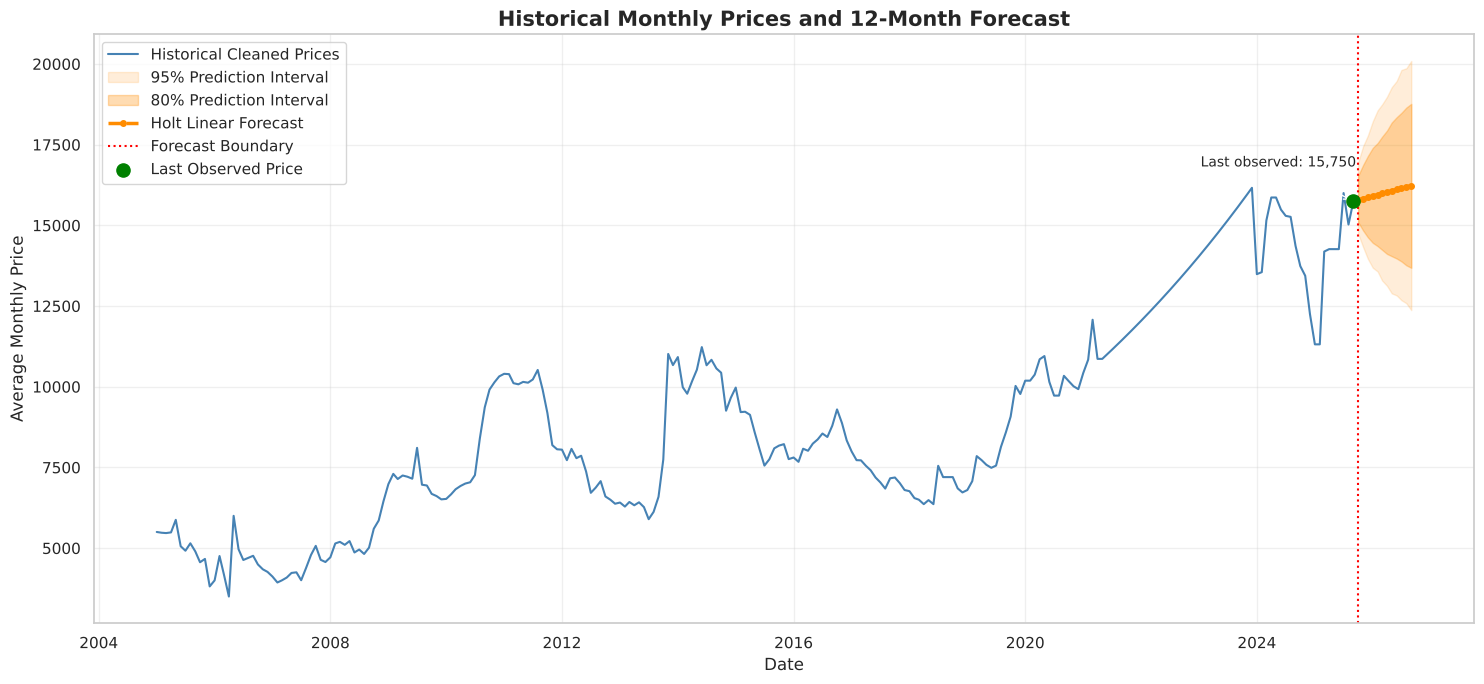

In [96]:
# Forecast line connected to the last historical observation
forecast_line = pd.concat([final_training_series.iloc[-1:], final_forecast])

fig, ax = plt.subplots(figsize=(15, 7))

ax.plot(final_training_series.index, final_training_series.values,
        label="Historical Cleaned Prices", color="steelblue", linewidth=1.5)

# Prediction intervals
ax.fill_between(future_dates, final_forecast_df["Lower 95%"], final_forecast_df["Upper 95%"],
                color="darkorange", alpha=0.15, label="95% Prediction Interval")
ax.fill_between(future_dates, final_forecast_df["Lower 80%"], final_forecast_df["Upper 80%"],
                color="darkorange", alpha=0.30, label="80% Prediction Interval")

ax.plot(forecast_line.index, forecast_line.values, label=f"{final_model_name} Forecast",
        color="darkorange", linewidth=2.5, linestyle="--", marker="o", markersize=4)

ax.axvline(future_dates[0], color="red", linestyle=":", linewidth=1.5, label="Forecast Boundary")
ax.scatter(final_origin, final_reference_price, color="green", s=90, zorder=5, label="Last Observed Price")
ax.annotate(f"Last observed: {final_reference_price:,.0f}",
            xy=(final_origin, final_reference_price), xytext=(-110, 25),
            textcoords="offset points", arrowprops=dict(arrowstyle="->"), fontsize=10)

ax.set_title("Historical Monthly Prices and 12-Month Forecast", fontsize=15, fontweight="bold")
ax.set_xlabel("Date")
ax.set_ylabel("Average Monthly Price")
ax.legend(loc="upper left")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


#### 8.4.2 Visualize Forecasted Values Separately

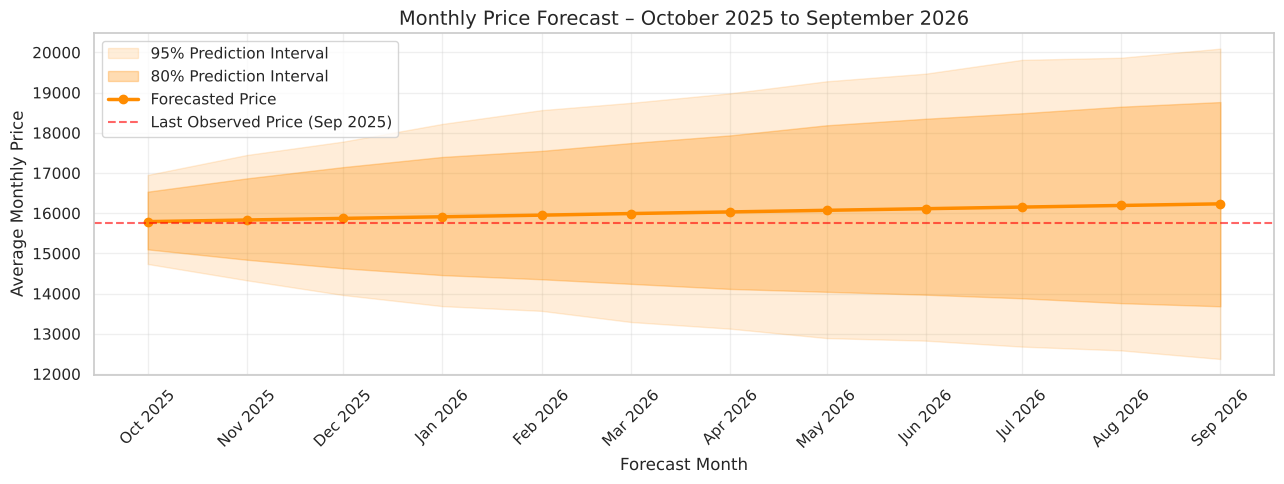

In [97]:
plt.figure(figsize=(13, 5))

plt.fill_between(future_dates, final_forecast_df["Lower 95%"], final_forecast_df["Upper 95%"],
                 color="darkorange", alpha=0.15, label="95% Prediction Interval")
plt.fill_between(future_dates, final_forecast_df["Lower 80%"], final_forecast_df["Upper 80%"],
                 color="darkorange", alpha=0.30, label="80% Prediction Interval")
plt.plot(final_forecast.index, final_forecast.values, color="darkorange", marker="o",
         linewidth=2.5, label="Forecasted Price")
plt.axhline(final_reference_price, color="red", linestyle="--", alpha=0.6,
            label="Last Observed Price (Sep 2025)")

plt.title("Monthly Price Forecast – October 2025 to September 2026", fontsize=14)
plt.xlabel("Forecast Month")
plt.ylabel("Average Monthly Price")
plt.xticks(future_dates, future_dates.strftime("%b %Y"), rotation=45)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()


### 8.5 Forecast Interpretation

The table below compares each forecast month with the last observed
price (September 2025) and summarises the width of the prediction
intervals. The printed summary is generated from the actual results so
that it always matches the tables above.

Limitations to keep in mind:

* 12% of the training history (Jun 2021 – Nov 2023) is interpolated,
  not observed; Section 7.9 quantifies how much this matters.
* The series shows large, abrupt level shifts (e.g. Dec 2023); no
  statistical model trained on this history can anticipate such shocks.
* The model does not use external drivers (demand, supply, policy,
  exchange rates); the forecast is a statistical baseline scenario,
  not a guaranteed future price.


In [98]:
forecast_interpretation = pd.DataFrame({
    "Forecasted Price": final_forecast,
    "Change from Last Observed": final_forecast - final_reference_price,
    "Percentage Change (%)": (final_forecast / final_reference_price - 1) * 100,
    "80% Interval Width": final_forecast_df["Upper 80%"] - final_forecast_df["Lower 80%"],
    "95% Interval Width": final_forecast_df["Upper 95%"] - final_forecast_df["Lower 95%"],
})
forecast_interpretation["Forecast Direction"] = np.where(
    forecast_interpretation["Percentage Change (%)"] > 0.5, "Increase",
    np.where(forecast_interpretation["Percentage Change (%)"] < -0.5, "Decrease", "Broadly flat")
)

print("FORECAST INTERPRETATION")
display(forecast_interpretation.round(2))

avg_fc = final_forecast.mean()
end_fc = final_forecast.iloc[-1]
print("\nSUMMARY")
print("-" * 55)
print(f"Model: {final_model_name}")
print(f"Last observed price (Sep 2025): {final_reference_price:,.0f}")
print(f"Average forecast Oct 2025 – Sep 2026: {avg_fc:,.0f} ({(avg_fc/final_reference_price-1)*100:+.1f}%)")
print(f"Forecast for Sep 2026: {end_fc:,.0f} ({(end_fc/final_reference_price-1)*100:+.1f}%)")
print(f"95% interval for Sep 2026: {final_forecast_df['Lower 95%'].iloc[-1]:,.0f} – "
      f"{final_forecast_df['Upper 95%'].iloc[-1]:,.0f}")


FORECAST INTERPRETATION


,Forecasted Price,Change from Last Observed,Percentage Change (%),80% Interval Width,95% Interval Width,Forecast Direction
date,,,,,,
2025-10-01,15790.19,40.19,0.26,1435.05,2215.46,Broadly flat
2025-11-01,15830.39,80.39,0.51,2023.97,3118.50,Increase
2025-12-01,15870.58,120.58,0.77,2515.34,3815.62,Increase
2026-01-01,15910.77,160.77,1.02,2938.46,4532.20,Increase
2026-02-01,15950.96,200.96,1.28,3193.67,4993.88,Increase
2026-03-01,15991.16,241.16,1.53,3503.40,5453.19,Increase
2026-04-01,16031.35,281.35,1.79,3820.34,5856.53,Increase
2026-05-01,16071.54,321.54,2.04,4141.75,6387.58,Increase
2026-06-01,16111.74,361.74,2.30,4377.11,6642.85,Increase



SUMMARY
-------------------------------------------------------
Model: Holt Linear
Last observed price (Sep 2025): 15,750
Average forecast Oct 2025 – Sep 2026: 16,011 (+1.7%)
Forecast for Sep 2026: 16,232 (+3.1%)
95% interval for Sep 2026: 12,373 – 20,094
